In [688]:
# =================================
# 1. IMPORTING LIBRARIES
# =================================

import numpy as np #For numerical computations and linear algebra
import pandas as pd #For data manipulation and analysis
import matplotlib.pyplot as plt #For creating basic visualizations
import seaborn as sns #For statistical data visualization
import plotly.express as px #For interactive visualizations
import scipy.stats as stats #For statistical analysis and hypothesis testing
import os #For file and directory management

print("\nAll libraries imported successfully!")
print("\n----------------------------")

# =================================
# 2. DATASET DISCOVERY
# =================================

# Find all CSV files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print("\n",os.path.join(dirname, filename))

# Define the competition dataset directory
DATA_DIR = '/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027'

# Load player information
players_df = pd.read_csv(os.path.join(DATA_DIR, 'players.csv'))

# Load player-play information
player_play_df = pd.read_csv(os.path.join(DATA_DIR, 'player_play.csv'))

# Load player career success information
career_success_df = pd.read_csv(os.path.join(DATA_DIR, 'player_career_successes.csv'))

# Load game information
games_df = pd.read_csv(os.path.join(DATA_DIR, 'games.csv'))

# Load 2023 game tracking data
tracking_2023_df = pd.read_csv(os.path.join(DATA_DIR, 'game_tracking_2023.csv'))

# Load 2024 game tracking data
tracking_2024_df = pd.read_csv(os.path.join(DATA_DIR, 'game_tracking_2024.csv'))

# Load 2025 game tracking data
tracking_2025_df = pd.read_csv(os.path.join(DATA_DIR, 'game_tracking_2025.csv'))

# Load Combine tracking data
combine_tracking_df = pd.read_csv(os.path.join(DATA_DIR, 'combine_tracking.csv'))

# Load Combine results
combine_results_df = pd.read_csv(os.path.join(DATA_DIR, 'combine_results.csv'))

print("\nAll datasets loaded successfully!")


All libraries imported successfully!

----------------------------

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/players.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2023.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2025.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2024.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_tracking.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/games.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_career_successes.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_results.csv

 /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_play.csv

All datasets loaded successfully!


In [689]:
print("Players:", players_df.shape)
print("Player Play:", player_play_df.shape)
print("Career Success:", career_success_df.shape)
print("Games:", games_df.shape)
print("Tracking 2023:", tracking_2023_df.shape)
print("Tracking 2024:", tracking_2024_df.shape)
print("Tracking 2025:", tracking_2025_df.shape)
print("Combine Tracking:", combine_tracking_df.shape)
print("Combine Results:", combine_results_df.shape)

Players: (510, 10)
Player Play: (314197, 64)
Career Success: (510, 9)
Games: (1002, 7)
Tracking 2023: (3665443, 12)
Tracking 2024: (7827944, 12)
Tracking 2025: (11160903, 12)
Combine Tracking: (463189, 14)
Combine Results: (510, 18)


In [690]:
#Identify the columns of all Dataset 
datasets = {
    'players': players_df,
    'player_play': player_play_df,
    'career_success': career_success_df,
    'games': games_df,
    'tracking_2023': tracking_2023_df,
    'tracking_2024': tracking_2024_df,
    'tracking_2025': tracking_2025_df,
    'combine_tracking': combine_tracking_df,
    'combine_results': combine_results_df
}

for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns.tolist())


players
['nfl_id', 'display_name', 'draft_year', 'nfl_position', 'birth_date', 'college_name', 'college_conference', 'draft_round', 'draft_pick_within_round', 'draft_overall_pick']

player_play
['game_id', 'play_id', 'team_abbr', 'nfl_id', 'lined_up_position', 'play_description', 'quarter', 'down', 'yards_to_go', 'possession_team', 'yardline_side', 'yardline_number', 'game_clock', 'pre_snap_home_score', 'pre_snap_visitor_score', 'play_direction', 'pre_snap_home_team_win_probability', 'pre_snap_visitor_team_win_probability', 'home_team_win_probability_added', 'visitor_team_win_probility_added', 'expected_points_added', 'expected_points', 'offense_formation', 'receiver_alignment', 'pass_result', 'pass_length', 'play_nullified_by_penalty', 'penalty_yards', 'pre_penalty_yards_gained', 'yards_gained', 'team_coverage_man_zone', 'team_coverage_type', 'in_motion_at_ball_snap', 'target', 'rec_yards', 'rush_yards', 'yards_after_catch', 'fumble', 'fumble_lost', 'route_ran', 'separation_at_pass_f

In [691]:
print("Players:", players_df['nfl_id'].is_unique)

print("Career Success:", career_success_df['nfl_id'].is_unique)

print("Games:", games_df['game_id'].is_unique)

print("Combine Results:", combine_results_df['nfl_id'].is_unique)

Players: True
Career Success: True
Games: True
Combine Results: True


In [692]:
print("Player Play:",
      player_play_df[['game_id', 'play_id', 'nfl_id']].duplicated().sum())

print("Tracking 2023:",
      tracking_2023_df[['game_id', 'play_id', 'nfl_id', 'time']].duplicated().sum())

print("Tracking 2024:",
      tracking_2024_df[['game_id', 'play_id', 'nfl_id', 'time']].duplicated().sum())

print("Tracking 2025:",
      tracking_2025_df[['game_id', 'play_id', 'nfl_id', 'time']].duplicated().sum())

print("Combine Tracking:",
      combine_tracking_df[['event_id', 'nfl_id', 'time', 'attempt']].duplicated().sum())

Player Play: 0
Tracking 2023: 0
Tracking 2024: 0
Tracking 2025: 0
Combine Tracking: 32095


In [693]:
combine_tracking_df['entity_type'].value_counts()

entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64

In [694]:
combine_tracking_df[
    combine_tracking_df.duplicated(
        subset=['event_id', 'nfl_id', 'time', 'attempt'],
        keep=False
    )
].head(10)

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
35608,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.100,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.293287,23.725736,0.648994,2.315843,0.004215,188.058773
35609,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.200,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.254023,23.629649,0.946230,2.640692,0.009361,186.249636
35610,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.300,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.245295,23.510948,1.260947,2.988490,0.014090,180.079805
35611,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.400,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.225001,23.367877,1.586478,3.709605,0.020474,170.012598
35612,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.500,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.276543,23.200551,1.858396,4.228436,0.028124,167.077898
35613,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.600,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.335805,23.004105,2.238687,4.363127,0.038751,159.233966
35614,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.700,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.434720,22.775627,2.668474,4.469495,0.053111,153.882232
35615,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.800,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.573006,22.522214,3.066658,4.550966,0.067005,148.760080
35616,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:16.900,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.756945,22.245824,3.487281,4.603311,0.083549,144.434089
35617,2025,20250228100500_1740789982046_000,58424,PLAYER,2025-03-01T00:46:17.000,SKILL_DRILLS_TE,OVER_SHOULDER_ADJUST,1,29.983991,21.954864,3.876617,4.633867,0.099117,140.204984


In [695]:
duplicate_rows = combine_tracking_df[
    combine_tracking_df.duplicated(
        subset=['event_id', 'nfl_id', 'time', 'attempt'],
        keep=False
    )
]

display(duplicate_rows['entity_type'].value_counts())

entity_type
PLAYER    32095
BALL      32095
Name: count, dtype: int64

In [696]:
combine_tracking_df.duplicated(
    subset=['event_id', 'nfl_id', 'time', 'attempt', 'entity_type']
).sum()

np.int64(0)

In [697]:
print("Player Play unique game-play pairs:",
      player_play_df[['game_id', 'play_id']].drop_duplicates().shape[0])

print("Total Player Play rows:", len(player_play_df))

Player Play unique game-play pairs: 114954
Total Player Play rows: 314197


In [698]:
print("Tracking 2023 rows:", len(tracking_2023_df))

print("Unique plays:",
      tracking_2023_df[['game_id', 'play_id']].drop_duplicates().shape[0])

Tracking 2023 rows: 3665443
Unique plays: 31690


In [699]:
tracking_plays = tracking_2023_df[
    ['game_id', 'play_id']
].drop_duplicates()

player_plays = player_play_df[
    ['game_id', 'play_id']
].drop_duplicates()

print("Tracking plays:", len(tracking_plays))

print("Matching plays:",
      tracking_plays.merge(
          player_plays,
          on=['game_id', 'play_id'],
          how='inner'
      ).shape[0])

Tracking plays: 31690
Matching plays: 31551


In [700]:
unmatched_plays = tracking_plays.merge(
    player_plays,
    on=['game_id', 'play_id'],
    how='left',
    indicator=True
)

unmatched_plays = unmatched_plays[
    unmatched_plays['_merge'] == 'left_only'
]

display(unmatched_plays.head(10))

,game_id,play_id,_merge
1322,2023122300,455,left_only
1964,2023111205,3116,left_only
2031,2023111900,3111,left_only
3180,2023092406,3425,left_only
3388,2023111210,1223,left_only
4994,2023101200,3737,left_only
5183,2023110500,3359,left_only
5837,2023110507,2820,left_only
5983,2023120304,3036,left_only
6268,2024011301,178,left_only


In [701]:
print("Unmatched plays:", len(unmatched_plays))

print("Unmatched games:",
      unmatched_plays['game_id'].nunique())

Unmatched plays: 139
Unmatched games: 68


> **"Out of 31,690 unique plays in 2023 tracking data, 31,551 matched with player_play data, while 139 plays across 68 games remained unmatched."**

In [702]:
tracking_2024_plays = tracking_2024_df[['game_id', 'play_id']].drop_duplicates()

print("Tracking 2024 plays:", len(tracking_2024_plays))

print("Matching plays:", tracking_2024_plays.merge(
    player_plays,
    on=['game_id', 'play_id'],
    how='inner'
).shape[0])

Tracking 2024 plays: 40331
Matching plays: 40282


In [703]:
tracking_2025_plays = tracking_2025_df[['game_id', 'play_id']].drop_duplicates()

print("Tracking 2025 plays:", len(tracking_2025_plays))

print("Matching plays:", tracking_2025_plays.merge(
    player_plays,
    on=['game_id', 'play_id'],
    how='inner'
).shape[0])

Tracking 2025 plays: 42544
Matching plays: 42530


In [704]:
unmatched_2023 = tracking_plays.merge(
    player_plays,
    on=['game_id', 'play_id'],
    how='left',
    indicator=True
)

unmatched_2023 = unmatched_2023[
    unmatched_2023['_merge'] == 'left_only'
]

print("2023 unmatched:", len(unmatched_2023))

2023 unmatched: 139


In [705]:
unmatched_2024 = tracking_2024_plays.merge(
    player_plays,
    on=['game_id', 'play_id'],
    how='left',
    indicator=True
)

unmatched_2024 = unmatched_2024[
    unmatched_2024['_merge'] == 'left_only'
]

print("2024 unmatched:", len(unmatched_2024))

2024 unmatched: 49


In [706]:
unmatched_2025 = tracking_2025_plays.merge(
    player_plays,
    on=['game_id', 'play_id'],
    how='left',
    indicator=True
)

unmatched_2025 = unmatched_2025[
    unmatched_2025['_merge'] == 'left_only'
]

print("2025 unmatched:", len(unmatched_2025))

2025 unmatched: 14


In [707]:
unmatched_2023['year'] = 2023
unmatched_2024['year'] = 2024
unmatched_2025['year'] = 2025

all_unmatched = pd.concat([
    unmatched_2023,
    unmatched_2024,
    unmatched_2025
], ignore_index=True)

print("Total unmatched:", len(all_unmatched))
display(all_unmatched.head())

Total unmatched: 202


,game_id,play_id,_merge,year
0,2023122300,455,left_only,2023
1,2023111205,3116,left_only,2023
2,2023111900,3111,left_only,2023
3,2023092406,3425,left_only,2023
4,2023111210,1223,left_only,2023


In [708]:
unmatched_games_check = all_unmatched.merge(
    games_df[['game_id', 'season']],
    on='game_id',
    how='left',
    indicator='game_match'
)

print(unmatched_games_check['game_match'].value_counts())

game_match
both          202
left_only       0
right_only      0
Name: count, dtype: int64


In [709]:
print(
    unmatched_games_check.groupby('year')['game_match']
    .value_counts()
)

year  game_match
2023  both          139
      left_only       0
      right_only      0
2024  both           49
      left_only       0
      right_only      0
2025  both           14
      left_only       0
      right_only      0
Name: count, dtype: int64


In [710]:
print("Combine Tracking unique players:",
      combine_tracking_df['nfl_id'].nunique())

print("Combine Results unique players:",
      combine_results_df['nfl_id'].nunique())

Combine Tracking unique players: 510
Combine Results unique players: 510


In [711]:
tracking_ids = set(combine_tracking_df['nfl_id'].unique())
results_ids = set(combine_results_df['nfl_id'].unique())

print("Common players:", len(tracking_ids & results_ids))
print("Only in Tracking:", len(tracking_ids - results_ids))
print("Only in Results:", len(results_ids - tracking_ids))

Common players: 510
Only in Tracking: 0
Only in Results: 0


In [712]:
combine_player_ids = set(combine_tracking_df['nfl_id'].unique())
players_ids = set(players_df['nfl_id'].unique())

print("Common players:", len(combine_player_ids & players_ids))
print("Only in Combine:", len(combine_player_ids - players_ids))
print("Only in Players:", len(players_ids - combine_player_ids))

Common players: 510
Only in Combine: 0
Only in Players: 0


In [713]:
nfl_2023_ids = set(tracking_2023_df['nfl_id'].dropna().unique())
players_ids = set(players_df['nfl_id'].dropna().unique())

print("NFL Tracking 2023 unique players:", len(nfl_2023_ids))
print("Common players:", len(nfl_2023_ids & players_ids))
print("Only in Tracking:", len(nfl_2023_ids - players_ids))

NFL Tracking 2023 unique players: 156
Common players: 156
Only in Tracking: 0


In [714]:
nfl_2024_ids = set(tracking_2024_df['nfl_id'].dropna().unique())

print("NFL Tracking 2024 unique players:", len(nfl_2024_ids))
print("Common players:", len(nfl_2024_ids & players_ids))
print("Only in Tracking:", len(nfl_2024_ids - players_ids))

NFL Tracking 2024 unique players: 318
Common players: 318
Only in Tracking: 0


In [715]:
nfl_2025_ids = set(tracking_2025_df['nfl_id'].dropna().unique())

print("NFL Tracking 2025 unique players:", len(nfl_2025_ids))
print("Common players:", len(nfl_2025_ids & players_ids))
print("Only in Tracking:", len(nfl_2025_ids - players_ids))

NFL Tracking 2025 unique players: 448
Common players: 448
Only in Tracking: 0


In [716]:
print("Common with Combine:",
      len(nfl_2023_ids & combine_player_ids))

print("Only in NFL Tracking:",
      len(nfl_2023_ids - combine_player_ids))

Common with Combine: 156
Only in NFL Tracking: 0


In [717]:
print("Common with Combine:",
      len(nfl_2024_ids & combine_player_ids))

print("Only in NFL Tracking:",
      len(nfl_2024_ids - combine_player_ids))

Common with Combine: 318
Only in NFL Tracking: 0


In [718]:
print("Common with Combine:",
      len(nfl_2025_ids & combine_player_ids))

print("Only in NFL Tracking:",
      len(nfl_2025_ids - combine_player_ids))

Common with Combine: 448
Only in NFL Tracking: 0


In [719]:
all_nfl_ids = (
    nfl_2023_ids |
    nfl_2024_ids |
    nfl_2025_ids
)

print("Total unique NFL players:",
      len(all_nfl_ids))

print("Common with Combine:",
      len(all_nfl_ids & combine_player_ids))

print("Only in NFL Tracking:",
      len(all_nfl_ids - combine_player_ids))

print("Only in Combine:",
      len(combine_player_ids - all_nfl_ids))

Total unique NFL players: 497
Common with Combine: 497
Only in NFL Tracking: 0
Only in Combine: 13


In [720]:
print("Common with Career Success:",
      len(all_nfl_ids & set(career_success_df['nfl_id'].unique())))

print("Only in NFL Tracking:",
      len(all_nfl_ids - set(career_success_df['nfl_id'].unique())))

Common with Career Success: 497
Only in NFL Tracking: 0


In [721]:
tracking_2023_keys = tracking_2023_df[
    ['game_id', 'play_id', 'nfl_id']
].drop_duplicates()

player_play_keys = player_play_df[
    ['game_id', 'play_id', 'nfl_id']
].drop_duplicates()

player_match_2023 = tracking_2023_keys.merge(
    player_play_keys,
    on=['game_id', 'play_id', 'nfl_id'],
    how='left',
    indicator=True
)

print(player_match_2023['_merge'].value_counts())

_merge
both          50462
left_only       449
right_only        0
Name: count, dtype: int64


In [722]:
tracking_2024_keys = tracking_2024_df[
    ['game_id', 'play_id', 'nfl_id']
].drop_duplicates()

player_match_2024 = tracking_2024_keys.merge(
    player_play_keys,
    on=['game_id', 'play_id', 'nfl_id'],
    how='left',
    indicator=True
)

print(player_match_2024['_merge'].value_counts())

_merge
both          107863
left_only        857
right_only         0
Name: count, dtype: int64


In [723]:
tracking_2025_keys = tracking_2025_df[
    ['game_id', 'play_id', 'nfl_id']
].drop_duplicates()

player_match_2025 = tracking_2025_keys.merge(
    player_play_keys,
    on=['game_id', 'play_id', 'nfl_id'],
    how='left',
    indicator=True
)

print(player_match_2025['_merge'].value_counts())

_merge
both          154122
left_only       1191
right_only         0
Name: count, dtype: int64


In [724]:
for year, result in [
    (2023, player_match_2023),
    (2024, player_match_2024),
    (2025, player_match_2025)
]:
    total = len(result)
    matched = (result['_merge'] == 'both').sum()

    percentage = (matched / total) * 100

    print(f"{year}: {percentage:.2f}%")

2023: 99.12%
2024: 99.21%
2025: 99.23%


In [725]:
player_play_ids = set(player_play_df['nfl_id'].dropna().unique())
players_ids = set(players_df['nfl_id'].dropna().unique())

print("Common players:",
      len(player_play_ids & players_ids))

print("Only in Player Play:",
      len(player_play_ids - players_ids))

print("Only in Players:",
      len(players_ids - player_play_ids))

Common players: 497
Only in Player Play: 0
Only in Players: 13


In [726]:
print(
    "Same 13 players:",
    len(players_ids - player_play_ids),
    len(players_ids - all_nfl_ids),
    players_ids - player_play_ids == players_ids - all_nfl_ids
)

Same 13 players: 13 13 True


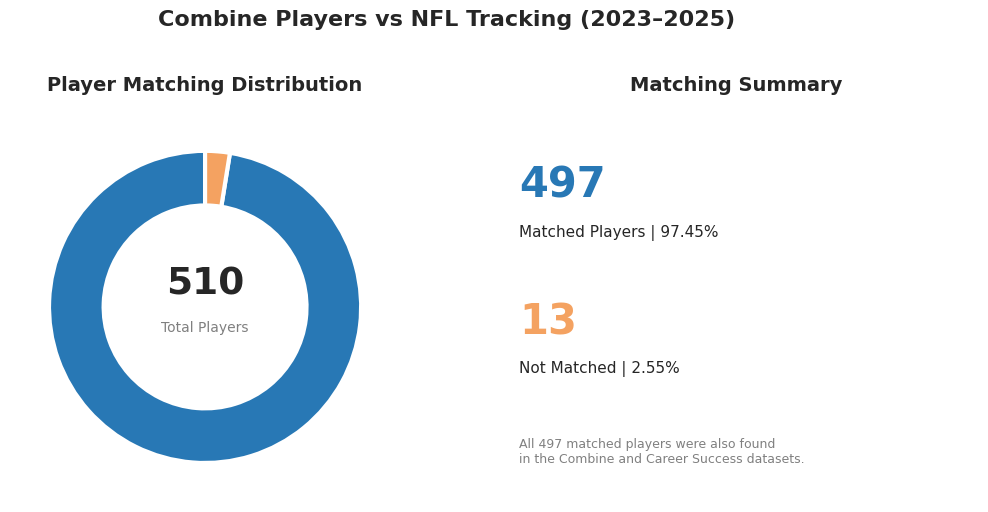

In [727]:
# Prepare player matching data
labels = ["Matched with NFL Tracking", "Not Matched"]
values = [497, 13]
colors = ["#2878B5", "#F4A261"]

sns.set_theme(style="white")

# Create figure with two sections
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11, 5),
    gridspec_kw={"width_ratios": [1.2, 1]}
)

# Create donut chart to show matching distribution
wedges, _ = ax1.pie(
    values,
    startangle=90,
    colors=colors,
    wedgeprops={
        "width": 0.35,
        "edgecolor": "white",
        "linewidth": 3
    }
)

# Display total number of players in the center
ax1.text(0, 0.08, "510", ha="center",
         fontsize=27, fontweight="bold")

ax1.text(0, -0.16, "Total Players",
         ha="center", fontsize=10, color="gray")

ax1.set_title("Player Matching Distribution",
              fontsize=14, fontweight="bold", pad=15)

# Display matching statistics on the right side
ax2.axis("off")
ax2.set_title("Matching Summary",
              fontsize=14, fontweight="bold", pad=15)

# Show matched players and percentage
ax2.text(0.05, 0.78, "497",
         fontsize=30, fontweight="bold", color=colors[0],
         transform=ax2.transAxes)

ax2.text(0.05, 0.68, "Matched Players | 97.45%",
         fontsize=11, transform=ax2.transAxes)

# Show unmatched players and percentage
ax2.text(0.05, 0.43, "13",
         fontsize=30, fontweight="bold", color=colors[1],
         transform=ax2.transAxes)

ax2.text(0.05, 0.33, "Not Matched | 2.55%",
         fontsize=11, transform=ax2.transAxes)

# Add an additional finding from Phase 1
ax2.text(
    0.05, 0.10,
    "All 497 matched players were also found\nin the Combine and Career Success datasets.",
    fontsize=9, color="gray",
    transform=ax2.transAxes
)

# Add overall title and adjust layout
plt.suptitle(
    "Combine Players vs NFL Tracking (2023–2025)",
    fontsize=16, fontweight="bold", y=1.02
)

plt.tight_layout()
plt.show()


### Dataset Understanding & Relationships

**Insights**

- Went through all 9 datasets and understood their main columns and IDs.
- Checked unique IDs and duplicate records to understand how the datasets are connected.
- Matched all 510 Combine players with the Players and Combine Results datasets.
- Found 497 players in NFL Tracking (2023–2025), and all of them were also present in the Combine and Career Success datasets.
- The remaining 13 players had no records in NFL Tracking or Player Play.
- Checked player-level matching between NFL Tracking and Player Play. The matching rate was above 99% for all three years.
- Found 202 game-play combinations that did not match and need further checking.

**Conclusion:** Most of the datasets are properly connected through player IDs and other identifiers. This gives us a good starting point for the next stage of data analysis.

### **Data Quality & Missing Values**

In [728]:
# Check missing values in all datasets

datasets = {
    "Players": players_df,
    "Player Play": player_play_df,
    "Career Success": career_success_df,
    "Games": games_df,
    "Tracking 2023": tracking_2023_df,
    "Tracking 2024": tracking_2024_df,
    "Tracking 2025": tracking_2025_df,
    "Combine Tracking": combine_tracking_df,
    "Combine Results": combine_results_df
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Total Missing Values:", df.isnull().sum().sum())


Players
----------------------------------------
Total Missing Values: 381

Player Play
----------------------------------------
Total Missing Values: 8987108

Career Success
----------------------------------------
Total Missing Values: 0

Games
----------------------------------------
Total Missing Values: 0

Tracking 2023
----------------------------------------
Total Missing Values: 3422066

Tracking 2024
----------------------------------------
Total Missing Values: 7306249

Tracking 2025
----------------------------------------
Total Missing Values: 10425238

Combine Tracking
----------------------------------------
Total Missing Values: 0

Combine Results
----------------------------------------
Total Missing Values: 1289


In [729]:
def missing_analysis(df, name):

    missing = df.isnull().sum()

    result = pd.DataFrame({
        'Missing Values': missing,
        'Missing Percentage': (missing / len(df)) * 100
    })

    result = result[result['Missing Values'] > 0]

    result = result.sort_values(
        by='Missing Percentage',
        ascending=False
    )

    print(f"\n{name}")
    display(result)


missing_analysis(players_df, "Players")
missing_analysis(player_play_df, "Player Play")
missing_analysis(tracking_2023_df, "Tracking 2023")
missing_analysis(tracking_2024_df, "Tracking 2024")
missing_analysis(tracking_2025_df, "Tracking 2025")
missing_analysis(combine_results_df, "Combine Results")


Players


,Missing Values,Missing Percentage
draft_round,127,24.901961
draft_pick_within_round,127,24.901961
draft_overall_pick,127,24.901961



Player Play


,Missing Values,Missing Percentage
rush_yards,314175,99.992998
fumble,314124,99.976766
fumble_lost,314124,99.976766
recovered_fumble,311983,99.295347
quick_pressure,310434,98.802344
time_to_pressure,310393,98.789295
time_to_qb_hurry,310318,98.765424
time_to_pressure_allowed,309227,98.418190
yards_after_catch,307937,98.007619
rec_yards,307937,98.007619



Tracking 2023


,Missing Values,Missing Percentage
event,3422066,93.36023


... (2 outputs left out)


Tracking 2025


,Missing Values,Missing Percentage
event,10425238,93.408553



Combine Results


,Missing Values,Missing Percentage
three_cone,330,64.705882
bench_reps,318,62.352941
short_shuttle,309,60.588235
broad_jump,87,17.058824
forty,86,16.862745
ten_yd_split,85,16.666667
vertical,72,14.117647
ngs_college_production_score,1,0.196078
ngs_final_score,1,0.196078


In [730]:
# Check missing test results by draft year

test_columns = [
    'three_cone',
    'bench_reps',
    'short_shuttle',
    'broad_jump',
    'forty',
    'ten_yd_split',
    'vertical'
]

combine_results_df.groupby('draft_year')[test_columns].apply(
    lambda x: x.isna().sum()
)

,three_cone,bench_reps,short_shuttle,broad_jump,forty,ten_yd_split,vertical
draft_year,,,,,,,
2023,100,83,90,20,19,19,18
2024,116,115,112,27,27,26,21
2025,114,120,107,40,40,40,33


In [731]:
combine_results_df.groupby(
    'combine_position'
)[test_columns].apply(
    lambda x: x.isna().sum()
)

,three_cone,bench_reps,short_shuttle,broad_jump,forty,ten_yd_split,vertical
combine_position,,,,,,,
DB,97,77,89,24,18,18,17
DL,75,64,72,21,24,24,16
OL,60,68,57,23,26,25,21
TE,24,30,22,7,8,8,7
WR,74,79,69,12,10,10,11


In [732]:
# Check missing values by player position

position_missing = combine_results_df.groupby(
    'combine_position'
)[test_columns].apply(
    lambda x: x.isna().mean() * 100
)

print("Missing Values by Player Position (%)")
display(position_missing.round(2))

Missing Values by Player Position (%)


,three_cone,bench_reps,short_shuttle,broad_jump,forty,ten_yd_split,vertical
combine_position,,,,,,,
DB,79.51,63.11,72.95,19.67,14.75,14.75,13.93
DL,63.56,54.24,61.02,17.80,20.34,20.34,13.56
OL,49.59,56.20,47.11,19.01,21.49,20.66,17.36
TE,57.14,71.43,52.38,16.67,19.05,19.05,16.67
WR,69.16,73.83,64.49,11.21,9.35,9.35,10.28


### Position-wise Missing Value Analysis

- Missing test results were found in all five player positions.
- DB players had the most missing results in the Three Cone test (79.51%).
- In Bench Reps, missing results were highest for WR (73.83%) and TE (71.43%).
- OL players had fewer missing results in Three Cone (49.59%) and Short Shuttle (47.11%) compared to the other positions.

**Conclusion:** The amount of missing data is different for each position and test. We need to keep this in mind when comparing player performance by position.

In [733]:
# Group Combine results by draft year and player position
# Calculate missing percentages for each Combine test

year_position_missing = combine_results_df.groupby(
    ['draft_year', 'combine_position']
)[test_columns].apply(
    lambda x: x.isna().mean() * 100
)

# Display the analysis results
print("=" * 65)
print("MISSING VALUES BY DRAFT YEAR AND PLAYER POSITION")
print("=" * 65)

display(year_position_missing.round(2))

MISSING VALUES BY DRAFT YEAR AND PLAYER POSITION


three_cone  bench_reps  short_shuttle  \
draft_year combine_position                                          
2023       DB                     82.86       42.86          71.43   
           DL                     51.35       43.24          56.76   
           OL                     45.95       48.65          40.54   
           TE                     75.00       41.67          66.67   
           WR                     66.67       74.36          53.85   
2024       DB                     80.00       74.00          76.00   
           DL                     72.97       54.05          62.16   
           OL                     45.65       54.35          50.00   
           TE                     46.15       92.31          46.15   
           WR                     70.97       67.74          70.97   
2025       DB                     75.68       67.57          70.27   
           DL                     65.91       63.64          63.64   
           OL                     57.89       65.79          50.00   
           TE                     52.94       76.47          47.06   
           WR                     70.27       78.38          70.27   

                             broad_jump  forty  ten_yd_split  vertical  
draft_year combine_position                                             
2023       DB                      8.57   2.86          2.86      2.86  
           DL                     13.51  10.81         10.81     13.51  
           OL                     16.22  18.92         18.92     13.51  
           TE                      8.33  25.00         25.00     16.67  
           WR                     12.82  10.26         10.26     12.82  
2024       DB                     22.00  18.00         18.00     18.00  
           DL                     13.51  13.51         13.51      8.11  
           OL                     15.22  19.57         17.39     10.87  
           TE                     23.08  15.38         15.38     23.08  
           WR                      3.23   6.45          6.45      3.23  
2025       DB                     27.03  21.62         21.62     18.92  
           DL                     25.00  34.09         34.09     18.18  
           OL                     26.32  26.32         26.32     28.95  
           TE                     17.65  17.65         17.65     11.76  
           WR                     16.22  10.81         10.81     13.51

In [734]:
# Count players in each draft year and position group
group_sizes = combine_results_df.groupby(
    ['draft_year', 'combine_position']
).size()

# Print the group size analysis
print("=" * 65)
print("PLAYER COUNT BY DRAFT YEAR AND POSITION")
print("=" * 65)

display(group_sizes.to_frame(name='Total Players'))

PLAYER COUNT BY DRAFT YEAR AND POSITION


Total Players
draft_year combine_position               
2023       DB                           35
           DL                           37
           OL                           37
           TE                           12
           WR                           39
2024       DB                           50
           DL                           37
           OL                           46
           TE                           13
           WR                           31
2025       DB                           37
           DL                           44
           OL                           38
           TE                           17
           WR                           37

### Draft Year and Position-wise Missing Data

- The number of players varies across positions and draft years.
- In 2024, the TE group had 13 players, and 92.31% of its Bench Reps results were missing.
- The 2024 DB group had the highest player count, with 50 players.
- Smaller groups should be considered carefully when comparing missing percentages.

**Conclusion:** Player counts differ across groups, so both missing percentages and group sizes are important when analysing Combine test availability.

In [735]:
# Select important performance-related columns
performance_columns = [
    'rec_yards',
    'rush_yards',
    'yards_after_catch',
    'tackle',
    'sack',
    'fumble',
    'pass_length'
]

# Calculate missing counts and percentages
player_play_missing = pd.DataFrame({
    'Missing Values': player_play_df[performance_columns].isna().sum(),
    'Missing Percentage': (
        player_play_df[performance_columns].isna().mean() * 100
    )
})

# Display the analysis
print("=" * 65)
print("PLAYER PLAY - PERFORMANCE COLUMNS MISSING VALUE ANALYSIS")
print("=" * 65)

display(player_play_missing.round(2))

PLAYER PLAY - PERFORMANCE COLUMNS MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
rec_yards,307937,98.01
rush_yards,314175,99.99
yards_after_catch,307937,98.01
tackle,302301,96.21
sack,227362,72.36
fumble,314124,99.98
pass_length,129458,41.20


In [736]:
# Check the distribution of target values
print("=" * 60)
print("TARGET COLUMN VALUE COUNTS")
print("=" * 60)

display(player_play_df['target'].value_counts(dropna=False))

# Compare receiving yards availability for targeted and non-targeted players
target_analysis = player_play_df.groupby(
    'target',
    dropna=False
)['rec_yards'].agg(
    Total_Rows='size',
    Available_Rec_Yards='count',
    Missing_Rec_Yards=lambda x: x.isna().sum()
)

# Calculate missing percentage
target_analysis['Missing_Percentage'] = (
    target_analysis['Missing_Rec_Yards'] /
    target_analysis['Total_Rows'] * 100
)

# Display the results
print("\n" + "=" * 60)
print("RECEIVING YARDS AVAILABILITY BY TARGET STATUS")
print("=" * 60)

display(target_analysis.round(2))

TARGET COLUMN VALUE COUNTS


target
False    304355
True       9842
Name: count, dtype: int64


RECEIVING YARDS AVAILABILITY BY TARGET STATUS


,Total_Rows,Available_Rec_Yards,Missing_Rec_Yards,Missing_Percentage
target,,,,
False,304355,4,304351,100.00
True,9842,6256,3586,36.44


In [737]:
# Filter rows where the player was a target
targeted_players = player_play_df[
    player_play_df['target'] == True
]

# Analyse receiving yards availability by pass result
pass_analysis = targeted_players.groupby(
    'pass_result',
    dropna=False
)['rec_yards'].agg(
    Total_Rows='size',
    Available_Rec_Yards='count',
    Missing_Rec_Yards=lambda x: x.isna().sum()
)

# Calculate missing percentage for each pass result
pass_analysis['Missing_Percentage'] = (
    pass_analysis['Missing_Rec_Yards'] /
    pass_analysis['Total_Rows'] * 100
)

# Display the analysis
print("=" * 65)
print("RECEIVING YARDS MISSINGNESS BY PASS RESULT")
print("=" * 65)

display(pass_analysis.round(2))

RECEIVING YARDS MISSINGNESS BY PASS RESULT


,Total_Rows,Available_Rec_Yards,Missing_Rec_Yards,Missing_Percentage
pass_result,,,,
C,6256,6256,0,0.0
I,3319,0,3319,100.0
IN,267,0,267,100.0


### Receiving Yards Missing Value Analysis

- All 6,256 completed pass records had Receiving Yards available.
- All 3,319 incomplete pass records had missing Receiving Yards.
- All 267 interception records also had missing Receiving Yards.

**Conclusion:** Missing Receiving Yards are closely related to the pass result. This suggests that these missing values are mostly expected rather than random data gaps.

In [738]:
# Display columns related to rushing
print("=" * 60)
print("COLUMNS RELATED TO RUSHING")
print("=" * 60)

display([
    col for col in player_play_df.columns
    if 'rush' in col.lower()
])

COLUMNS RELATED TO RUSHING


['rush_yards', 'pass_rushers_encountered']

In [739]:
# Search for columns related to play type or rushing activity
print("=" * 60)
print("POSSIBLE PLAY TYPE COLUMNS")
print("=" * 60)

display([
    col for col in player_play_df.columns
    if any(word in col.lower() for word in ['play', 'type', 'run'])
])

POSSIBLE PLAY TYPE COLUMNS


['play_id',
 'play_description',
 'play_direction',
 'play_nullified_by_penalty',
 'team_coverage_type',
 'player_get_off']

In [740]:
# Display sample play descriptions
print("=" * 60)
print("SAMPLE PLAY DESCRIPTIONS")
print("=" * 60)

display(
    player_play_df['play_description'].dropna().head(15)
)

SAMPLE PLAY DESCRIPTIONS


0     (8:42) (Shotgun) L.Jackson pass incomplete dee...
1     (3:48) (Shotgun) K.Walker left end to SEA 28 f...
2     (7:01) C.Van Lanen reported in as eligible.  T...
3     (4:05) I.Williams left end to NE 22 for 4 yard...
4     (10:08) (No Huddle, Shotgun) M.Mariota scrambl...
5     (4:08) (Shotgun) B.Young pass incomplete deep ...
6     (6:32) M.Jones pass deep middle to R.Pearsall ...
7     (14:17) J.Williams up the middle to ARZ 49 for...
8     (15:00) (Shotgun) D.Watson pass short left int...
9     (11:50) (Shotgun) T.Tagovailoa pass short righ...
10    (14:56) T.Huntley pass short left to M.Andrews...
11    (7:30) T.Tracy left end pushed ob at NYG 42 fo...
12    (8:32) (No Huddle, Shotgun) T.Shough pass inco...
13    (2:18) G.Smith pass short right to A.Jeanty pu...
14    (12:28) (Shotgun) W.Marks left guard to HST 34...
Name: play_description, dtype: object

In [741]:
# Check whether rushing yards are available for different play descriptions
rush_yards_by_description = player_play_df[
    player_play_df['rush_yards'].notna()
]

print("=" * 60)
print("SAMPLE RECORDS WITH AVAILABLE RUSHING YARDS")
print("=" * 60)

display(
    rush_yards_by_description[
        ['play_description', 'rush_yards']
    ].head(15)
)

SAMPLE RECORDS WITH AVAILABLE RUSHING YARDS


,play_description,rush_yards
16258,(1:17) S.Vaki up the middle to DET 37 for 4 ya...,4.0
19260,(1:18) (Shotgun) S.Vaki left tackle to NYG 19 ...,4.0
79515,"(:16) (No Huddle, Shotgun) S.Vaki right tackle...",2.0
82594,(9:07) S.Vaki left tackle to DET 23 for 2 yard...,2.0
95988,(3:34) S.Vaki right end to JAX 33 for -2 yards...,-2.0
104941,(8:16) (Shotgun) S.Vaki right end to DET 22 fo...,6.0
164905,(5:19) (Shotgun) S.Vaki right end to DAL 31 fo...,5.0
178429,(1:50) (Shotgun) S.Vaki up the middle to DET 3...,14.0
193834,(4:06) S.Vaki right guard to DET 36 for 1 yard...,1.0
202633,(1:14) S.Vaki right tackle to DET 35 for 5 yar...,5.0


In [742]:
# Display sample records where rushing yards are missing
missing_rush = player_play_df[
    player_play_df['rush_yards'].isna()
]

print("=" * 60)
print("SAMPLE RECORDS WITH MISSING RUSHING YARDS")
print("=" * 60)

display(
    missing_rush[
        ['play_description', 'rush_yards']
    ].head(15)
)

SAMPLE RECORDS WITH MISSING RUSHING YARDS


,play_description,rush_yards
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN


In [743]:
# Identify common rushing play descriptions
rush_keywords = (
    r'\b(?:left end|right end|up the middle|left guard|right guard|'
    r'left tackle|right tackle|scramble)\b'
)

# Filter possible rushing plays
possible_rush = player_play_df[
    player_play_df['play_description'].str.contains(
        rush_keywords,
        case=False,
        na=False
    )
]

# Compare rushing yards availability
rush_check = possible_rush['rush_yards'].agg(
    Total_Rows='size',
    Available_Rush_Yards='count'
)

rush_check['Missing_Rush_Yards'] = (
    possible_rush['rush_yards'].isna().sum()
)

rush_check['Missing_Percentage'] = (
    rush_check['Missing_Rush_Yards'] /
    rush_check['Total_Rows'] * 100
)

print("=" * 60)
print("RUSHING PLAY DESCRIPTION VS RUSH YARDS")
print("=" * 60)

display(rush_check.to_frame(name='Value'))

RUSHING PLAY DESCRIPTION VS RUSH YARDS


,Value
Total_Rows,109649.000000
Available_Rush_Yards,22.000000
Missing_Rush_Yards,109627.000000
Missing_Percentage,99.979936


In [744]:
# Check records where rushing keywords matched and yards are available
print("=" * 65)
print("MATCHED RECORDS WITH AVAILABLE RUSH YARDS")
print("=" * 65)

display(
    possible_rush[
        possible_rush['rush_yards'].notna()
    ][['play_description', 'rush_yards']].head(15)
)

# Check records where rushing keywords matched but yards are missing
print("\n" + "=" * 65)
print("MATCHED RECORDS WITH MISSING RUSH YARDS")
print("=" * 65)

display(
    possible_rush[
        possible_rush['rush_yards'].isna()
    ][['play_description', 'rush_yards']].head(15)
)

MATCHED RECORDS WITH AVAILABLE RUSH YARDS


,play_description,rush_yards
16258,(1:17) S.Vaki up the middle to DET 37 for 4 ya...,4.0
19260,(1:18) (Shotgun) S.Vaki left tackle to NYG 19 ...,4.0
79515,"(:16) (No Huddle, Shotgun) S.Vaki right tackle...",2.0
82594,(9:07) S.Vaki left tackle to DET 23 for 2 yard...,2.0
95988,(3:34) S.Vaki right end to JAX 33 for -2 yards...,-2.0
104941,(8:16) (Shotgun) S.Vaki right end to DET 22 fo...,6.0
164905,(5:19) (Shotgun) S.Vaki right end to DAL 31 fo...,5.0
178429,(1:50) (Shotgun) S.Vaki up the middle to DET 3...,14.0
193834,(4:06) S.Vaki right guard to DET 36 for 1 yard...,1.0
202633,(1:14) S.Vaki right tackle to DET 35 for 5 yar...,5.0



MATCHED RECORDS WITH MISSING RUSH YARDS


,play_description,rush_yards
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN
11,(7:30) T.Tracy left end pushed ob at NYG 42 fo...,NaN
14,(12:28) (Shotgun) W.Marks left guard to HST 34...,NaN
17,"(6:01) (No Huddle, Shotgun) T.Bigsby up the mi...",NaN
18,(9:10) P.Nacua left end to BUF 3 for 9 yards (...,NaN
19,(5:11) R.Shaheed left end pushed ob at DAL 26 ...,NaN


In [745]:
# Inspect all available records for K. Walker
kwalker_records = player_play_df[
    player_play_df['play_description'].str.contains(
        'K.Walker',
        case=False,
        na=False
    )
]

print("=" * 65)
print("K. WALKER - RUSHING YARDS INVESTIGATION")
print("=" * 65)

display(
    kwalker_records[
        ['play_description', 'rush_yards']
    ].head(20)
)

K. WALKER - RUSHING YARDS INVESTIGATION


,play_description,rush_yards
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN
75,(7:11) K.Walker right end to NE 12 for 2 yards...,NaN
206,(14:15) (Shotgun) K.Walker left end to HST 44 ...,NaN
262,(7:54) K.Walker right tackle to SEA 40 for 5 y...,NaN
345,(9:23) K.Walker right guard to SEA 43 for 1 ya...,NaN
511,(6:54) K.Walker up the middle to PIT 7 for 5 y...,NaN
565,(1:56) K.Walker left guard to LA 33 for 4 yard...,NaN
594,(14:54) (Shotgun) K.Walker right tackle to TEN...,NaN
597,(14:10) K.Walker right end to SF 12 for -3 yar...,NaN
751,"(9:47) K.Walker left tackle for 15 yards, TOUC...",NaN


In [746]:
# Display all columns in Player Play dataset
print("=" * 60)
print("PLAYER PLAY DATASET COLUMNS")
print("=" * 60)

for col in player_play_df.columns:
    print(col)

PLAYER PLAY DATASET COLUMNS
game_id
play_id
team_abbr
nfl_id
lined_up_position
play_description
quarter
down
yards_to_go
possession_team
yardline_side
yardline_number
game_clock
pre_snap_home_score
pre_snap_visitor_score
play_direction
pre_snap_home_team_win_probability
pre_snap_visitor_team_win_probability
home_team_win_probability_added
visitor_team_win_probility_added
expected_points_added
expected_points
offense_formation
receiver_alignment
pass_result
pass_length
play_nullified_by_penalty
penalty_yards
pre_penalty_yards_gained
yards_gained
team_coverage_man_zone
team_coverage_type
in_motion_at_ball_snap
target
rec_yards
rush_yards
yards_after_catch
fumble
fumble_lost
route_ran
separation_at_pass_forward
cushion
expected_yards_after_catch
dropback_duration
extended_sack_allowed
pass_rushers_encountered
peak_pressure_probability_allowed
pressure_allowed
sack_allowed
time_to_pressure_allowed
quick_pressure
unblocked_pressure
blitzing
player_get_off
sack
tackle
assist
caused_forced_fu

In [747]:
# Compare missing and available values in both columns
print("=" * 65)
print("YARDS GAINED VS RUSH YARDS")
print("=" * 65)

yards_comparison = pd.DataFrame({
    'Total_Rows': len(player_play_df),
    'Available_Values': player_play_df[
        ['yards_gained', 'rush_yards']
    ].count(),
    'Missing_Values': player_play_df[
        ['yards_gained', 'rush_yards']
    ].isna().sum()
})

yards_comparison['Missing_Percentage'] = (
    yards_comparison['Missing_Values'] /
    yards_comparison['Total_Rows'] * 100
)

display(yards_comparison.round(2))


# Check yards_gained availability where rush_yards is missing
missing_rush_analysis = player_play_df[
    player_play_df['rush_yards'].isna()
]

print("\n" + "=" * 65)
print("YARDS GAINED AVAILABILITY WHERE RUSH YARDS ARE MISSING")
print("=" * 65)

display(pd.DataFrame({
    'Total_Rows': [len(missing_rush_analysis)],
    'Available_Yards_Gained': [
        missing_rush_analysis['yards_gained'].count()
    ],
    'Missing_Yards_Gained': [
        missing_rush_analysis['yards_gained'].isna().sum()
    ]
}))

YARDS GAINED VS RUSH YARDS


,Total_Rows,Available_Values,Missing_Values,Missing_Percentage
yards_gained,314197,314197,0,0.00
rush_yards,314197,22,314175,99.99



YARDS GAINED AVAILABILITY WHERE RUSH YARDS ARE MISSING


,Total_Rows,Available_Yards_Gained,Missing_Yards_Gained
0,314175,314175,0


In [748]:
# Inspect pass result values where rushing yards are available
available_rush = player_play_df[
    player_play_df['rush_yards'].notna()
]

print("=" * 65)
print("PASS RESULT FOR AVAILABLE RUSH YARDS")
print("=" * 65)

display(
    available_rush['pass_result'].value_counts(dropna=False)
)

print("\n" + "=" * 65)
print("AVAILABLE RUSH YARDS RECORDS")
print("=" * 65)

display(
    available_rush[
        ['play_description', 'pass_result', 'yards_gained', 'rush_yards']
    ]
)

PASS RESULT FOR AVAILABLE RUSH YARDS


pass_result
NaN    22
Name: count, dtype: int64


AVAILABLE RUSH YARDS RECORDS


,play_description,pass_result,yards_gained,rush_yards
16258,(1:17) S.Vaki up the middle to DET 37 for 4 ya...,NaN,4,4.0
19260,(1:18) (Shotgun) S.Vaki left tackle to NYG 19 ...,NaN,4,4.0
79515,"(:16) (No Huddle, Shotgun) S.Vaki right tackle...",NaN,2,2.0
82594,(9:07) S.Vaki left tackle to DET 23 for 2 yard...,NaN,2,2.0
95988,(3:34) S.Vaki right end to JAX 33 for -2 yards...,NaN,-2,-2.0
104941,(8:16) (Shotgun) S.Vaki right end to DET 22 fo...,NaN,6,6.0
164905,(5:19) (Shotgun) S.Vaki right end to DAL 31 fo...,NaN,5,5.0
178429,(1:50) (Shotgun) S.Vaki up the middle to DET 3...,NaN,14,14.0
193834,(4:06) S.Vaki right guard to DET 36 for 1 yard...,NaN,1,1.0
202633,(1:14) S.Vaki right tackle to DET 35 for 5 yar...,NaN,5,5.0


### Rushing Yards Missing Value Analysis

- The `rush_yards` column contains 314,175 missing values (99.99%).
- Only 22 records contain available values, and all 22 belong to S. Vaki based on their play descriptions.
- In all 22 records, `rush_yards` matches `yards_gained`.
- Some records with missing `rush_yards` also describe rushing plays.

**Conclusion:** The missing values cannot be explained only by non-rushing plays. The exact reason for this high level of missingness remains unclear. Missing values will be preserved without imputation or deletion.

In [749]:
# Check missing values in Fumble column
fumble_missing = player_play_df['fumble'].isna().sum()
fumble_available = player_play_df['fumble'].notna().sum()

print("=" * 65)
print("FUMBLE MISSING VALUE ANALYSIS")
print("=" * 65)

print("Total Records:", len(player_play_df))
print("Available Values:", fumble_available)
print("Missing Values:", fumble_missing)
print(
    "Missing Percentage:",
    round(player_play_df['fumble'].isna().mean() * 100, 2),
    "%"
)

FUMBLE MISSING VALUE ANALYSIS
Total Records: 314197
Available Values: 73
Missing Values: 314124
Missing Percentage: 99.98 %


In [750]:
# Compare missing values across fumble-related columns
fumble_columns = [
    'fumble',
    'fumble_lost',
    'recovered_fumble'
]

fumble_summary = pd.DataFrame({
    'Available_Values': player_play_df[fumble_columns].notna().sum(),
    'Missing_Values': player_play_df[fumble_columns].isna().sum(),
    'Missing_Percentage': (
        player_play_df[fumble_columns].isna().mean() * 100
    ).round(2)
})

print("=" * 65)
print("FUMBLE-RELATED COLUMNS: MISSING VALUE COMPARISON")
print("=" * 65)

display(fumble_summary)

FUMBLE-RELATED COLUMNS: MISSING VALUE COMPARISON


,Available_Values,Missing_Values,Missing_Percentage
fumble,73,314124,99.98
fumble_lost,73,314124,99.98
recovered_fumble,2214,311983,99.30


### Fumble-Related Columns Missing Value Analysis

- The `fumble` and `fumble_lost` columns both contain only 73 available values (99.98% missing).
- The `recovered_fumble` column contains 2,214 available values (99.30% missing).
- `recovered_fumble` has considerably more available values than the other two columns.

**Conclusion:** All three fumble-related columns have extremely high missingness, but their data availability differs. The reason for these missing values cannot be determined from the missing-value counts alone.

In [751]:
# Compare missing values in defensive tackling columns
defensive_columns = ['tackle', 'assist']

defensive_summary = pd.DataFrame({
    'Available_Values': player_play_df[defensive_columns].notna().sum(),
    'Missing_Values': player_play_df[defensive_columns].isna().sum(),
    'Missing_Percentage': (
        player_play_df[defensive_columns].isna().mean() * 100
    ).round(2)
})

print("=" * 65)
print("DEFENSIVE TACKLING COLUMNS: MISSING VALUE ANALYSIS")
print("=" * 65)

display(defensive_summary)

DEFENSIVE TACKLING COLUMNS: MISSING VALUE ANALYSIS


,Available_Values,Missing_Values,Missing_Percentage
tackle,11896,302301,96.21
assist,11896,302301,96.21


In [752]:
# Compare missing-value patterns in tackle and assist
same_missing = (
    player_play_df['tackle'].isna() ==
    player_play_df['assist'].isna()
)

print("=" * 65)
print("TACKLE AND ASSIST MISSINGNESS PATTERN")
print("=" * 65)

print("Same missingness pattern:", same_missing.all())
print("Matching records:", same_missing.sum())
print("Different records:", (~same_missing).sum())

TACKLE AND ASSIST MISSINGNESS PATTERN
Same missingness pattern: True
Matching records: 314197
Different records: 0


In [753]:
# Inspect records where tackle and assist are available
tackle_records = player_play_df[
    player_play_df['tackle'].notna()
]

print("=" * 65)
print("AVAILABLE TACKLE AND ASSIST RECORDS")
print("=" * 65)

display(
    tackle_records[
        ['play_description', 'tackle', 'assist']
    ].head(20)
)

AVAILABLE TACKLE AND ASSIST RECORDS


,play_description,tackle,assist
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",1.0,0.0
49,(14:49) (Shotgun) M.Brosmer pass short right t...,0.0,1.0
64,(8:03) (Shotgun) C.Stroud scrambles right end ...,1.0,0.0
67,(11:31) B.Robinson left end to ATL 49 for 3 ya...,0.0,1.0
193,(10:45) (No Huddle) J.Daniels pass short left ...,1.0,0.0
258,"(5:59) (No Huddle, Shotgun) A.Richardson pass ...",1.0,0.0
325,(6:02) A.Mattison right guard to MIA 10 for 7 ...,0.0,1.0
364,(1:56) K.Mitchell left guard to PHI 26 for 3 y...,1.0,0.0
378,(8:58) (Shotgun) G.Smith pass short right inte...,1.0,0.0
400,(10:32) (Shotgun) T.Huntley pass short right t...,1.0,0.0


In [754]:
# Inspect records where tackle and assist are missing
missing_tackle_records = player_play_df[
    player_play_df['tackle'].isna()
]

print("=" * 65)
print("SAMPLE RECORDS WITH MISSING TACKLE AND ASSIST")
print("=" * 65)

display(
    missing_tackle_records[
        ['play_description', 'tackle', 'assist']
    ].head(20)
)

SAMPLE RECORDS WITH MISSING TACKLE AND ASSIST


,play_description,tackle,assist
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,NaN
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,NaN
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,NaN
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,NaN
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,NaN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,NaN
10,(14:56) T.Huntley pass short left to M.Andrews...,NaN,NaN


### Defensive Tackling Columns Missing Value Analysis

- Both `tackle` and `assist` contain 11,896 available values (3.79%) and 302,301 missing values (96.21%).
- Both columns have exactly the same missing-value pattern.
- Available records contain both 0 and 1 values.
- Missing records include both passing and rushing plays.

**Conclusion:** Missing values are not limited to one particular play type. The exact reason for their absence cannot be confirmed from the inspected records alone. Further interpretation requires the dataset's column definitions or documentation.

In [755]:
# Compare missing values in sack-related columns
sack_columns = ['sack', 'sack_allowed']

sack_summary = pd.DataFrame({
    'Available_Values': player_play_df[sack_columns].notna().sum(),
    'Missing_Values': player_play_df[sack_columns].isna().sum(),
    'Missing_Percentage': (
        player_play_df[sack_columns].isna().mean() * 100
    ).round(2)
})

print("=" * 65)
print("SACK-RELATED COLUMNS: MISSING VALUE ANALYSIS")
print("=" * 65)

display(sack_summary)

SACK-RELATED COLUMNS: MISSING VALUE ANALYSIS


,Available_Values,Missing_Values,Missing_Percentage
sack,86835,227362,72.36
sack_allowed,60803,253394,80.65


In [756]:
# Compare missingness patterns
same_missing = (
    player_play_df['sack'].isna() ==
    player_play_df['sack_allowed'].isna()
)

print("=" * 65)
print("SACK AND SACK_ALLOWED MISSINGNESS PATTERN")
print("=" * 65)

print("Same missingness pattern:", same_missing.all())
print("Matching records:", same_missing.sum())
print("Different records:", (~same_missing).sum())

SACK AND SACK_ALLOWED MISSINGNESS PATTERN
Same missingness pattern: False
Matching records: 166559
Different records: 147638


In [757]:
# Inspect available sack-related records
sack_records = player_play_df[
    player_play_df['sack'].notna() |
    player_play_df['sack_allowed'].notna()
]

print("=" * 65)
print("AVAILABLE SACK-RELATED RECORDS")
print("=" * 65)

display(
    sack_records[
        ['play_description', 'sack', 'sack_allowed']
    ].head(20)
)

AVAILABLE SACK-RELATED RECORDS


,play_description,sack,sack_allowed
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,0.0
2,(7:01) C.Van Lanen reported in as eligible. T...,0.0,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",0.0,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,0.0
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,0.0,NaN
10,(14:56) T.Huntley pass short left to M.Andrews...,NaN,0.0
12,"(8:32) (No Huddle, Shotgun) T.Shough pass inco...",0.0,NaN
15,(14:04) (Shotgun) R.Wilson pass incomplete sho...,0.0,NaN
16,"(3:54) (No Huddle, Shotgun) G.Smith pass short...",NaN,0.0
21,(15:00) R.Leonard pass short right to T.Warren...,NaN,0.0


In [758]:
# Inspect records with missing sack values
print("=" * 65)
print("MISSING SACK RECORDS")
print("=" * 65)

display(
    player_play_df[
        player_play_df['sack'].isna()
    ][['play_description', 'sack', 'sack_allowed']].head(15)
)

# Inspect records with missing sack_allowed values
print("\n" + "=" * 65)
print("MISSING SACK_ALLOWED RECORDS")
print("=" * 65)

display(
    player_play_df[
        player_play_df['sack_allowed'].isna()
    ][['play_description', 'sack', 'sack_allowed']].head(15)
)

MISSING SACK RECORDS


,play_description,sack,sack_allowed
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,0.0
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,NaN
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,NaN
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,0.0
10,(14:56) T.Huntley pass short left to M.Andrews...,NaN,0.0
11,(7:30) T.Tracy left end pushed ob at NYG 42 fo...,NaN,NaN
13,(2:18) G.Smith pass short right to A.Jeanty pu...,NaN,NaN



MISSING SACK_ALLOWED RECORDS


,play_description,sack,sack_allowed
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,0.0,NaN
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",0.0,NaN
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,NaN
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,NaN
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,0.0,NaN
11,(7:30) T.Tracy left end pushed ob at NYG 42 fo...,NaN,NaN
12,"(8:32) (No Huddle, Shotgun) T.Shough pass inco...",0.0,NaN


### Sack-Related Columns Missing Value Analysis

- The `sack` column contains 86,835 available values (27.64%) and 227,362 missing values (72.36%).
- The `sack_allowed` column contains 60,803 available values (19.35%) and 253,394 missing values (80.65%).
- Both columns have different missing-value patterns.
- Missing records in both columns include passing as well as rushing plays.
- Some records have an available value in one column while the other column is missing.

**Conclusion:** Missingness in `sack` and `sack_allowed` is not limited to one play type. Their exact reasons cannot be established from the inspected records alone.

In [759]:
# Compare missing values in pressure-related columns
pressure_columns = [
    'pressure_allowed',
    'quick_pressure',
    'unblocked_pressure'
]

pressure_summary = pd.DataFrame({
    'Available_Values': player_play_df[pressure_columns].notna().sum(),
    'Missing_Values': player_play_df[pressure_columns].isna().sum(),
    'Missing_Percentage': (
        player_play_df[pressure_columns].isna().mean() * 100
    ).round(2)
})

print("=" * 65)
print("PRESSURE-RELATED COLUMNS: MISSING VALUE ANALYSIS")
print("=" * 65)

display(pressure_summary)

PRESSURE-RELATED COLUMNS: MISSING VALUE ANALYSIS


,Available_Values,Missing_Values,Missing_Percentage
pressure_allowed,60803,253394,80.65
quick_pressure,3763,310434,98.80
unblocked_pressure,86838,227359,72.36


In [760]:
# Compare missingness patterns across pressure-related columns
pressure_missing = player_play_df[pressure_columns].isna()

print("=" * 65)
print("PRESSURE COLUMNS: MISSINGNESS PATTERN")
print("=" * 65)

display(
    pressure_missing.value_counts().rename("Record_Count").to_frame()
)

PRESSURE COLUMNS: MISSINGNESS PATTERN


Record_Count
pressure_allowed quick_pressure unblocked_pressure              
True             True           True                      166556
                                False                      83075
False            True           True                       60803
True             False          False                       3763

In [761]:
# Convert boolean values into readable labels
pressure_patterns = (
    player_play_df[pressure_columns]
    .isna()
    .replace({True: 'Missing', False: 'Available'})
)

pattern_counts = (
    pressure_patterns
    .astype(str)
    .agg(' | '.join, axis=1)
    .value_counts()
    .rename_axis('Missingness_Pattern')
    .reset_index(name='Record_Count')
)

print("=" * 65)
print("PRESSURE COLUMNS: CLEAR MISSINGNESS PATTERNS")
print("=" * 65)

display(pattern_counts)

PRESSURE COLUMNS: CLEAR MISSINGNESS PATTERNS


,Missingness_Pattern,Record_Count
0,Missing | Missing | Missing,166556
1,Missing | Missing | Available,83075
2,Available | Missing | Missing,60803
3,Missing | Available | Available,3763


In [762]:
# Inspect available pressure-related records
for col in pressure_columns:

    print("\n" + "=" * 65)
    print(f"AVAILABLE RECORDS: {col.upper()}")
    print("=" * 65)

    available_records = player_play_df[
        player_play_df[col].notna()
    ][['play_description', col, 'pass_result']]

    display(available_records.head(10))


AVAILABLE RECORDS: PRESSURE_ALLOWED


,play_description,pressure_allowed,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,False,I
8,(15:00) (Shotgun) D.Watson pass short left int...,False,IN
10,(14:56) T.Huntley pass short left to M.Andrews...,False,C
16,"(3:54) (No Huddle, Shotgun) G.Smith pass short...",False,C
21,(15:00) R.Leonard pass short right to T.Warren...,False,C
22,(5:45) (Shotgun) C.Williams pass incomplete sh...,False,I
28,(4:52) (Shotgun) A.Rodgers sacked at PIT 21 fo...,True,S
33,(7:07) T.Mordecai pass short left to M.Turner ...,False,C
38,(2:00) (Shotgun) J.Dart pass incomplete deep m...,False,I
48,"(12:37) (No Huddle, Shotgun) E.Stick pass inco...",False,I



AVAILABLE RECORDS: QUICK_PRESSURE


,play_description,quick_pressure,pass_result
177,(2:57) (Shotgun) J.Goff pass incomplete deep l...,True,I
285,(3:06) (Shotgun) K.Murray pass incomplete deep...,False,I
347,(1:56) (Shotgun) C.Tune pass incomplete short ...,True,I
365,(8:46) (Shotgun) J.Love pass deep middle to T....,False,C
397,(11:13) (Shotgun) D.Ridder pass short left to ...,False,C
486,(:40) (Shotgun) D.Jones pass short right to W....,True,C
558,(5:25) (Shotgun) H.Hooker pass incomplete shor...,False,I
584,(:59) (Shotgun) J.Love pass deep left to J.Ree...,False,C
628,(12:15) (Shotgun) J.Brissett pass incomplete d...,False,I
630,(14:40) (Shotgun) C.Stroud pass incomplete sho...,False,I



AVAILABLE RECORDS: UNBLOCKED_PRESSURE


,play_description,unblocked_pressure,pass_result
2,(7:01) C.Van Lanen reported in as eligible. T...,False,R
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",False,R
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,False,C
12,"(8:32) (No Huddle, Shotgun) T.Shough pass inco...",False,I
15,(14:04) (Shotgun) R.Wilson pass incomplete sho...,False,I
24,(2:00) (Shotgun) D.Prescott scrambles up the m...,False,R
25,(1:10) (Shotgun) K.Murray pass incomplete shor...,False,I
27,(10:50) M.Stafford pass incomplete short right...,False,I
32,(9:27) (Shotgun) W.Levis pass incomplete short...,False,I
37,(5:58) (Shotgun) J.Daniels pass incomplete dee...,False,I


In [763]:
# Inspect records with missing pressure-related values
for col in pressure_columns:

    print("\n" + "=" * 65)
    print(f"MISSING RECORDS: {col.upper()}")
    print("=" * 65)

    missing_records = player_play_df[
        player_play_df[col].isna()
    ][['play_description', col, 'pass_result']]

    display(missing_records.head(10))


MISSING RECORDS: PRESSURE_ALLOWED


,play_description,pressure_allowed,pass_result
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,R
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN,R
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,C
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,C
11,(7:30) T.Tracy left end pushed ob at NYG 42 fo...,NaN,NaN
12,"(8:32) (No Huddle, Shotgun) T.Shough pass inco...",NaN,I



MISSING RECORDS: QUICK_PRESSURE


,play_description,quick_pressure,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,I
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,R
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN,R
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,C
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,IN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,C



MISSING RECORDS: UNBLOCKED_PRESSURE


,play_description,unblocked_pressure,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,I
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,C
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,IN
10,(14:56) T.Huntley pass short left to M.Andrews...,NaN,C
11,(7:30) T.Tracy left end pushed ob at NYG 42 fo...,NaN,NaN
13,(2:18) G.Smith pass short right to A.Jeanty pu...,NaN,C


### Pressure-Related Columns Missing Value Analysis

- `pressure_allowed` contains 60,803 available values (19.35%).
- `quick_pressure` contains 3,763 available values (1.20%).
- `unblocked_pressure` contains 86,838 available values (27.64%).
- The three columns have different missingness patterns.
- Missing records include both passing and rushing plays.
- Available records contain both True and False values.

**Conclusion:** Missingness is not limited to one particular play type or pass result. The exact reason for missing values cannot be confirmed from the inspected records alone.

In [764]:
# Compare missing values in pressure timing columns
timing_columns = [
    'time_to_pressure',
    'time_to_qb_hurry',
    'time_to_pressure_allowed'
]

timing_summary = pd.DataFrame({
    'Available_Values': player_play_df[timing_columns].notna().sum(),
    'Missing_Values': player_play_df[timing_columns].isna().sum(),
    'Missing_Percentage': (
        player_play_df[timing_columns].isna().mean() * 100
    ).round(2)
})

print("=" * 65)
print("PRESSURE TIMING COLUMNS: MISSING VALUE ANALYSIS")
print("=" * 65)

display(timing_summary)

PRESSURE TIMING COLUMNS: MISSING VALUE ANALYSIS


,Available_Values,Missing_Values,Missing_Percentage
time_to_pressure,3804,310393,98.79
time_to_qb_hurry,3879,310318,98.77
time_to_pressure_allowed,4970,309227,98.42


In [765]:
# Compare missingness patterns across timing columns
timing_missing = player_play_df[timing_columns].isna()

timing_patterns = (
    timing_missing
    .replace({True: 'Missing', False: 'Available'})
    .astype(str)
    .agg(' | '.join, axis=1)
    .value_counts()
    .rename_axis('Missingness_Pattern')
    .reset_index(name='Record_Count')
)

print("=" * 65)
print("PRESSURE TIMING: MISSINGNESS PATTERNS")
print("=" * 65)

display(timing_patterns)

PRESSURE TIMING: MISSINGNESS PATTERNS


,Missingness_Pattern,Record_Count
0,Missing | Missing | Missing,305348
1,Missing | Missing | Available,4970
2,Available | Available | Missing,3804
3,Missing | Available | Missing,75


In [766]:
# Inspect available pressure timing records
for col in timing_columns:

    print("\n" + "=" * 65)
    print(f"AVAILABLE RECORDS: {col.upper()}")
    print("=" * 65)

    available_records = player_play_df[
        player_play_df[col].notna()
    ][['play_description', col, 'pass_result']]

    display(available_records.head(10))


AVAILABLE RECORDS: TIME_TO_PRESSURE


,play_description,time_to_pressure,pass_result
177,(2:57) (Shotgun) J.Goff pass incomplete deep l...,2.1,I
285,(3:06) (Shotgun) K.Murray pass incomplete deep...,3.5,I
347,(1:56) (Shotgun) C.Tune pass incomplete short ...,2.1,I
365,(8:46) (Shotgun) J.Love pass deep middle to T....,2.6,C
397,(11:13) (Shotgun) D.Ridder pass short left to ...,2.8,C
486,(:40) (Shotgun) D.Jones pass short right to W....,2.2,C
558,(5:25) (Shotgun) H.Hooker pass incomplete shor...,4.1,I
584,(:59) (Shotgun) J.Love pass deep left to J.Ree...,3.4,C
628,(12:15) (Shotgun) J.Brissett pass incomplete d...,3.4,I
630,(14:40) (Shotgun) C.Stroud pass incomplete sho...,3.4,I



AVAILABLE RECORDS: TIME_TO_QB_HURRY


,play_description,time_to_qb_hurry,pass_result
177,(2:57) (Shotgun) J.Goff pass incomplete deep l...,2.1,I
285,(3:06) (Shotgun) K.Murray pass incomplete deep...,3.5,I
347,(1:56) (Shotgun) C.Tune pass incomplete short ...,2.1,I
365,(8:46) (Shotgun) J.Love pass deep middle to T....,2.6,C
397,(11:13) (Shotgun) D.Ridder pass short left to ...,2.8,C
486,(:40) (Shotgun) D.Jones pass short right to W....,2.2,C
558,(5:25) (Shotgun) H.Hooker pass incomplete shor...,4.1,I
584,(:59) (Shotgun) J.Love pass deep left to J.Ree...,3.4,C
628,(12:15) (Shotgun) J.Brissett pass incomplete d...,3.4,I
630,(14:40) (Shotgun) C.Stroud pass incomplete sho...,3.4,I



AVAILABLE RECORDS: TIME_TO_PRESSURE_ALLOWED


,play_description,time_to_pressure_allowed,pass_result
28,(4:52) (Shotgun) A.Rodgers sacked at PIT 21 fo...,2.6,S
157,"(6:49) (No Huddle, Shotgun) J.Driskel pass sho...",2.7,C
167,(13:01) (Shotgun) M.Rudolph pass deep left to ...,3.0,C
210,(1:04) T.Tagovailoa pass short left to D.Eskri...,2.3,C
238,(8:03) (Shotgun) T.Taylor scrambles left guard...,2.2,R
407,(:58) (Shotgun) S.Rattler pass short right to ...,2.0,C
408,(2:29) D.Prescott pass short left to J.Ferguso...,2.3,C
467,(:19) D.Mills pass incomplete short left to C....,2.5,I
603,(:27) (Shotgun) D.Prescott sacked at WAS 23 fo...,3.3,S
667,(4:26) (Shotgun) R.Wilson pass short right to ...,2.6,C


In [767]:
# Inspect records with missing pressure timing values
for col in timing_columns:

    print("\n" + "=" * 65)
    print(f"MISSING RECORDS: {col.upper()}")
    print("=" * 65)

    missing_records = player_play_df[
        player_play_df[col].isna()
    ][['play_description', col, 'pass_result']]

    display(missing_records.head(10))


MISSING RECORDS: TIME_TO_PRESSURE


,play_description,time_to_pressure,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,I
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,R
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN,R
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,C
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,IN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,C



MISSING RECORDS: TIME_TO_QB_HURRY


,play_description,time_to_qb_hurry,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,I
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,R
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN,R
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,C
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,IN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,C



MISSING RECORDS: TIME_TO_PRESSURE_ALLOWED


,play_description,time_to_pressure_allowed,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,I
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,R
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN,R
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,NaN,C
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,IN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,C


In [768]:
# Compare pressure timing values
both_available = player_play_df[
    ['time_to_pressure', 'time_to_qb_hurry']
].dropna()

print("=" * 65)
print("COMPARISON OF AVAILABLE TIMING VALUES")
print("=" * 65)

print("Records with both values:", len(both_available))
print(
    "Matching timing values:",
    (both_available['time_to_pressure'] ==
     both_available['time_to_qb_hurry']).sum()
)

print("\n" + "=" * 65)
print("RECORDS WITH ONLY TIME_TO_QB_HURRY AVAILABLE")
print("=" * 65)

exceptional_records = player_play_df[
    player_play_df['time_to_pressure'].isna() &
    player_play_df['time_to_qb_hurry'].notna()
][['play_description', 'time_to_pressure',
   'time_to_qb_hurry', 'pass_result']]

display(exceptional_records)

COMPARISON OF AVAILABLE TIMING VALUES
Records with both values: 3804
Matching timing values: 3804

RECORDS WITH ONLY TIME_TO_QB_HURRY AVAILABLE


,play_description,time_to_pressure,time_to_qb_hurry,pass_result
2285,(11:03) (Shotgun) P.Mahomes pass incomplete de...,NaN,2.9,I
10350,(5:32) (Shotgun) M.Brosmer pass incomplete sho...,NaN,2.4,I
10546,(10:26) (Shotgun) P.Mahomes pass short right t...,NaN,2.8,C
12917,(4:03) B.Purdy sacked at TB 30 for -3 yards (C...,NaN,2.2,S
18204,(13:10) (Shotgun) J.Goff pass short right to J...,NaN,4.2,C
...,...,...,...,...
291282,(7:59) (Shotgun) C.Williams pass incomplete sh...,NaN,2.3,I
291897,(7:52) (Shotgun) T.Shough sacked at NO 16 for ...,NaN,3.3,S
300982,(10:28) (Shotgun) B.Zappe sacked at HST 25 for...,NaN,2.3,S
304103,(10:04) (Shotgun) A.Richardson pass incomplete...,NaN,3.1,I


### Pressure Timing Columns Missing Value Analysis

- `time_to_pressure` has 3,804 available values (1.21%).
- `time_to_qb_hurry` has 3,879 available values (1.23%).
- `time_to_pressure_allowed` has 4,970 available values (1.58%).
- All 3,804 jointly available values in `time_to_pressure` and `time_to_qb_hurry` match exactly.
- In 75 records, `time_to_qb_hurry` is available while `time_to_pressure` is missing.
- Missing records include different play types and pass results.

**Conclusion:** `time_to_pressure` and `time_to_qb_hurry` show identical values wherever both are available, but their availability is not completely identical. The exact reason for missing values remains unclear.

In [769]:
# Compare missing values in yards-after-catch columns
yac_columns = [
    'yards_after_catch',
    'expected_yards_after_catch'
]

yac_summary = pd.DataFrame({
    'Available_Values': player_play_df[yac_columns].notna().sum(),
    'Missing_Values': player_play_df[yac_columns].isna().sum(),
    'Missing_Percentage': (
        player_play_df[yac_columns].isna().mean() * 100
    ).round(2)
})

print("=" * 65)
print("YARDS AFTER CATCH: MISSING VALUE ANALYSIS")
print("=" * 65)

display(yac_summary)

YARDS AFTER CATCH: MISSING VALUE ANALYSIS


,Available_Values,Missing_Values,Missing_Percentage
yards_after_catch,6260,307937,98.01
expected_yards_after_catch,8976,305221,97.14


In [770]:
# Compare missingness patterns
yac_patterns = (
    player_play_df[yac_columns]
    .isna()
    .replace({True: 'Missing', False: 'Available'})
    .astype(str)
    .agg(' | '.join, axis=1)
    .value_counts()
    .rename_axis('Missingness_Pattern')
    .reset_index(name='Record_Count')
)

print("=" * 65)
print("YARDS AFTER CATCH: MISSINGNESS PATTERNS")
print("=" * 65)

display(yac_patterns)

YARDS AFTER CATCH: MISSINGNESS PATTERNS


,Missingness_Pattern,Record_Count
0,Missing | Missing,304827
1,Available | Available,5866
2,Missing | Available,3110
3,Available | Missing,394


In [771]:
# Inspect available records in yards-after-catch columns
for col in yac_columns:

    print("\n" + "=" * 65)
    print(f"AVAILABLE RECORDS: {col.upper()}")
    print("=" * 65)

    available_records = player_play_df[
        player_play_df[col].notna()
    ][['play_description', col, 'pass_result']]

    display(available_records.head(10))


AVAILABLE RECORDS: YARDS_AFTER_CATCH


,play_description,yards_after_catch,pass_result
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,0.0,C
99,(14:56) G.Smith pass short left to J.Bobo to S...,3.0,C
104,(14:08) J.Herbert pass short left to L.McConke...,23.0,C
255,(:28) C.Stroud pass short right to C.Stover to...,7.0,C
550,(6:32) (Shotgun) T.Tagovailoa pass short middl...,1.0,C
619,"(1:19) (No Huddle, Shotgun) J.Dobbs pass short...",2.0,C
641,(7:31) (Shotgun) S.Thompson pass short left to...,8.0,C
642,"(5:16) (No Huddle, Shotgun) G.Smith pass short...",0.0,C
690,(2:30) (Shotgun) J.Herbert pass short left to ...,0.0,C
705,(13:47) (Shotgun) J.Herbert pass deep left to ...,0.0,C



AVAILABLE RECORDS: EXPECTED_YARDS_AFTER_CATCH


,play_description,expected_yards_after_catch,pass_result
6,(6:32) M.Jones pass deep middle to R.Pearsall ...,0.461675,C
36,(14:24) (Shotgun) B.Rypien pass incomplete sho...,6.427457,I
99,(14:56) G.Smith pass short left to J.Bobo to S...,4.492461,C
104,(14:08) J.Herbert pass short left to L.McConke...,7.858189,C
255,(:28) C.Stroud pass short right to C.Stover to...,6.419182,C
268,(9:41) (Shotgun) J.Herbert pass incomplete sho...,4.160967,I
309,(:26) (Shotgun) T.Lawrence pass incomplete dee...,0.740870,I
532,(5:49) (Shotgun) D.Jones pass incomplete deep ...,3.759552,I
535,"(4:01) (No Huddle, Shotgun) C.Rush pass incomp...",0.695093,I
550,(6:32) (Shotgun) T.Tagovailoa pass short middl...,2.886527,C


In [772]:
# Inspect records with missing yards-after-catch values
for col in yac_columns:

    print("\n" + "=" * 65)
    print(f"MISSING RECORDS: {col.upper()}")
    print("=" * 65)

    missing_records = player_play_df[
        player_play_df[col].isna()
    ][['play_description', col, 'pass_result']]

    display(missing_records.head(10))


MISSING RECORDS: YARDS_AFTER_CATCH


,play_description,yards_after_catch,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,I
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,R
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN,R
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,IN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,C
10,(14:56) T.Huntley pass short left to M.Andrews...,NaN,C



MISSING RECORDS: EXPECTED_YARDS_AFTER_CATCH


,play_description,expected_yards_after_catch,pass_result
0,(8:42) (Shotgun) L.Jackson pass incomplete dee...,NaN,I
1,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,NaN,NaN
2,(7:01) C.Van Lanen reported in as eligible. T...,NaN,R
3,(4:05) I.Williams left end to NE 22 for 4 yard...,NaN,NaN
4,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",NaN,R
5,(4:08) (Shotgun) B.Young pass incomplete deep ...,NaN,I
7,(14:17) J.Williams up the middle to ARZ 49 for...,NaN,NaN
8,(15:00) (Shotgun) D.Watson pass short left int...,NaN,IN
9,(11:50) (Shotgun) T.Tagovailoa pass short righ...,NaN,C
10,(14:56) T.Huntley pass short left to M.Andrews...,NaN,C


In [773]:
# Compare yards-after-catch missingness by pass result
for col in yac_columns:

    print("\n" + "=" * 65)
    print(f"{col.upper()} MISSINGNESS BY PASS RESULT")
    print("=" * 65)

    result_summary = (
        player_play_df
        .groupby('pass_result', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    result_summary['Missing_Percentage'] = (
        result_summary['Missing_Values'] /
        result_summary['Total_Records'] * 100
    ).round(2)

    display(result_summary)


YARDS_AFTER_CATCH MISSINGNESS BY PASS RESULT


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
pass_result,,,,
C,115903,6260,109643,94.6
I,65187,0,65187,100.0
IN,4257,0,4257,100.0
R,11326,0,11326,100.0
S,13888,0,13888,100.0
NaN,103636,0,103636,100.0



EXPECTED_YARDS_AFTER_CATCH MISSINGNESS BY PASS RESULT


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
pass_result,,,,
C,115903,5866,110037,94.94
I,65187,2891,62296,95.57
IN,4257,219,4038,94.86
R,11326,0,11326,100.00
S,13888,0,13888,100.00
NaN,103636,0,103636,100.00


### Yards After Catch Missing Value Analysis

- `yards_after_catch` contains 6,260 available values (1.99%).
- All available `yards_after_catch` values belong to completed passes.
- However, 94.60% of completed pass records still have missing values.
- `expected_yards_after_catch` contains 8,976 available values (2.86%).
- Unlike actual YAC, expected YAC is also available for incomplete passes and interceptions.
- Both columns have different missingness patterns.

**Conclusion:** The availability of actual and expected YAC differs across pass results. Missing values cannot be explained by pass outcomes alone, and their exact reason remains unclear.

In [774]:
# Investigate missingness in route and receiver-related columns

route_columns = [
    'player_get_off',
    'separation_at_pass_forward',
    'route_ran',
    'cushion'
]

for col in route_columns:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY TARGET")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('target', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


PLAYER_GET_OFF MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,44002,260353,85.54
True,9842,0,9842,100.00



SEPARATION_AT_PASS_FORWARD MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,36895,267460,87.88
True,9842,9842,0,0.00



ROUTE_RAN MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,43466,260889,85.72
True,9842,9842,0,0.00



CUSHION MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,94794,209561,68.85
True,9842,8958,884,8.98


### Route and Receiver-Related Columns Missing Value Analysis

- `player_get_off` is missing in all targeted records and 85.54% of non-targeted records.
- `separation_at_pass_forward` is available in all targeted records, while 87.88% of non-targeted records are missing.
- `route_ran` is available in all targeted records, while 85.72% of non-targeted records are missing.
- `cushion` has 91.02% availability among targeted records and 31.15% among non-targeted records.

**Conclusion:** Missingness in these columns is strongly associated with target status, although the patterns differ across columns. The exact reasons for missing values cannot be confirmed from this comparison alone.

In [775]:
# Inspect available player_get_off values by pass result

available_get_off = player_play_df[
    player_play_df['player_get_off'].notna()
]

print("=" * 70)
print("PLAYER_GET_OFF: AVAILABLE VALUES BY PASS RESULT")
print("=" * 70)

summary = (
    available_get_off
    .groupby('pass_result', dropna=False)['player_get_off']
    .agg(
        Total_Records='size',
        Unique_Values='nunique'
    )
)

display(summary)

print("\n" + "=" * 70)
print("TARGET STATUS OF AVAILABLE RECORDS")
print("=" * 70)

display(
    available_get_off['target']
    .value_counts(dropna=False)
)

PLAYER_GET_OFF: AVAILABLE VALUES BY PASS RESULT


,Total_Records,Unique_Values
pass_result,,
C,18657,1499
I,9987,1356
IN,675,459
R,1781,829
S,2153,861
NaN,10749,1471



TARGET STATUS OF AVAILABLE RECORDS


target
False    44002
Name: count, dtype: int64

### Player Get-Off Missing Value Analysis

- `player_get_off` contains 44,002 available values (14.00%).
- All available values belong to non-targeted records (`target = False`).
- Available values occur across all `pass_result` categories, including completed passes, incomplete passes, interceptions, rushing plays, and sacks.
- Records with missing `pass_result` also contain available values.

**Conclusion:** The availability of `player_get_off` is strongly associated with target status rather than a specific pass outcome. The exact reason for its missing values remains unclear.

In [776]:
# Investigate missingness in coverage-related columns

coverage_columns = [
    'coverage_assignment_at_snap',
    'coverage_assignment',
    'team_coverage_man_zone',
    'team_coverage_type'
]

for col in coverage_columns:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY TARGET")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('target', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


COVERAGE_ASSIGNMENT_AT_SNAP MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,72125,232230,76.3
True,9842,0,9842,100.0



COVERAGE_ASSIGNMENT MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,72652,231703,76.13
True,9842,0,9842,100.00



TEAM_COVERAGE_MAN_ZONE MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,265832,38523,12.66
True,9842,9446,396,4.02



TEAM_COVERAGE_TYPE MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,265832,38523,12.66
True,9842,9446,396,4.02


### Coverage-Related Columns Missing Value Analysis

- `coverage_assignment_at_snap` is missing in all targeted records and 76.30% of non-targeted records.
- `coverage_assignment` is missing in all targeted records and 76.13% of non-targeted records.
- `team_coverage_man_zone` and `team_coverage_type` have identical missingness patterns.
- Both team coverage columns have 4.02% missingness among targeted records and 12.66% among non-targeted records.

**Conclusion:** The two player-level coverage assignment columns are completely missing for targeted records, while team-level coverage columns are more frequently available for targeted records. Missingness patterns differ between these two groups.

In [777]:
# Compare available values in both coverage assignment columns

assignment_columns = [
    'coverage_assignment_at_snap',
    'coverage_assignment'
]

print("=" * 70)
print("AVAILABLE VALUE COUNTS")
print("=" * 70)

for col in assignment_columns:

    print(f"\n{col.upper()}")
    display(
        player_play_df[col]
        .value_counts(dropna=False)
        .head(15)
    )

print("\n" + "=" * 70)
print("MISSINGNESS COMPARISON")
print("=" * 70)

display(
    pd.crosstab(
        player_play_df['coverage_assignment_at_snap'].isna(),
        player_play_df['coverage_assignment'].isna(),
        margins=True
    )
)

AVAILABLE VALUE COUNTS

COVERAGE_ASSIGNMENT_AT_SNAP


coverage_assignment_at_snap
NaN                       242072
NO_ASSIGNMENT              29153
MAN                        10744
CURL_FLAT_LEFT              3098
CURL_FLAT_RIGHT             2929
DEEP_THIRD_RIGHT            2857
DEEP_THIRD_MIDDLE           2650
QUARTERS_INSIDE_LEFT        2355
QUARTERS_OUTSIDE_RIGHT      2301
QUARTERS_INSIDE_RIGHT       2132
DEEP_THIRD_LEFT             2011
DEEP_HALF_LEFT              1563
FLAT_RIGHT                  1546
QUARTERS_OUTSIDE_LEFT       1418
DEEP_HALF_RIGHT             1340
Name: count, dtype: int64


COVERAGE_ASSIGNMENT


coverage_assignment
NaN                       241545
NO_ASSIGNMENT              29442
MAN                        10745
CURL_FLAT_LEFT              2988
DEEP_THIRD_RIGHT            2859
CURL_FLAT_RIGHT             2781
DEEP_THIRD_MIDDLE           2655
DEEP_THIRD_LEFT             2065
QUARTERS_OUTSIDE_RIGHT      2042
QUARTERS_INSIDE_LEFT        2036
QUARTERS_INSIDE_RIGHT       1771
FLAT_RIGHT                  1718
DEEP_HALF_LEFT              1692
DEEP_HALF_RIGHT             1481
DEEP_FREE                   1469
Name: count, dtype: int64


MISSINGNESS COMPARISON


coverage_assignment,False,True,All
coverage_assignment_at_snap,,,
False,72125,0,72125
True,527,241545,242072
All,72652,241545,314197


In [778]:
# Compare assignment values where both columns are available

both_available = player_play_df[
    player_play_df['coverage_assignment_at_snap'].notna() &
    player_play_df['coverage_assignment'].notna()
]

matching_values = (
    both_available['coverage_assignment_at_snap'] ==
    both_available['coverage_assignment']
)

print("=" * 70)
print("COVERAGE ASSIGNMENT VALUE COMPARISON")
print("=" * 70)

print("Both Available:", len(both_available))
print("Matching Values:", matching_values.sum())
print("Different Values:", (~matching_values).sum())

print("\n" + "=" * 70)
print("SAMPLE OF DIFFERENT VALUES")
print("=" * 70)

display(
    both_available.loc[
        ~matching_values,
        ['coverage_assignment_at_snap', 'coverage_assignment']
    ].head(10)
)

COVERAGE ASSIGNMENT VALUE COMPARISON
Both Available: 72125
Matching Values: 60601
Different Values: 11524

SAMPLE OF DIFFERENT VALUES


,coverage_assignment_at_snap,coverage_assignment
4,CURL_FLAT_LEFT,HOOK_CURL_LEFT
37,MAN,NO_ASSIGNMENT
64,QUARTERS_OUTSIDE_LEFT,MAN
92,DEEP_THIRD_MIDDLE,DEEP_FREE
222,FLAT_LEFT,MAN
266,HOLE,DEEP_HALF_RIGHT
324,MAN,FLAT_RIGHT
418,DEEP_HALF_RIGHT,QUARTERS_INSIDE_RIGHT
419,QUARTERS_INSIDE_LEFT,DEEP_FREE
472,QUARTERS_INSIDE_RIGHT,DEEP_HALF_RIGHT


### Coverage Assignment Columns Comparison

- Both coverage assignment columns are available in 72,125 records.
- Their values match in 60,601 records (84.02%).
- Their values differ in 11,524 records (15.98%).
- Only 527 records have a missing `coverage_assignment_at_snap` value while `coverage_assignment` is available.
- No records have an available `coverage_assignment_at_snap` value while `coverage_assignment` is missing.

**Conclusion:** Although both columns contain similar coverage categories and have nearly identical missingness patterns, their values differ in 15.98% of jointly available records. Therefore, they should be treated as separate variables rather than duplicates.

In [779]:
# Investigate missingness in formation and position-related columns

formation_columns = [
    'offense_formation',
    'receiver_alignment',
    'yardline_side',
    'lined_up_position'
]

for col in formation_columns:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY TARGET")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('target', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


OFFENSE_FORMATION MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,299028,5327,1.75
True,9842,9834,8,0.08



RECEIVER_ALIGNMENT MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,299765,4590,1.51
True,9842,9835,7,0.07



YARDLINE_SIDE MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,300379,3976,1.31
True,9842,9716,126,1.28



LINED_UP_POSITION MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,302972,1383,0.45
True,9842,9842,0,0.00


### Formation and Position-Related Columns Missing Value Analysis

- `offense_formation` has 1.75% missingness among non-targeted records and 0.08% among targeted records.
- `receiver_alignment` has 1.51% missingness among non-targeted records and 0.07% among targeted records.
- `yardline_side` has similar missingness across both groups (1.31% and 1.28%).
- `lined_up_position` has 0.45% missingness among non-targeted records and no missing values among targeted records.

**Conclusion:** These columns have relatively low missingness. `yardline_side` has nearly identical missingness across target groups, while the other three columns have slightly higher missingness among non-targeted records.

In [780]:
# Investigate missingness in play characteristics columns

play_columns = [
    'pass_length',
    'pass_result',
    'blitzing',
    'in_motion_at_ball_snap'
]

for col in play_columns:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY TARGET")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('target', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


PASS_LENGTH MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,174897,129458,42.54
True,9842,9842,0,0.00



PASS_RESULT MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,200719,103636,34.05
True,9842,9842,0,0.00



BLITZING MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,190904,113451,37.28
True,9842,9823,19,0.19



IN_MOTION_AT_BALL_SNAP MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,146479,157876,51.87
True,9842,9487,355,3.61


### Play Characteristics Columns Missing Value Analysis

- `pass_length` is missing in 42.54% of non-targeted records, while all targeted records have available values.
- `pass_result` is missing in 34.05% of non-targeted records, while all targeted records have available values.
- `blitzing` has 37.28% missingness among non-targeted records and only 0.19% among targeted records.
- `in_motion_at_ball_snap` has 51.87% missingness among non-targeted records and 3.61% among targeted records.

**Conclusion:** Missingness in all four columns is higher among non-targeted records. The difference is particularly noticeable in `pass_length`, `pass_result`, and `in_motion_at_ball_snap`. The exact reasons for missing values cannot be established from target status alone.

In [781]:
# Investigate pass_length availability across pass outcomes

print("=" * 70)
print("PASS_LENGTH MISSINGNESS BY PASS RESULT")
print("=" * 70)

summary = (
    player_play_df
    .groupby('pass_result', dropna=False)['pass_length']
    .agg(
        Total_Records='size',
        Available_Values='count',
        Missing_Values=lambda x: x.isna().sum()
    )
)

summary['Missing_Percentage'] = (
    summary['Missing_Values'] /
    summary['Total_Records'] * 100
).round(2)

display(summary)

PASS_LENGTH MISSINGNESS BY PASS RESULT


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
pass_result,,,,
C,115903,115589,314,0.27
I,65187,64854,333,0.51
IN,4257,4257,0,0.00
R,11326,29,11297,99.74
S,13888,0,13888,100.00
NaN,103636,10,103626,99.99


### Pass Length Missing Value Analysis

- `pass_length` is available in 99.73% of completed pass records.
- It is available in 99.49% of incomplete pass records and 100% of interception records.
- 99.74% of rushing records have missing `pass_length`.
- All sack records have missing `pass_length`.
- Records with missing `pass_result` also have almost completely missing `pass_length`.

**Conclusion:** Missingness in `pass_length` is strongly associated with pass outcomes. Its absence in rushing plays and sacks may be expected, while a small number of completed and incomplete passes also have missing values.

In [782]:
# Compare missingness in blitzing and motion columns by pass result

columns_to_check = [
    'blitzing',
    'in_motion_at_ball_snap'
]

for col in columns_to_check:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY PASS RESULT")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('pass_result', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


BLITZING MISSINGNESS BY PASS RESULT


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
pass_result,,,,
C,115903,112815,3088,2.66
I,65187,59586,5601,8.59
IN,4257,4031,226,5.31
R,11326,10537,789,6.97
S,13888,13254,634,4.57
NaN,103636,504,103132,99.51



IN_MOTION_AT_BALL_SNAP MISSINGNESS BY PASS RESULT


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
pass_result,,,,
C,115903,62925,52978,45.71
I,65187,35133,30054,46.10
IN,4257,2322,1935,45.45
R,11326,6008,5318,46.95
S,13888,7634,6254,45.03
NaN,103636,41944,61692,59.53


### Blitzing and Motion Columns Missing Value Analysis

- `blitzing` has relatively low missingness across records with an available `pass_result`, ranging from 2.66% to 8.59%.
- However, 99.51% of records with a missing `pass_result` also have missing `blitzing`.
- `in_motion_at_ball_snap` has approximately 45–47% missingness across all available pass-result categories.
- Its missingness increases to 59.53% when `pass_result` is missing.

**Conclusion:** Missingness in `blitzing` is strongly associated with the availability of `pass_result`. In contrast, `in_motion_at_ball_snap` has a relatively consistent missingness pattern across pass outcomes, so its absence cannot be explained by pass result alone.

In [783]:
# Investigate missingness in additional pressure-related columns

pressure_context_columns = [
    'peak_pressure_probability_allowed',
    'dropback_duration',
    'pass_rushers_encountered',
    'extended_sack_allowed'
]

for col in pressure_context_columns:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY TARGET")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('target', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


PEAK_PRESSURE_PROBABILITY_ALLOWED MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,57964,246391,80.96
True,9842,64,9778,99.35



DROPBACK_DURATION MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,60702,243653,80.06
True,9842,101,9741,98.97



PASS_RUSHERS_ENCOUNTERED MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,60702,243653,80.06
True,9842,101,9741,98.97



EXTENDED_SACK_ALLOWED MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,60702,243653,80.06
True,9842,101,9741,98.97


### Additional Pressure-Related Columns Missing Value Analysis

- `peak_pressure_probability_allowed` has 80.96% missingness among non-targeted records and 99.35% among targeted records.
- `dropback_duration`, `pass_rushers_encountered`, and `extended_sack_allowed` each have 80.06% missingness among non-targeted records and 98.97% among targeted records.
- These three columns have identical missingness counts across both target groups.

**Conclusion:** All four columns have substantially higher missingness among targeted records. The three columns with identical missingness patterns may share a common data-availability pattern, but the exact reason cannot be established from these counts alone.

In [784]:
# Compare missingness patterns across three pressure-related columns

related_columns = [
    'dropback_duration',
    'pass_rushers_encountered',
    'extended_sack_allowed'
]

print("=" * 70)
print("PRESSURE COLUMN MISSINGNESS PATTERN COMPARISON")
print("=" * 70)

missing_pattern = player_play_df[related_columns].isna()

display(
    missing_pattern.value_counts().rename("Record_Count").to_frame()
)

print("\nAll three columns have identical missingness:",
      missing_pattern.nunique(axis=1).eq(1).all())

PRESSURE COLUMN MISSINGNESS PATTERN COMPARISON


,,,Record_Count
dropback_duration,pass_rushers_encountered,extended_sack_allowed,
True,True,True,253394
False,False,False,60803



All three columns have identical missingness: True


### Pressure Columns Missingness Pattern Comparison

- `dropback_duration`, `pass_rushers_encountered`, and `extended_sack_allowed` have exactly identical missingness patterns.
- All three columns are missing in 253,394 records.
- All three columns are available in 60,803 records.
- No record has a different missingness status across these three columns.

**Conclusion:** These three columns share an identical record-level missingness pattern, suggesting a common data-availability pattern. Their actual values and meanings remain separate.

In [785]:
# Investigate missingness in penalty and win probability columns

probability_columns = [
    'penalty_yards',
    'visitor_team_win_probility_added',
    'home_team_win_probability_added',
    'pre_snap_home_team_win_probability',
    'pre_snap_visitor_team_win_probability'
]

for col in probability_columns:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY TARGET")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('target', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


PENALTY_YARDS MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,20465,283890,93.28
True,9842,285,9557,97.10



VISITOR_TEAM_WIN_PROBILITY_ADDED MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,304349,6,0.0
True,9842,9842,0,0.0



HOME_TEAM_WIN_PROBABILITY_ADDED MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,304349,6,0.0
True,9842,9842,0,0.0



PRE_SNAP_HOME_TEAM_WIN_PROBABILITY MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,304352,3,0.0
True,9842,9842,0,0.0



PRE_SNAP_VISITOR_TEAM_WIN_PROBABILITY MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,304352,3,0.0
True,9842,9842,0,0.0


In [786]:
# Identify columns related to penalties

penalty_columns = [
    col for col in player_play_df.columns
    if 'penalt' in col.lower()
]

print("Penalty-related columns:")
print(penalty_columns)

Penalty-related columns:
['play_nullified_by_penalty', 'penalty_yards', 'pre_penalty_yards_gained']


In [787]:
# Compare penalty-related columns

penalty_columns = [
    'play_nullified_by_penalty',
    'penalty_yards',
    'pre_penalty_yards_gained'
]

print("PENALTY COLUMNS: MISSINGNESS PATTERN")
print("=" * 70)

penalty_missingness = (
    player_play_df[penalty_columns]
    .isna()
    .value_counts()
    .reset_index(name='Record_Count')
)

display(penalty_missingness)

PENALTY COLUMNS: MISSINGNESS PATTERN


,play_nullified_by_penalty,penalty_yards,pre_penalty_yards_gained,Record_Count
0,False,True,False,293447
1,False,False,False,20750


In [788]:
# Check penalty_yards availability by penalty status

penalty_status = (
    player_play_df
    .groupby('play_nullified_by_penalty', dropna=False)['penalty_yards']
    .agg(
        Total_Records='size',
        Available_Values='count',
        Missing_Values=lambda x: x.isna().sum()
    )
)

penalty_status['Missing_Percentage'] = (
    penalty_status['Missing_Values'] /
    penalty_status['Total_Records'] * 100
).round(2)

print("PENALTY_YARDS MISSINGNESS BY PENALTY STATUS")
display(penalty_status)

PENALTY_YARDS MISSINGNESS BY PENALTY STATUS


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
play_nullified_by_penalty,,,,
N,301707,8260,293447,97.26
Y,12490,12490,0,0.00


### Penalty Yards Missing Value Analysis

- `penalty_yards` contains 293,447 missing values (93.40%).
- All 12,490 records with `play_nullified_by_penalty = Y` have available `penalty_yards` values.
- Among records with `play_nullified_by_penalty = N`, 97.26% have missing `penalty_yards`.
- Both `play_nullified_by_penalty` and `pre_penalty_yards_gained` have no missing values.

**Conclusion:** The availability of `penalty_yards` is strongly associated with penalty status. Its missingness is likely expected when a play is not nullified by a penalty, but the exact meaning should be verified using the dataset documentation.

In [789]:
# Check missing values in Player Play after the investigations

remaining_missing = (
    player_play_df.isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
    .reset_index()
)

remaining_missing.columns = ['Column', 'Missing_Values']

remaining_missing['Missing_Percentage'] = (
    remaining_missing['Missing_Values'] /
    len(player_play_df) * 100
).round(2)

print("FINAL PLAYER PLAY MISSING VALUES AUDIT")
print("=" * 70)

display(remaining_missing)

FINAL PLAYER PLAY MISSING VALUES AUDIT


,Column,Missing_Values,Missing_Percentage
0,rush_yards,314175,99.99
1,fumble,314124,99.98
2,fumble_lost,314124,99.98
3,recovered_fumble,311983,99.30
4,quick_pressure,310434,98.80
5,time_to_pressure,310393,98.79
6,time_to_qb_hurry,310318,98.77
7,time_to_pressure_allowed,309227,98.42
8,yards_after_catch,307937,98.01
9,rec_yards,307937,98.01


In [790]:
# Compare missingness patterns in the remaining columns

remaining_columns = [
    'recovered_fumble',
    'tackle_for_loss',
    'caused_forced_fumble'
]

print("REMAINING COLUMNS: MISSINGNESS PATTERN")
print("=" * 70)

remaining_pattern = (
    player_play_df[remaining_columns]
    .isna()
    .value_counts()
    .reset_index(name='Record_Count')
)

display(remaining_pattern)

REMAINING COLUMNS: MISSINGNESS PATTERN


,recovered_fumble,tackle_for_loss,caused_forced_fumble,Record_Count
0,True,True,True,300275
1,True,False,False,11708
2,False,True,True,2026
3,False,False,False,188


In [791]:
# Compare missingness by target status

for col in remaining_columns:

    print("\n" + "=" * 70)
    print(f"{col.upper()} MISSINGNESS BY TARGET")
    print("=" * 70)

    summary = (
        player_play_df
        .groupby('target', dropna=False)[col]
        .agg(
            Total_Records='size',
            Available_Values='count',
            Missing_Values=lambda x: x.isna().sum()
        )
    )

    summary['Missing_Percentage'] = (
        summary['Missing_Values'] /
        summary['Total_Records'] * 100
    ).round(2)

    display(summary)


RECOVERED_FUMBLE MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,2210,302145,99.27
True,9842,4,9838,99.96



TACKLE_FOR_LOSS MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,11808,292547,96.12
True,9842,88,9754,99.11



CAUSED_FORCED_FUMBLE MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,11808,292547,96.12
True,9842,88,9754,99.11


In [792]:
col = 'recovered_fumble'

print("RECOVERED FUMBLE MISSINGNESS BY TARGET")
print("=" * 70)

summary = (
    player_play_df
    .groupby('target')[col]
    .agg(
        Total_Records='size',
        Available_Values='count',
        Missing_Values=lambda x: x.isna().sum()
    )
)

summary['Missing_Percentage'] = (
    summary['Missing_Values'] /
    summary['Total_Records'] * 100
).round(2)

display(summary)

RECOVERED FUMBLE MISSINGNESS BY TARGET


,Total_Records,Available_Values,Missing_Values,Missing_Percentage
target,,,,
False,304355,2210,302145,99.27
True,9842,4,9838,99.96


### Remaining Defensive and Fumble-Related Columns

- `recovered_fumble` has 99.27% missingness among non-targeted records and 99.96% among targeted records.
- `tackle_for_loss` and `caused_forced_fumble` both have 96.12% missingness among non-targeted records and 99.11% among targeted records.
- `tackle_for_loss` and `caused_forced_fumble` have identical record-level missingness patterns.
- All three columns have higher missingness among targeted records.

**Conclusion:** Missingness in these columns is strongly associated with target status. However, the exact reasons for missing values cannot be confirmed from these comparisons alone.

In [793]:
# Compare missing event values across tracking datasets

tracking_datasets = {
    '2023': tracking_2023_df,
    '2024': tracking_2024_df,
    '2025': tracking_2025_df
}

tracking_missingness = []

for year, df in tracking_datasets.items():

    total = len(df)
    missing = df['event'].isna().sum()

    tracking_missingness.append({
        'Year': year,
        'Total_Records': total,
        'Available_Values': df['event'].count(),
        'Missing_Values': missing,
        'Missing_Percentage': round(missing / total * 100, 2)
    })

tracking_summary = pd.DataFrame(tracking_missingness)

print("TRACKING EVENT MISSINGNESS COMPARISON")
print("=" * 70)

display(tracking_summary)

TRACKING EVENT MISSINGNESS COMPARISON


,Year,Total_Records,Available_Values,Missing_Values,Missing_Percentage
0,2023,3665443,243377,3422066,93.36
1,2024,7827944,521695,7306249,93.34
2,2025,11160903,735665,10425238,93.41


In [794]:
# Examine available event categories across tracking datasets

for year, df in tracking_datasets.items():

    print("\n" + "=" * 70)
    print(f"EVENT CATEGORIES — {year}")
    print("=" * 70)

    print("Available event values:", df['event'].nunique())

    display(
        df['event']
        .value_counts(dropna=False)
        .rename_axis('Event')
        .reset_index(name='Record_Count')
    )


EVENT CATEGORIES — 2023
Available event values: 44


,Event,Record_Count
0,NaN,3422066
1,ball_snap,50813
2,pass_forward,31422
3,tackle,29011
4,first_contact,28345
5,pass_arrived,23967
6,pass_outcome_caught,18845
7,handoff,14053
8,pass_outcome_incomplete,10862
9,play_action,8274



EVENT CATEGORIES — 2024
Available event values: 46


,Event,Record_Count
0,NaN,7306249
1,ball_snap,108626
2,pass_forward,64826
3,first_contact,64745
4,tackle,64072
5,pass_arrived,48877
6,pass_outcome_caught,39397
7,handoff,31977
8,pass_outcome_incomplete,22030
9,play_action,17841



EVENT CATEGORIES — 2025
Available event values: 42


,Event,Record_Count
0,NaN,10425238
1,ball_snap,154839
2,first_contact,91278
3,pass_forward,91231
4,tackle,91186
5,pass_arrived,68478
6,pass_outcome_caught,54929
7,handoff,46564
8,pass_outcome_incomplete,31977
9,play_action,25740


### Tracking Event Missing Value Analysis

- The `event` column has 93.36% missingness in 2023, 93.34% in 2024, and 93.41% in 2025.
- The three datasets contain 44, 46, and 42 available event categories, respectively.
- Common event categories include `ball_snap`, `pass_forward`, `tackle`, `handoff`, and `touchdown`.
- Event values identify specific moments during a play.
- Missingness percentages remain nearly consistent across all three years.

**Conclusion:** The `event` column contains meaningful labels for specific tracking moments, but its high missingness cannot be fully explained by the available category counts. Missing values will be preserved until their meaning is better established.

In [795]:
# Investigate draft-related missing values

draft_columns = [
    'draft_round',
    'draft_pick_within_round',
    'draft_overall_pick'
]

print("PLAYERS: DRAFT-RELATED MISSING VALUES")
print("=" * 70)

draft_summary = pd.DataFrame({
    'Available_Values': players_df[draft_columns].count(),
    'Missing_Values': players_df[draft_columns].isna().sum(),
    'Missing_Percentage': (
        players_df[draft_columns].isna().mean() * 100
    ).round(2)
})

display(draft_summary)

PLAYERS: DRAFT-RELATED MISSING VALUES


,Available_Values,Missing_Values,Missing_Percentage
draft_round,383,127,24.9
draft_pick_within_round,383,127,24.9
draft_overall_pick,383,127,24.9


In [796]:
# Inspect players with missing draft information

missing_draft = players_df[
    players_df[draft_columns].isna().all(axis=1)
]

print("PLAYERS WITH MISSING DRAFT INFORMATION")
print("=" * 70)

print("Total players:", len(missing_draft))

display(missing_draft.head(15))

PLAYERS WITH MISSING DRAFT INFORMATION
Total players: 127


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
116,56250,Trey Dean,2023,SS,2000-02-29,Florida,Southeastern Conference,NaN,NaN,NaN
117,56361,Jaray Jenkins,2023,WR,2000-01-04,Louisiana State,Southeastern Conference,NaN,NaN,NaN
118,56232,Bryce Ford-Wheaton,2023,WR,2000-04-09,West Virginia,Big Twelve Conference,NaN,NaN,NaN
119,56248,Jason Brownlee,2023,WR,1999-01-30,Southern Mississippi,Conference USA,NaN,NaN,NaN
120,56450,T.J. Bass,2023,G,1999-03-31,Oregon,Pacific Twelve Conference,NaN,NaN,NaN
121,56344,Connor Galvin,2023,T,1999-03-11,Baylor,Big Twelve Conference,NaN,NaN,NaN
122,56461,Tyrus Wheat,2023,DE,1999-12-08,Mississippi State,Southeastern Conference,NaN,NaN,NaN
123,56238,Jadon Haselwood,2023,WR,2001-04-15,Arkansas,Southeastern Conference,NaN,NaN,NaN
124,56347,Brandon Joseph,2023,SS,2001-02-05,Notre Dame,Independent,NaN,NaN,NaN
125,56456,Isaiah Land,2023,DE,2000-02-05,Florida A&M,Southwestern Athletic Conference,NaN,NaN,NaN


### Draft-Related Missing Value Analysis

- The `draft_round`, `draft_pick_within_round`, and `draft_overall_pick` columns each contain 127 missing values (24.90%).
- All three columns have identical missingness patterns.
- The affected players still have other available information, including draft year, position, college, and player ID.
- The exact reason for missing draft information cannot be confirmed from this dataset alone.

**Conclusion:** Missing draft information will be preserved until its meaning is verified. These values will not be automatically classified as undrafted players.

In [797]:
# Summarize missing values for Player Play

player_play_missing = (
    player_play_df.isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
    .reset_index()
)

player_play_missing.columns = ['Column', 'Missing_Values']

player_play_missing['Missing_Percentage'] = (
    player_play_missing['Missing_Values'] /
    len(player_play_df) * 100
).round(2)

print("PLAYER PLAY: MISSING VALUE TREATMENT REVIEW")
print("=" * 70)

display(player_play_missing)

PLAYER PLAY: MISSING VALUE TREATMENT REVIEW


,Column,Missing_Values,Missing_Percentage
0,rush_yards,314175,99.99
1,fumble,314124,99.98
2,fumble_lost,314124,99.98
3,recovered_fumble,311983,99.30
4,quick_pressure,310434,98.80
5,time_to_pressure,310393,98.79
6,time_to_qb_hurry,310318,98.77
7,time_to_pressure_allowed,309227,98.42
8,yards_after_catch,307937,98.01
9,rec_yards,307937,98.01


### Player Play — Missing Value Treatment Decision

- No missing values will be automatically replaced with zero, mean, or median.
- Columns with unclear missingness patterns will be preserved without modification.
- Missing values associated with specific play conditions will also be preserved until their meaning is verified.
- Columns with very low missingness will be reviewed during the relevant analysis if needed.
- No records or columns will be deleted solely because of their missing values.

**Conclusion:** The original missing values will be preserved to avoid introducing unsupported assumptions or altering potentially meaningful football data.

### Tracking Datasets — Missing Value Treatment Decision

- The `event` column has approximately 93% missing values across all three years.
- Available values represent specific events during a play.
- The exact reason for missing values cannot be confirmed from the available data.
- Missing values will be preserved without imputation.
- No tracking records will be deleted because of missing event labels.

**Conclusion:** The original `event` values will be preserved to avoid introducing unsupported assumptions into the tracking data.

### Players — Missing Value Treatment Decision

- The three draft-related columns have identical missingness patterns.
- The reason for missing draft information is not confirmed.
- Missing values will be preserved without automatic imputation.
- No player records or draft-related columns will be deleted.

**Conclusion:** Original draft information will be preserved until the missing values can be interpreted reliably.

### Combine Results — Missing Value Treatment Decision

- Missing values are concentrated in several Combine test-result columns.
- The exact reason for every missing test result is not confirmed.
- Missing values will be preserved without replacing them with zero, mean, or median.
- No player records or columns will be deleted because of missing values.

**Conclusion:** Original Combine test results will be preserved to avoid introducing unsupported assumptions.

### **Final Summary: Data Quality & Missing Values**

- Missing values were identified across Players, Player Play, Tracking, and Combine Results datasets.
- Missingness patterns were investigated using relevant columns, target groups, play outcomes, and draft years.
- Several columns showed relationships between missingness and specific play conditions.
- Some missing-value patterns remained unexplained due to limited information.
- No missing values were automatically replaced with zero, mean, or median.
- No rows or columns were deleted solely because of missing values.
- Original missing values were preserved to avoid introducing unsupported assumptions.

**Conclusion:** Data quality checks and missing-value investigations are complete. The original datasets remain unchanged and are ready for the next phase of analysis.

### **Exploratory Data Analysis (EDA)**

###  Combine Dataset — Player Overview

This section explores the distribution of players across positions and draft years to understand the dataset before analysing Combine performance.

In [798]:
# Summarize player counts by Combine position and draft year
position_summary = (
    combine_results_df["combine_position"]
    .value_counts()
    .rename_axis("Position")
    .reset_index(name="Player_Count")
)

year_summary = (
    combine_results_df["draft_year"]
    .value_counts()
    .sort_index()
    .rename_axis("Draft_Year")
    .reset_index(name="Player_Count")
)

print("=" * 45)
print("PLAYER DISTRIBUTION BY COMBINE POSITION")
print("=" * 45)
display(position_summary)

print("=" * 45)
print("PLAYER DISTRIBUTION BY DRAFT YEAR")
print("=" * 45)
display(year_summary)

PLAYER DISTRIBUTION BY COMBINE POSITION


,Position,Player_Count
0,DB,122
1,OL,121
2,DL,118
3,WR,107
4,TE,42


PLAYER DISTRIBUTION BY DRAFT YEAR


,Draft_Year,Player_Count
0,2023,160
1,2024,177
2,2025,173


### **Key Observations**

- Defensive Backs (DB) have the highest representation with 122 players.
- Tight Ends (TE) have the lowest representation with 42 players.
- The 2024 draft class has the highest player count (177).
- Player counts are relatively balanced across the three draft years.

**Conclusion:** The Combine dataset contains different player distributions across positions, while draft-year representation remains relatively balanced.

In [799]:
# Select key Combine performance measurements
combine_metrics = [
    "ten_yd_split",
    "forty",
    "vertical",
    "broad_jump",
    "three_cone"
]

print("=" * 55)
print("COMBINE ATHLETIC PERFORMANCE — SUMMARY STATISTICS")
print("=" * 55)

combine_summary = (
    combine_results_df[combine_metrics]
    .describe()
    .T
    .round(2)
)

display(combine_summary)

COMBINE ATHLETIC PERFORMANCE — SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
ten_yd_split,425.0,1.63,0.12,1.46,1.54,1.59,1.74,1.96
forty,424.0,4.73,0.31,4.28,4.47,4.62,5.01,5.48
vertical,438.0,33.81,4.14,23.00,31.00,34.00,37.00,44.00
broad_jump,423.0,118.15,9.06,93.00,111.00,120.00,125.00,138.00
three_cone,180.0,7.31,0.39,6.57,7.00,7.29,7.62,8.19


In [800]:
# Compare Combine measurements across player positions
position_performance = (
    combine_results_df
    .groupby("combine_position")[combine_metrics]
    .agg(["count", "mean"])
    .round(2)
)

print("=" * 60)
print("POSITION-WISE COMBINE PERFORMANCE")
print("=" * 60)

display(position_performance)

POSITION-WISE COMBINE PERFORMANCE


ten_yd_split       forty       vertical        broad_jump  \
                        count  mean count  mean    count   mean      count   
combine_position                                                             
DB                        104  1.54   104  4.49      105  36.20         98   
DL                         94  1.70    94  4.86      102  32.09         97   
OL                         96  1.78    95  5.15      100  30.12         98   
TE                         34  1.60    34  4.70       35  34.57         35   
WR                         97  1.53    97  4.47       96  36.60         95   

                         three_cone        
                    mean      count  mean  
combine_position                           
DB                124.03         25  6.94  
DL                114.94         43  7.42  
OL                107.96         61  7.67  
TE                119.51         18  7.10  
WR                125.38         33  6.90

### **Position-wise Athletic Performance — Key Findings**

- WRs have the lowest average 10-yard split (1.53 seconds) and 40-yard dash time (4.47 seconds).
- WRs also have the highest average vertical jump (36.60 inches) and broad jump (125.38 inches).
- OL has the highest average 40-yard dash time (5.15 seconds).
- OL also has the lowest average vertical jump (30.12 inches).
- Three-cone drill sample sizes vary considerably across positions.

**Conclusion:** Combine athletic measurements vary across player positions. WRs show stronger average sprint and jump results, while OL players have higher average sprint times and lower vertical jump results.

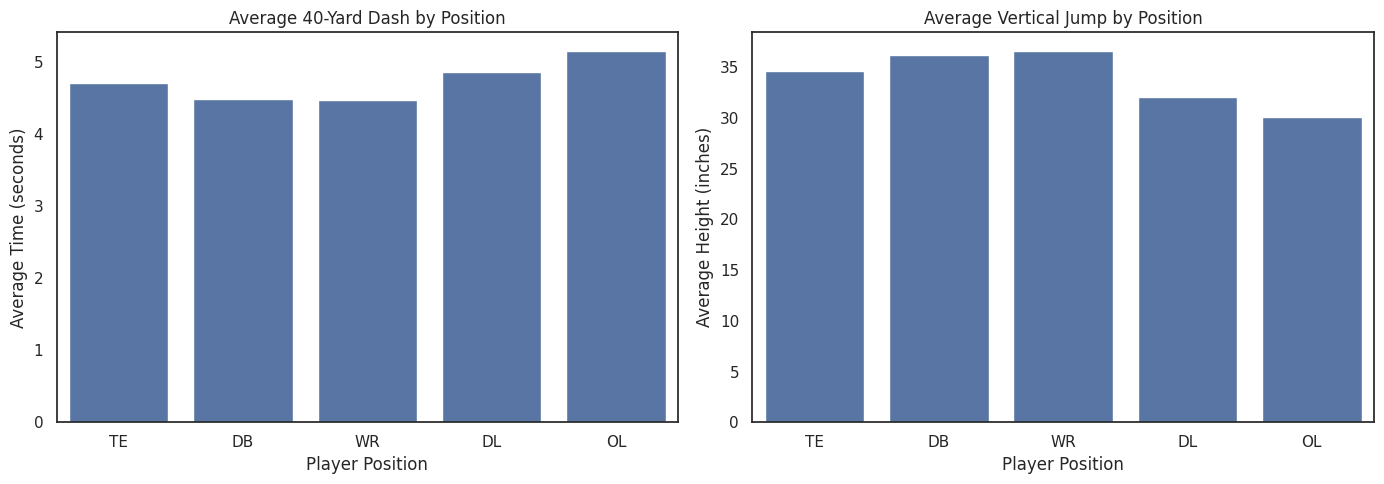

In [801]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average 40-yard dash time by position
sns.barplot(
    data=combine_results_df,
    x="combine_position",
    y="forty",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Average 40-Yard Dash by Position")
axes[0].set_xlabel("Player Position")
axes[0].set_ylabel("Average Time (seconds)")

# Average vertical jump by position
sns.barplot(
    data=combine_results_df,
    x="combine_position",
    y="vertical",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Average Vertical Jump by Position")
axes[1].set_xlabel("Player Position")
axes[1].set_ylabel("Average Height (inches)")

plt.tight_layout()
plt.show()

### **Combine Performance — Visualization Findings**

- WRs and DBs show lower average 40-yard dash times than other positions.
- WRs have the highest average vertical jump, followed closely by DBs.
- OL players show the highest average sprint time and lowest average vertical jump.

**Conclusion:** Speed and jumping performance vary across player positions, showing differences in position-wise athletic profiles.

In [802]:
# Compare average Combine measurements across draft years
year_performance = (
    combine_results_df
    .groupby("draft_year")[combine_metrics]
    .mean()
    .round(2)
)

print("=" * 55)
print("COMBINE PERFORMANCE BY DRAFT YEAR")
print("=" * 55)

display(year_performance)

COMBINE PERFORMANCE BY DRAFT YEAR


,ten_yd_split,forty,vertical,broad_jump,three_cone
draft_year,,,,,
2023,1.63,4.74,33.72,118.74,7.33
2024,1.63,4.74,34.16,118.09,7.32
2025,1.63,4.73,33.51,117.59,7.29


### **Combine Performance Across Draft Years — Key Findings**

- Average 10-yard split remained consistent at 1.63 seconds across all three years.
- The average 40-yard dash time was nearly identical across draft classes.
- The 2024 class had the highest average vertical jump (34.16 inches).
- The 2023 class had the highest average broad jump (118.74 inches).
- The 2025 class had the lowest average three-cone time (7.29 seconds).

**Conclusion:** Average Combine measurements remained relatively consistent across the 2023–2025 draft classes, with only small differences between years.

In [803]:
print("=" * 50)
print("NFL CAREER SUCCESS DATASET OVERVIEW")
print("=" * 50)

print("Dataset Shape:", career_success_df.shape)

career_success_df.info()

print("\nAvailable Columns:")
display(pd.DataFrame({
    "Column": career_success_df.columns,
    "Data_Type": career_success_df.dtypes.astype(str).values,
    "Missing_Values": career_success_df.isnull().sum().values
}))

NFL CAREER SUCCESS DATASET OVERVIEW
Dataset Shape: (510, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   nfl_id                      510 non-null    int64
 1   career_offensive_snaps      510 non-null    int64
 2   career_defensive_snaps      510 non-null    int64
 3   career_special_teams_snaps  510 non-null    int64
 4   career_games_active         510 non-null    int64
 5   career_games_started        510 non-null    int64
 6   ap_all_pro_1st_team         510 non-null    int64
 7   ap_all_pro_2nd_team         510 non-null    int64
 8   pro_bowl_original_ballot    510 non-null    int64
dtypes: int64(9)
memory usage: 36.0 KB

Available Columns:


,Column,Data_Type,Missing_Values
0,nfl_id,int64,0
1,career_offensive_snaps,int64,0
2,career_defensive_snaps,int64,0
3,career_special_teams_snaps,int64,0
4,career_games_active,int64,0
5,career_games_started,int64,0
6,ap_all_pro_1st_team,int64,0
7,ap_all_pro_2nd_team,int64,0
8,pro_bowl_original_ballot,int64,0


In [804]:
# Select career performance metrics
career_metrics = [
    "career_offensive_snaps",
    "career_defensive_snaps",
    "career_special_teams_snaps",
    "career_games_active",
    "career_games_started",
    "ap_all_pro_1st_team",
    "ap_all_pro_2nd_team",
    "pro_bowl_original_ballot"
]

print("=" * 60)
print("NFL CAREER SUCCESS — SUMMARY STATISTICS")
print("=" * 60)

career_summary = (
    career_success_df[career_metrics]
    .describe()
    .T
    .round(2)
)

display(career_summary)

NFL CAREER SUCCESS — SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
career_offensive_snaps,510.0,327.42,632.40,0.0,0.00,0.0,361.75,3303.0
career_defensive_snaps,510.0,234.31,492.12,0.0,0.00,0.0,220.50,2666.0
career_special_teams_snaps,510.0,113.50,156.19,0.0,5.00,53.0,147.75,957.0
career_games_active,510.0,21.72,16.29,0.0,6.25,17.0,34.00,51.0
career_games_started,510.0,7.85,11.47,0.0,0.00,2.0,12.00,50.0
ap_all_pro_1st_team,510.0,0.01,0.11,0.0,0.00,0.0,0.00,1.0
ap_all_pro_2nd_team,510.0,0.00,0.06,0.0,0.00,0.0,0.00,1.0
pro_bowl_original_ballot,510.0,0.03,0.20,0.0,0.00,0.0,0.00,2.0


### **NFL Career Success — Key Findings**

- Players averaged 21.72 active games and 7.85 games started.
- The maximum career active games recorded were 51.
- Offensive snaps reached a maximum of 3,303.
- Defensive snaps reached a maximum of 2,666.
- Special teams snaps reached a maximum of 957.
- All-Pro and Pro Bowl recognition metrics contain mostly zero values.

**Conclusion:** Career participation varies considerably across players. Snap counts, games active, and award recognition provide different perspectives on NFL career performance.

In [805]:
# Compare average career snap counts
snap_metrics = [
    "career_offensive_snaps",
    "career_defensive_snaps",
    "career_special_teams_snaps"
]

snap_summary = (
    career_success_df[snap_metrics]
    .agg(["mean", "median", "max"])
    .T
    .round(2)
)

print("=" * 55)
print("CAREER SNAP DISTRIBUTION")
print("=" * 55)

display(snap_summary)

CAREER SNAP DISTRIBUTION


,mean,median,max
career_offensive_snaps,327.42,0.0,3303.0
career_defensive_snaps,234.31,0.0,2666.0
career_special_teams_snaps,113.50,53.0,957.0


### **Career Snap Distribution — Key Findings**

- Offensive snaps have an average of 327.42, while the median is 0.
- Defensive snaps have an average of 234.31, while the median is 0.
- Special teams snaps have an average of 113.50 and a median of 53.
- Offensive and defensive snap counts show substantial differences between players.

**Conclusion:** Career participation is uneven across players. Mean and median values together provide a clearer picture of snap distribution.

In [806]:
print("=" * 55)
print("PLAYERS WITH NON-ZERO CAREER SNAPS")
print("=" * 55)

non_zero_snaps = (
    (career_success_df[snap_metrics] > 0)
    .sum()
    .to_frame(name="Players_With_Snaps")
)

non_zero_snaps["Percentage"] = (
    non_zero_snaps["Players_With_Snaps"]
    / len(career_success_df) * 100
).round(2)

display(non_zero_snaps)

PLAYERS WITH NON-ZERO CAREER SNAPS


,Players_With_Snaps,Percentage
career_offensive_snaps,213,41.76
career_defensive_snaps,193,37.84
career_special_teams_snaps,402,78.82


### **Career Participation — Key Findings**

- 78.82% of players recorded non-zero special teams snaps.
- 41.76% recorded non-zero offensive snaps.
- 37.84% recorded non-zero defensive snaps.
- Special teams had the highest player participation, while defense had the lowest.

**Conclusion:** Special teams participation was more widespread than offensive and defensive participation among the 510 players.

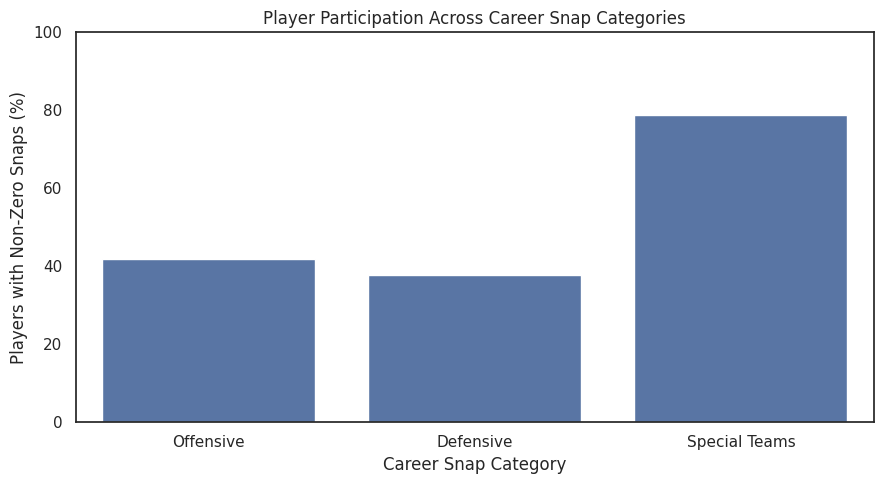

In [807]:
participation = non_zero_snaps.reset_index()
participation["Category"] = participation["index"].str.replace(
    "career_", "", regex=False
).str.replace("_snaps", "", regex=False).str.replace("_", " ").str.title()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=participation,
    x="Category",
    y="Percentage"
)

plt.title("Player Participation Across Career Snap Categories")
plt.xlabel("Career Snap Category")
plt.ylabel("Players with Non-Zero Snaps (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [808]:
# Merge Combine Results with NFL Career Success
combine_career_df = combine_results_df.merge(
    career_success_df,
    on="nfl_id",
    how="inner"
)

print("=" * 60)
print("COMBINE + NFL CAREER SUCCESS DATASET")
print("=" * 60)

print("Merged Dataset Shape:", combine_career_df.shape)
print("Unique Players:", combine_career_df["nfl_id"].nunique())

display(combine_career_df.head())

COMBINE + NFL CAREER SUCCESS DATASET
Merged Dataset Shape: (510, 26)
Unique Players: 510


,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,...,ngs_college_production_score,ngs_final_score,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,...,NaN,NaN,1085,0,431,51,11,0,0,0
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,...,77.0,74.0,0,75,487,41,2,0,0,0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,...,65.0,79.0,3,0,10,3,0,0,0,0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,...,68.0,73.0,1022,0,60,38,11,0,0,0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,...,65.0,64.0,334,0,135,30,0,0,0,0


In [809]:
# Combine athletic performance metrics
combine_analysis_metrics = [
    "ten_yd_split",
    "forty",
    "vertical",
    "broad_jump",
    "three_cone"
]

# NFL career success metrics
career_analysis_metrics = [
    "career_offensive_snaps",
    "career_defensive_snaps",
    "career_special_teams_snaps",
    "career_games_active",
    "career_games_started"
]

print("=" * 60)
print("COMBINE AND CAREER ANALYSIS METRICS")
print("=" * 60)

print("\nCombine Metrics:")
print(combine_analysis_metrics)

print("\nCareer Success Metrics:")
print(career_analysis_metrics)

COMBINE AND CAREER ANALYSIS METRICS

Combine Metrics:
['ten_yd_split', 'forty', 'vertical', 'broad_jump', 'three_cone']

Career Success Metrics:
['career_offensive_snaps', 'career_defensive_snaps', 'career_special_teams_snaps', 'career_games_active', 'career_games_started']


In [810]:
print("=" * 60)
print("COMBINE AND CAREER METRICS — DATA AVAILABILITY")
print("=" * 60)

availability = combine_career_df[
    combine_analysis_metrics + career_analysis_metrics
].notna().sum().to_frame(name="Available_Records")

availability["Missing_Records"] = (
    len(combine_career_df) - availability["Available_Records"]
)

availability["Available_Percentage"] = (
    availability["Available_Records"] / len(combine_career_df) * 100
).round(2)

display(availability)

COMBINE AND CAREER METRICS — DATA AVAILABILITY


,Available_Records,Missing_Records,Available_Percentage
ten_yd_split,425,85,83.33
forty,424,86,83.14
vertical,438,72,85.88
broad_jump,423,87,82.94
three_cone,180,330,35.29
career_offensive_snaps,510,0,100.00
career_defensive_snaps,510,0,100.00
career_special_teams_snaps,510,0,100.00
career_games_active,510,0,100.00
career_games_started,510,0,100.00


In [811]:
# Calculate pairwise correlations
correlation_matrix = combine_career_df[
    combine_analysis_metrics + career_analysis_metrics
].corr(method="spearman")

# Extract Combine vs Career relationships
combine_career_corr = correlation_matrix.loc[
    combine_analysis_metrics,
    career_analysis_metrics
].round(3)

print("=" * 65)
print("COMBINE PERFORMANCE VS NFL CAREER SUCCESS — SPEARMAN CORRELATION")
print("=" * 65)

display(combine_career_corr)

COMBINE PERFORMANCE VS NFL CAREER SUCCESS — SPEARMAN CORRELATION


,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
ten_yd_split,0.066,-0.140,-0.108,-0.058,-0.058
forty,0.078,-0.163,-0.105,-0.079,-0.054
vertical,0.026,0.123,0.141,0.131,0.110
broad_jump,-0.059,0.156,0.118,0.106,0.059
three_cone,0.001,-0.081,-0.144,-0.043,-0.052


In [812]:
# Investigate missing Three-Cone correlations
three_cone_check = combine_career_df[
    ["three_cone", "career_games_active", "career_games_started"]
]

print("=" * 60)
print("THREE-CONE CORRELATION DATA CHECK")
print("=" * 60)

display(pd.DataFrame({
    "Available_Records": three_cone_check.notna().sum(),
    "Unique_Values": three_cone_check.nunique(),
    "Missing_Records": three_cone_check.isna().sum()
}))

print("\nPairwise Spearman Correlations:")
display(
    three_cone_check.corr(method="spearman").round(3)
)

THREE-CONE CORRELATION DATA CHECK


,Available_Records,Unique_Values,Missing_Records
three_cone,180,95,330
career_games_active,510,51,0
career_games_started,510,46,0



Pairwise Spearman Correlations:


,three_cone,career_games_active,career_games_started
three_cone,1.000,-0.043,-0.052
career_games_active,-0.043,1.000,0.702
career_games_started,-0.052,0.702,1.000


### **Three-Cone Correlation — Additional Findings**

- Three-cone results were available for only 180 players.
- Three-cone showed negligible negative correlations with games active (-0.043) and games started (-0.052).
- Games active and games started showed a positive correlation of 0.702.

**Conclusion:** Three-cone performance showed almost no monotonic relationship with these two career participation metrics in the available sample. Games active and games started were more closely related.

In [813]:
combine_career_corr = combine_career_df[
    combine_analysis_metrics + career_analysis_metrics
].corr(method="spearman").loc[
    combine_analysis_metrics,
    career_analysis_metrics
].round(3)

display(combine_career_corr)

,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
ten_yd_split,0.066,-0.140,-0.108,-0.058,-0.058
forty,0.078,-0.163,-0.105,-0.079,-0.054
vertical,0.026,0.123,0.141,0.131,0.110
broad_jump,-0.059,0.156,0.118,0.106,0.059
three_cone,0.001,-0.081,-0.144,-0.043,-0.052


In [814]:
print("=" * 55)
print("POSITION-WISE PLAYER COUNTS")
print("=" * 55)

display(
    combine_career_df["combine_position"]
    .value_counts()
    .rename_axis("Position")
    .to_frame("Player_Count")
)

POSITION-WISE PLAYER COUNTS


,Player_Count
Position,
DB,122
OL,121
DL,118
WR,107
TE,42


In [815]:
print("=" * 65)
print("POSITION-WISE COMBINE VS CAREER SUCCESS CORRELATION")
print("=" * 65)

position_correlations = {}

for position in combine_career_df["combine_position"].unique():

    position_df = combine_career_df[
        combine_career_df["combine_position"] == position
    ]

    correlation = position_df[
        combine_analysis_metrics + career_analysis_metrics
    ].corr(method="spearman").loc[
        combine_analysis_metrics,
        career_analysis_metrics
    ].round(3)

    position_correlations[position] = correlation

    print(f"\n{'=' * 55}")
    print(f"POSITION: {position} | PLAYERS: {len(position_df)}")
    print("=" * 55)

    display(correlation)

POSITION-WISE COMBINE VS CAREER SUCCESS CORRELATION

POSITION: TE | PLAYERS: 42


,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
ten_yd_split,-0.011,NaN,0.070,0.106,0.026
forty,-0.009,NaN,0.048,-0.186,0.106
vertical,-0.063,NaN,-0.122,0.028,-0.160
broad_jump,0.049,NaN,-0.029,0.021,-0.016
three_cone,0.009,NaN,0.192,0.130,-0.022



POSITION: DB | PLAYERS: 122


,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
ten_yd_split,0.017,-0.213,-0.019,-0.136,-0.142
forty,0.145,-0.141,0.072,-0.006,-0.095
vertical,0.102,0.215,0.070,0.155,0.198
broad_jump,0.032,0.259,0.021,0.111,0.251
three_cone,NaN,0.084,0.137,0.010,0.009



POSITION: WR | PLAYERS: 107


,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
ten_yd_split,-0.159,NaN,-0.108,-0.123,-0.187
forty,-0.150,NaN,-0.187,-0.155,-0.181
vertical,0.434,NaN,0.341,0.384,0.415
broad_jump,0.309,NaN,0.172,0.281,0.350
three_cone,-0.386,NaN,-0.062,-0.143,-0.524



POSITION: DL | PLAYERS: 118


,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
ten_yd_split,0.013,-0.132,-0.317,-0.260,-0.065
forty,0.032,-0.125,-0.333,-0.270,-0.077
vertical,0.024,0.195,0.260,0.185,0.151
broad_jump,-0.064,0.149,0.362,0.269,0.085
three_cone,NaN,0.058,-0.215,-0.047,0.017



POSITION: OL | PLAYERS: 121


,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started
ten_yd_split,-0.106,NaN,-0.062,-0.060,-0.118
forty,-0.206,NaN,-0.148,-0.172,-0.213
vertical,0.116,NaN,0.073,0.071,0.088
broad_jump,0.134,NaN,0.116,0.138,0.125
three_cone,-0.187,NaN,-0.140,-0.241,-0.202


In [816]:
print("=" * 60)
print("POSITION-WISE CORRELATION DATA CHECK")
print("=" * 60)

for position in ["DB", "WR", "DL", "OL", "TE"]:

    position_df = combine_career_df[
        combine_career_df["combine_position"] == position
    ]

    print(f"\nPOSITION: {position}")

    check = position_df[
        combine_analysis_metrics + career_analysis_metrics
    ].agg(["count", "nunique"]).T

    display(check)

POSITION-WISE CORRELATION DATA CHECK

POSITION: DB


,count,nunique
ten_yd_split,104,16
forty,104,35
vertical,105,28
broad_jump,98,25
three_cone,25,20
career_offensive_snaps,122,2
career_defensive_snaps,122,90
career_special_teams_snaps,122,93
career_games_active,122,35
career_games_started,122,29



POSITION: WR


,count,nunique
ten_yd_split,97,14
forty,97,32
vertical,96,26
broad_jump,95,21
three_cone,33,24
career_offensive_snaps,107,81
career_defensive_snaps,107,1
career_special_teams_snaps,107,63
career_games_active,107,31
career_games_started,107,28



POSITION: DL


,count,nunique
ten_yd_split,94,28
forty,94,58
vertical,102,29
broad_jump,97,33
three_cone,43,35
career_offensive_snaps,118,2
career_defensive_snaps,118,97
career_special_teams_snaps,118,80
career_games_active,118,33
career_games_started,118,25



POSITION: OL


,count,nunique
ten_yd_split,96,23
forty,95,45
vertical,100,27
broad_jump,98,21
three_cone,61,43
career_offensive_snaps,121,91
career_defensive_snaps,121,1
career_special_teams_snaps,121,76
career_games_active,121,33
career_games_started,121,35



POSITION: TE


,count,nunique
ten_yd_split,34,13
forty,34,23
vertical,35,17
broad_jump,35,14
three_cone,18,17
career_offensive_snaps,42,34
career_defensive_snaps,42,1
career_special_teams_snaps,42,34
career_games_active,42,20
career_games_started,42,19


In [817]:
print("=" * 60)
print("INVESTIGATING UNDEFINED CORRELATIONS")
print("=" * 60)

for position, corr_df in position_correlations.items():

    nan_pairs = corr_df.stack(future_stack=True)
    nan_pairs = nan_pairs[nan_pairs.isna()]

    if len(nan_pairs) == 0:
        continue

    position_df = combine_career_df[
        combine_career_df["combine_position"] == position
    ]

    for combine_metric, career_metric in nan_pairs.index:

        pair_data = position_df[
            [combine_metric, career_metric]
        ].dropna()

        print(
            f"\nPosition: {position} | "
            f"{combine_metric} vs {career_metric}"
        )

        print("Paired Records:", len(pair_data))
        print("Combine Unique Values:", pair_data[combine_metric].nunique())
        print("Career Unique Values:", pair_data[career_metric].nunique())

INVESTIGATING UNDEFINED CORRELATIONS

Position: TE | ten_yd_split vs career_defensive_snaps
Paired Records: 34
Combine Unique Values: 13
Career Unique Values: 1

Position: TE | forty vs career_defensive_snaps
Paired Records: 34
Combine Unique Values: 23
Career Unique Values: 1

Position: TE | vertical vs career_defensive_snaps
Paired Records: 35
Combine Unique Values: 17
Career Unique Values: 1

Position: TE | broad_jump vs career_defensive_snaps
Paired Records: 35
Combine Unique Values: 14
Career Unique Values: 1

Position: TE | three_cone vs career_defensive_snaps
Paired Records: 18
Combine Unique Values: 17
Career Unique Values: 1

Position: DB | three_cone vs career_offensive_snaps
Paired Records: 25
Combine Unique Values: 20
Career Unique Values: 1

Position: WR | ten_yd_split vs career_defensive_snaps
Paired Records: 97
Combine Unique Values: 14
Career Unique Values: 1

Position: WR | forty vs career_defensive_snaps
Paired Records: 97
Combine Unique Values: 32
Career Unique Value

### **Undefined Correlations — Investigation Findings**

- Several position-wise correlations returned NaN because the corresponding career snap metrics had only one unique value.
- WR, OL, and TE had constant defensive snap values.
- DB and DL had constant offensive snap values within the available three-cone samples.
- Correlations cannot be calculated when one variable has no variation.

**Conclusion:** Undefined correlations were caused by constant career snap values within specific position groups, not by missing-value errors.

In [818]:
# Identify players available in both Combine and NFL Tracking

combine_player_ids = set(combine_tracking_df["nfl_id"].unique())

nfl_player_ids = set(players_df["nfl_id"].unique())

matched_player_ids = combine_player_ids.intersection(nfl_player_ids)

print("Combine Players:", len(combine_player_ids))
print("NFL Players:", len(nfl_player_ids))
print("Matched Players:", len(matched_player_ids))
print("Combine-only Players:", len(combine_player_ids - nfl_player_ids))

Combine Players: 510
NFL Players: 510
Matched Players: 510
Combine-only Players: 0


In [819]:
nfl_tracking_ids = set()

for df in [tracking_2023_df, tracking_2024_df, tracking_2025_df]:
    nfl_tracking_ids.update(df["nfl_id"].dropna().unique())

combine_tracking_ids = set(
    combine_tracking_df["nfl_id"].unique()
)

matched_player_ids = combine_tracking_ids.intersection(nfl_tracking_ids)

print("Combine Players:", len(combine_tracking_ids))
print("NFL Tracked Players:", len(nfl_tracking_ids))
print("Matched Players:", len(matched_player_ids))
print("Combine-only Players:", len(combine_tracking_ids - nfl_tracking_ids))

Combine Players: 510
NFL Tracked Players: 497
Matched Players: 497
Combine-only Players: 13


In [820]:
# Filter matched players and PLAYER records

combine_tracking_matched = combine_tracking_df[
    (combine_tracking_df["nfl_id"].isin(matched_player_ids)) &
    (combine_tracking_df["entity_type"] == "PLAYER")
].copy()

print("Original Combine Tracking:", combine_tracking_df.shape)
print("Matched Player Tracking:", combine_tracking_matched.shape)
print("Unique Players:", combine_tracking_matched["nfl_id"].nunique())
print("\nDrill Types:")
display(combine_tracking_matched["drill_type"].value_counts().to_frame("Records"))

Original Combine Tracking: (463189, 14)
Matched Player Tracking: (418761, 14)
Unique Players: 497

Drill Types:


,Records
drill_type,
SKILL_DRILLS_WR,95581
SKILL_DRILLS_DB,91244
SKILL_DRILLS_DL,74925
SKILL_DRILLS_OL,60665
FORTY_YARD_DASH,40364
SKILL_DRILLS_TE,26156
THREE_CONE_DRILL,15241
SHORT_SHUTTLE,11322
SKILL_DRILLS_LB,3263


In [821]:
# Combine NFL tracking data from all three seasons

nfl_tracking_df = pd.concat(
    [tracking_2023_df, tracking_2024_df, tracking_2025_df],
    ignore_index=True
)

# Keep only the 497 matched players

nfl_tracking_matched = nfl_tracking_df[
    nfl_tracking_df["nfl_id"].isin(matched_player_ids)
].copy()

print("Combined NFL Tracking Shape:", nfl_tracking_df.shape)
print("Matched NFL Tracking Shape:", nfl_tracking_matched.shape)
print("Unique Players:", nfl_tracking_matched["nfl_id"].nunique())

print("\nColumns:")
print(nfl_tracking_matched.columns.tolist())

Combined NFL Tracking Shape: (22654290, 12)
Matched NFL Tracking Shape: (22654290, 12)
Unique Players: 497

Columns:
['game_id', 'play_id', 'nfl_id', 'time', 'x', 'y', 's', 'a', 'dis', 'o', 'dir', 'event']


In [822]:
print("NFL Tracking Coverage Check")
print("=" * 50)

print("Total rows:", len(nfl_tracking_df))
print("Rows after filtering:", len(nfl_tracking_matched))

print(
    "Rows with unmatched player IDs:",
    (~nfl_tracking_df["nfl_id"].isin(matched_player_ids)).sum()
)

print(
    "Unique NFL IDs:",
    nfl_tracking_df["nfl_id"].nunique()
)

print(
    "Missing NFL IDs:",
    nfl_tracking_df["nfl_id"].isna().sum()
)

NFL Tracking Coverage Check
Total rows: 22654290
Rows after filtering: 22654290
Rows with unmatched player IDs: 0
Unique NFL IDs: 497
Missing NFL IDs: 0


In [823]:
# Compare movement feature availability

movement_features = ["x", "y", "s", "a", "dis", "dir"]

print("COMBINE TRACKING")
display(combine_tracking_matched[movement_features].describe().round(3))

print("\nNFL TRACKING")
display(nfl_tracking_matched[movement_features].describe().round(3))

COMBINE TRACKING


,x,y,s,a,dis,dir
count,418761.000,418761.000,418761.000,418761.000,418761.000,418761.000
mean,45.043,23.934,4.926,2.834,0.299,148.568
std,17.183,14.400,2.843,1.848,0.284,96.637
min,1.300,-7.200,0.000,0.000,0.000,0.000
25%,36.200,14.533,2.437,1.273,0.054,88.157
50%,44.667,25.900,4.967,2.569,0.218,109.575
75%,48.367,30.449,7.290,4.142,0.490,226.506
max,103.900,66.283,11.854,10.718,1.440,360.000



NFL TRACKING


,x,y,s,a,dis,dir
count,2.265429e+07,2.265429e+07,2.265429e+07,2.265429e+07,2.265429e+07,2.265429e+07
mean,5.990700e+01,2.675900e+01,2.497000e+00,1.579000e+00,2.540000e-01,1.800190e+02
std,2.450500e+01,9.393000e+00,2.071000e+00,1.223000e+00,2.080000e-01,1.032610e+02
min,-6.330000e+00,-8.780000e+00,0.000000e+00,-1.439600e+01,0.000000e+00,0.000000e+00
25%,4.153000e+01,2.116000e+01,8.200000e-01,6.500000e-01,8.000000e-02,9.010000e+01
50%,5.987000e+01,2.677000e+01,2.070000e+00,1.360000e+00,2.100000e-01,1.799000e+02
75%,7.833000e+01,3.234000e+01,3.730000e+00,2.260000e+00,3.800000e-01,2.696100e+02
max,1.274000e+02,6.396000e+01,1.688000e+01,3.375900e+01,1.686000e+01,3.600000e+02


In [824]:
# Investigate extreme movement values

for name, df in [
    ("Combine Tracking", combine_tracking_matched),
    ("NFL Tracking", nfl_tracking_matched)
]:
    print(f"\n{'='*55}")
    print(name)
    print("="*55)

    for col in ["s", "a", "dis"]:
        print(f"\n{col} — Highest 10 values:")
        display(
            df.nlargest(10, col)[
                ["nfl_id", "time", col]
            ]
        )


Combine Tracking

s — Highest 10 values:


,nfl_id,time,s
30306,58232,2025-02-28T20:40:55.800,11.854232
30307,58232,2025-02-28T20:40:55.900,11.847415
30305,58232,2025-02-28T20:40:55.700,11.846446
30308,58232,2025-02-28T20:40:56.000,11.816277
136270,59278,2025-03-01T20:40:17.300,11.814824
136269,59278,2025-03-01T20:40:17.200,11.810047
136268,59278,2025-03-01T20:40:17.100,11.795930
136267,59278,2025-03-01T20:40:17.000,11.766748
30304,58232,2025-02-28T20:40:55.600,11.765822
136318,59278,2025-03-01T20:54:04.400,11.759384



a — Highest 10 values:


,nfl_id,time,a
300823,57221,2024-03-02T22:06:23.100,10.717722
300824,57221,2024-03-02T22:06:23.200,10.376444
8919,58242,2025-03-02T21:12:18.800,10.148666
8920,58242,2025-03-02T21:12:18.900,10.036954
300822,57221,2024-03-02T22:06:23.000,10.036941
316235,57741,2024-03-02T01:57:27.000,9.941708
316236,57741,2024-03-02T01:57:27.100,9.890699
316234,57741,2024-03-02T01:57:26.900,9.890160
8918,58242,2025-03-02T21:12:18.700,9.852519
289869,57874,2024-03-02T02:06:14.800,9.839133



dis — Highest 10 values:


,nfl_id,time,dis
402878,55970,2023-03-03T20:40:16.300,1.440000
402882,55970,2023-03-03T20:40:16.700,1.440000
30305,58232,2025-02-28T20:40:55.700,1.428067
30307,58232,2025-02-28T20:40:55.900,1.401340
30306,58232,2025-02-28T20:40:55.800,1.399101
136270,59278,2025-03-01T20:40:17.300,1.398427
30308,58232,2025-02-28T20:40:56.000,1.392599
136269,59278,2025-03-01T20:40:17.200,1.391483
136268,59278,2025-03-01T20:40:17.100,1.389803
136317,59278,2025-03-01T20:54:04.300,1.389204


... (2 outputs left out)


a — Highest 10 values:


,nfl_id,time,a
12558229,57155,2025-10-12T17:54:04.400,33.759
6943935,57145,2024-10-20T19:47:21.200,22.020
6943941,57145,2024-10-20T19:47:21.800,19.840
6943942,57145,2024-10-20T19:47:21.900,18.470
3238902,55978,2023-12-31T19:45:52.100,18.330
3028281,56052,2023-09-10T20:43:05.100,18.320
3028282,56052,2023-09-10T20:43:05.200,17.780
3238901,55978,2023-12-31T19:45:52.000,17.230
6943936,57145,2024-10-20T19:47:21.300,17.000
3238903,55978,2023-12-31T19:45:52.200,16.760



dis — Highest 10 values:


,nfl_id,time,dis
5265005,57144,2024-10-13T13:36:29.200,16.86
4170303,55943,2024-10-13T17:18:49.500,5.03
6546084,57304,2024-11-12T03:25:21.000,4.45
5423645,55891,2024-10-13T13:36:29.200,4.36
16688720,58413,2026-01-03T22:15:17.800,4.20
16688690,58413,2026-01-03T22:15:14.800,4.12
6943935,57145,2024-10-20T19:47:21.200,3.57
562566,55989,2023-09-17T19:02:52.400,3.44
2227387,56075,2023-09-10T21:32:34.400,3.40
6546086,57304,2024-11-12T03:25:21.200,2.89


In [825]:
# Inspect surrounding frames of the highest NFL distance value

outlier = nfl_tracking_matched.loc[
    nfl_tracking_matched["dis"].idxmax()
]

outlier_game = outlier["game_id"]
outlier_play = outlier["play_id"]
outlier_player = outlier["nfl_id"]

outlier_context = nfl_tracking_matched[
    (nfl_tracking_matched["game_id"] == outlier_game) &
    (nfl_tracking_matched["play_id"] == outlier_play) &
    (nfl_tracking_matched["nfl_id"] == outlier_player)
].sort_values("time")

display(
    outlier_context[
        ["game_id", "play_id", "nfl_id",
         "time", "x", "y", "s", "a", "dis", "dir", "event"]
    ]
)

,game_id,play_id,nfl_id,time,x,y,s,a,dis,dir,event
5264950,2024101300,243,57144,2024-10-13T13:36:23.700,90.33,15.90,0.00,0.00,0.00,0.00,NaN
5264951,2024101300,243,57144,2024-10-13T13:36:23.800,90.33,15.90,0.00,0.00,0.00,0.00,NaN
5264952,2024101300,243,57144,2024-10-13T13:36:23.900,90.33,15.90,0.00,0.00,0.00,0.00,NaN
5264953,2024101300,243,57144,2024-10-13T13:36:24.000,90.33,15.90,0.00,0.00,0.00,0.00,NaN
5264954,2024101300,243,57144,2024-10-13T13:36:24.100,90.33,15.90,0.00,0.00,0.00,0.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...
5265010,2024101300,243,57144,2024-10-13T13:36:29.700,81.09,3.96,1.14,3.03,0.13,212.79,NaN
5265011,2024101300,243,57144,2024-10-13T13:36:29.800,81.03,3.88,0.94,2.74,0.10,223.64,NaN
5265012,2024101300,243,57144,2024-10-13T13:36:29.900,80.97,3.83,0.88,2.40,0.08,236.99,NaN
5265013,2024101300,243,57144,2024-10-13T13:36:30.000,80.91,3.80,0.93,1.97,0.08,250.61,NaN


In [826]:
outlier_context = outlier_context.sort_values("time").copy()

outlier_context["position_change"] = (
    (outlier_context["x"].diff() ** 2 +
     outlier_context["y"].diff() ** 2) ** 0.5
)

display(
    outlier_context[
        ["time", "x", "y", "dis", "position_change"]
    ].sort_values("dis", ascending=False).head(10)
)

,time,x,y,dis,position_change
5265005,2024-10-13T13:36:29.200,81.41,4.78,16.86,0.228035
5264981,2024-10-13T13:36:26.800,83.70,10.20,0.58,0.578705
5264978,2024-10-13T13:36:26.500,84.07,11.83,0.58,0.575847
5264974,2024-10-13T13:36:26.100,85.17,13.73,0.57,0.565685
5264982,2024-10-13T13:36:26.900,83.67,9.63,0.57,0.570789
5264977,2024-10-13T13:36:26.400,84.27,12.37,0.56,0.563560
5264979,2024-10-13T13:36:26.600,83.90,11.30,0.56,0.556597
5264976,2024-10-13T13:36:26.300,84.53,12.87,0.55,0.549181
5264980,2024-10-13T13:36:26.700,83.80,10.77,0.54,0.539351
5264970,2024-10-13T13:36:25.700,86.87,15.00,0.54,0.538516


### **Extreme Distance Value Investigation**

- The maximum NFL tracking distance value was 16.86.
- The corresponding coordinate-based position change was only 0.228.
- Most other high-distance observations showed close agreement between recorded distance and coordinate-based movement.
- The maximum value appears inconsistent with the observed player position change.

**Conclusion:** An extreme distance observation was identified in NFL tracking data. It will be preserved in the original dataset but treated cautiously during subsequent analysis.

In [827]:
movement_features = ["s", "a", "dis"]

# Combine player-level averages
combine_player_summary = (
    combine_tracking_matched
    .groupby("nfl_id")[movement_features]
    .mean()
    .reset_index()
)

# NFL player-level averages
nfl_player_summary = (
    nfl_tracking_matched
    .groupby("nfl_id")[movement_features]
    .mean()
    .reset_index()
)

print("COMBINE PLAYER SUMMARY")
display(combine_player_summary.head())

print("NFL PLAYER SUMMARY")
display(nfl_player_summary.head())

print("Combine players:", combine_player_summary["nfl_id"].nunique())
print("NFL players:", nfl_player_summary["nfl_id"].nunique())

COMBINE PLAYER SUMMARY


,nfl_id,s,a,dis
0,55867,4.668225,2.814774,0.260470
1,55870,3.117726,2.920588,0.126168
2,55874,3.299775,2.604929,0.161366
3,55875,3.631252,2.678696,0.177342
4,55877,4.220661,3.099669,0.229442


NFL PLAYER SUMMARY


,nfl_id,s,a,dis
0,55867,2.474088,1.592299,0.256443
1,55870,1.632769,1.092418,0.171804
2,55874,1.811263,1.157470,0.188233
3,55875,1.745335,1.119486,0.181594
4,55877,2.606175,1.744567,0.265916


Combine players: 497
NFL players: 497


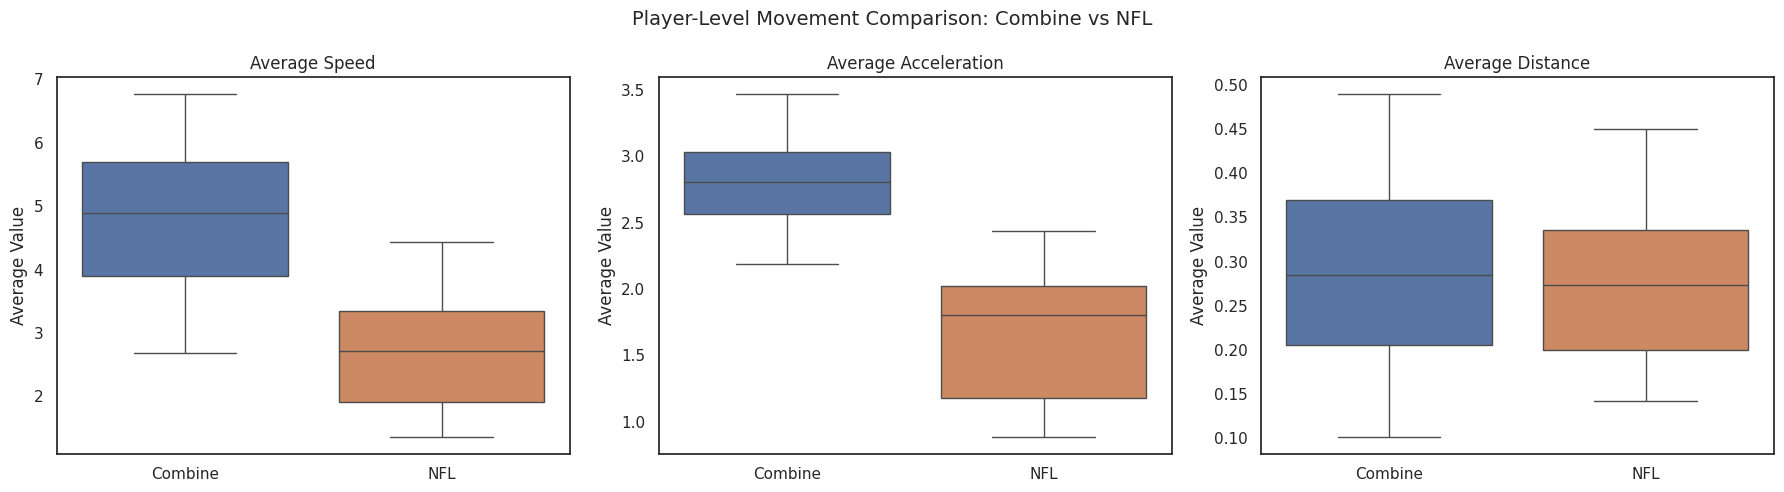

In [828]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ["s", "a", "dis"]
titles = ["Average Speed", "Average Acceleration", "Average Distance"]

for ax, feature, title in zip(axes, features, titles):

    plot_data = pd.DataFrame({
        "Combine": combine_player_summary[feature],
        "NFL": nfl_player_summary[feature]
    })

    sns.boxplot(data=plot_data, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Average Value")

plt.suptitle("Player-Level Movement Comparison: Combine vs NFL", fontsize=14)
plt.tight_layout()
plt.show()

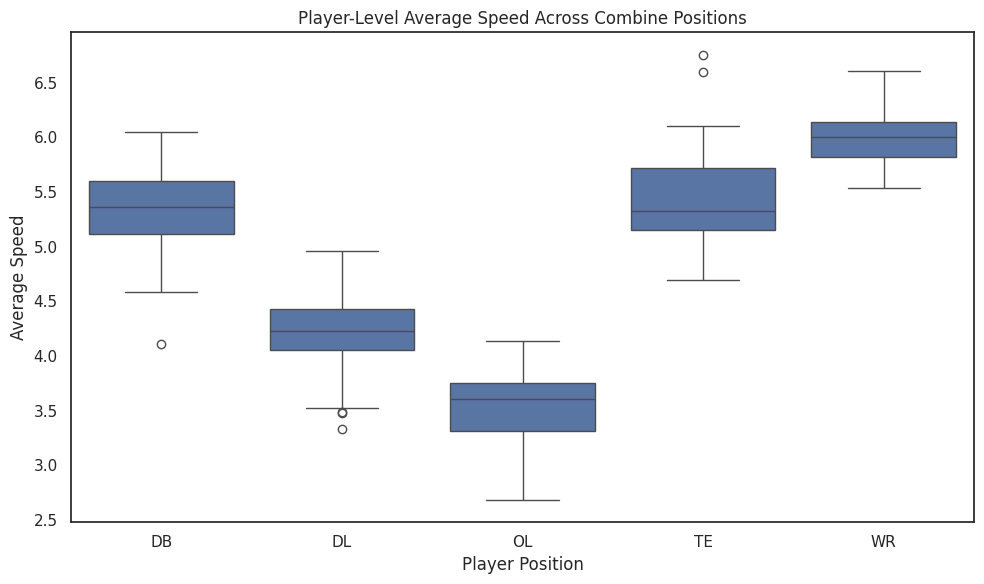

In [829]:
position_speed = (
    combine_tracking_matched
    .merge(
        combine_results_df[["nfl_id", "combine_position"]],
        on="nfl_id",
        how="left"
    )
    .groupby(["combine_position", "nfl_id"])["s"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=position_speed,
    x="combine_position",
    y="s"
)

plt.title("Player-Level Average Speed Across Combine Positions")
plt.xlabel("Player Position")
plt.ylabel("Average Speed")

plt.tight_layout()
plt.show()

In [830]:
nfl_tracking_df = pd.concat(
    [tracking_2023_df, tracking_2024_df, tracking_2025_df],
    ignore_index=True
)

nfl_tracking_matched = nfl_tracking_df[
    nfl_tracking_df["nfl_id"].isin(matched_player_ids)
].copy()

print("Shape:", nfl_tracking_matched.shape)
print("Unique Players:", nfl_tracking_matched["nfl_id"].nunique())

Shape: (22654290, 12)
Unique Players: 497


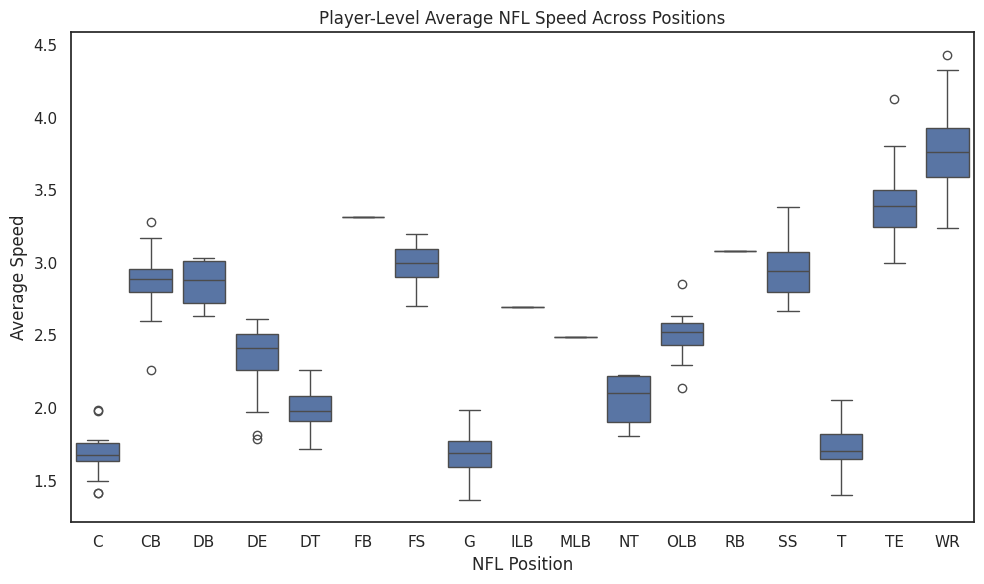

In [831]:
nfl_position_speed = (
    nfl_tracking_matched
    .merge(
        players_df[["nfl_id", "nfl_position"]],
        on="nfl_id",
        how="left"
    )
    .groupby(["nfl_position", "nfl_id"])["s"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=nfl_position_speed,
    x="nfl_position",
    y="s"
)

plt.title("Player-Level Average NFL Speed Across Positions")
plt.xlabel("NFL Position")
plt.ylabel("Average Speed")

plt.tight_layout()
plt.show()

### **Combine Vs NFL Tracking**

In [832]:
print("Combine Players:", combine_player_summary["nfl_id"].nunique())
print("NFL Players:", nfl_player_summary["nfl_id"].nunique())

print("\nMovement Features:")
display(
    combine_player_summary[["s", "a", "dis"]].describe().round(3)
)

display(
    nfl_player_summary[["s", "a", "dis"]].describe().round(3)
)

Combine Players: 497
NFL Players: 497

Movement Features:


,s,a,dis
count,497.000,497.000,497.000
mean,4.787,2.804,0.286
std,0.989,0.287,0.094
min,2.682,2.190,0.102
25%,3.900,2.563,0.206
50%,4.885,2.802,0.284
75%,5.699,3.031,0.370
max,6.757,3.466,0.489


,s,a,dis
count,497.000,497.000,497.000
mean,2.684,1.658,0.272
std,0.790,0.429,0.076
min,1.367,0.886,0.142
25%,1.909,1.180,0.200
50%,2.721,1.804,0.273
75%,3.353,2.025,0.336
max,4.435,2.437,0.449


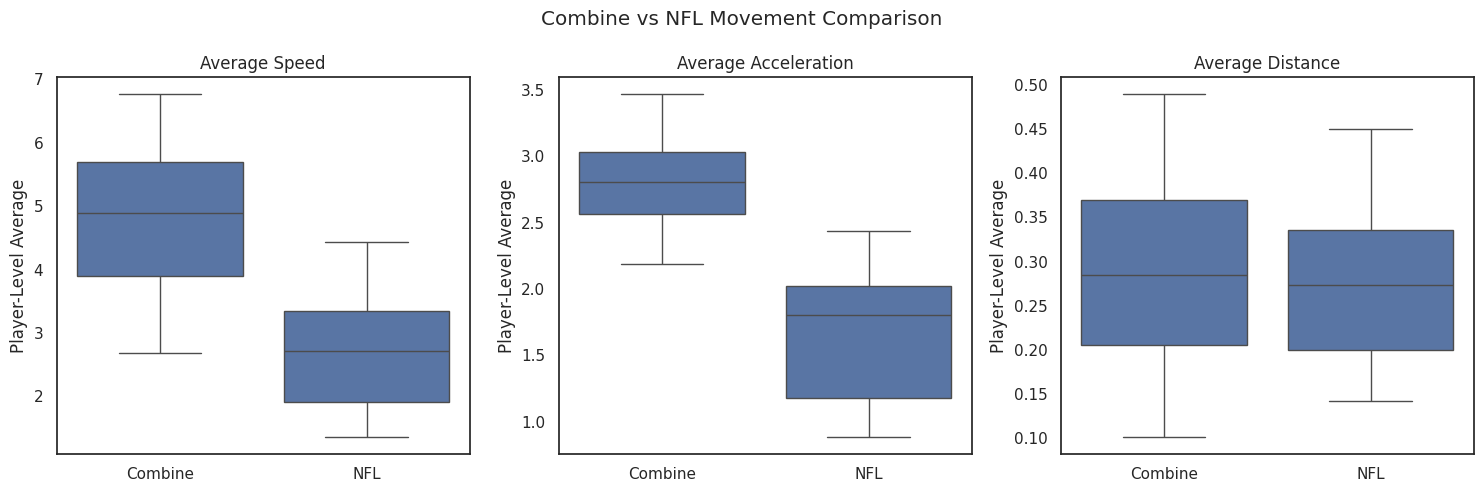

In [833]:
comparison_df = pd.concat([
    combine_player_summary.assign(Environment="Combine"),
    nfl_player_summary.assign(Environment="NFL")
], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

features = ["s", "a", "dis"]
titles = ["Average Speed", "Average Acceleration", "Average Distance"]

for ax, feature, title in zip(axes, features, titles):
    sns.boxplot(
        data=comparison_df,
        x="Environment",
        y=feature,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Player-Level Average")

plt.suptitle("Combine vs NFL Movement Comparison")
plt.tight_layout()
plt.show()

### **Combine vs NFL Movement — Key Findings**

- Combine player-level averages show higher speed and acceleration than NFL game-tracking averages.
- Average distance distributions are comparatively similar across both environments.
- Movement distributions differ between controlled Combine drills and real-game situations.

**Conclusion:** Combine and NFL tracking show different movement patterns. These differences should be interpreted in the context of their distinct environments.

In [834]:
player_movement_comparison = combine_player_summary.merge(
    nfl_player_summary,
    on="nfl_id",
    suffixes=("_combine", "_nfl")
)

correlation_results = []

for feature in ["s", "a", "dis"]:
    correlation = player_movement_comparison[
        f"{feature}_combine"
    ].corr(
        player_movement_comparison[f"{feature}_nfl"],
        method="spearman"
    )

    correlation_results.append({
        "Feature": feature,
        "Spearman_Correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(3))

,Feature,Spearman_Correlation
0,s,0.911
1,a,0.332
2,dis,0.901


### **Combine vs NFL Movement — Correlation Findings**

- Speed showed a very strong positive correlation (0.911) between Combine and NFL tracking.
- Distance also showed a very strong positive correlation (0.901).
- Acceleration showed a weaker positive correlation (0.332).

**Conclusion:** Players' relative speed and distance rankings were strongly associated across Combine and NFL tracking, while acceleration showed a weaker relationship.

In [835]:
position_corr_results = []

position_data = player_movement_comparison.merge(
    combine_results_df[["nfl_id", "combine_position"]],
    on="nfl_id",
    how="left"
)

for position, group in position_data.groupby("combine_position"):

    for feature in ["s", "a", "dis"]:

        corr = group[f"{feature}_combine"].corr(
            group[f"{feature}_nfl"],
            method="spearman"
        )

        position_corr_results.append({
            "Position": position,
            "Feature": feature,
            "Correlation": corr,
            "Players": len(group)
        })

position_corr_df = pd.DataFrame(position_corr_results)

display(position_corr_df.round(3))

,Position,Feature,Correlation,Players
0,DB,s,0.080,118
1,DB,a,-0.007,118
2,DB,dis,0.059,118
3,DL,s,0.559,115
4,DL,a,0.446,115
5,DL,dis,0.387,115
6,OL,s,-0.012,120
7,OL,a,-0.075,120
8,OL,dis,-0.049,120
9,TE,s,0.077,38


In [836]:
correlation_results = []

for feature in ["s", "a", "dis"]:
    correlation = player_movement_comparison[
        f"{feature}_combine"
    ].corr(
        player_movement_comparison[f"{feature}_nfl"],
        method="spearman"
    )

    correlation_results.append({
        "Feature": feature,
        "Spearman_Correlation": correlation
    })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(3))

,Feature,Spearman_Correlation
0,s,0.911
1,a,0.332
2,dis,0.901


In [837]:
correlation_df = correlation_df.rename(columns={
    "Feature": "Movement Feature",
    "Spearman_Correlation": "Spearman Correlation"
})

correlation_df["Movement Feature"] = correlation_df[
    "Movement Feature"
].map({
    "s": "Speed",
    "a": "Acceleration",
    "dis": "Distance"
})

display(correlation_df.round(3).reset_index(drop=True))

,Movement Feature,Spearman Correlation
0,Speed,0.911
1,Acceleration,0.332
2,Distance,0.901


### **Phase 4 — Final Summary: Combine vs NFL Tracking**

- Movement patterns were compared across 497 matched players.
- Combine player-level averages showed higher speed and acceleration than NFL tracking averages.
- Overall speed (0.911) and distance (0.901) showed strong positive rank correlations between the two environments.
- Acceleration showed a weaker positive correlation (0.332).
- Position-wise analysis revealed the strongest movement relationships among Defensive Linemen (DL).
- An extreme NFL distance observation was identified and preserved for cautious interpretation.

### **Limitations**

- Combine drills and NFL games represent different movement environments.
- Player-level averages may hide differences between individual drills and game situations.
- Position groups have different sample sizes.
- Correlation indicates association, not causation.

### **Conclusion:** Combine and NFL movement patterns showed strong overall associations for speed and distance, but these relationships varied across positions and movement features.

### **Advanced Analysis**

In [838]:
career_metrics = [
    "career_games_active",
    "career_games_started",
    "career_offensive_snaps",
    "career_defensive_snaps",
    "career_special_teams_snaps"
]

career_summary = (
    combine_career_df[career_metrics]
    .describe()
    .T
    .round(2)
)

display(career_summary)

,count,mean,std,min,25%,50%,75%,max
career_games_active,510.0,21.72,16.29,0.0,6.25,17.0,34.00,51.0
career_games_started,510.0,7.85,11.47,0.0,0.00,2.0,12.00,50.0
career_offensive_snaps,510.0,327.42,632.40,0.0,0.00,0.0,361.75,3303.0
career_defensive_snaps,510.0,234.31,492.12,0.0,0.00,0.0,220.50,2666.0
career_special_teams_snaps,510.0,113.50,156.19,0.0,5.00,53.0,147.75,957.0


In [839]:
bins = [-1, 6, 17, 34, 51]
labels = [
    "0–6 Games",
    "7–17 Games",
    "18–34 Games",
    "35–51 Games"
]

combine_career_df["career_participation_group"] = pd.cut(
    combine_career_df["career_games_active"],
    bins=bins,
    labels=labels
)

participation_summary = (
    combine_career_df["career_participation_group"]
    .value_counts()
    .sort_index()
    .to_frame("player_count")
)

participation_summary["percentage"] = (
    participation_summary["player_count"]
    / len(combine_career_df) * 100
).round(2)

display(participation_summary)

,player_count,percentage
career_participation_group,,
0–6 Games,128,25.10
7–17 Games,148,29.02
18–34 Games,140,27.45
35–51 Games,94,18.43


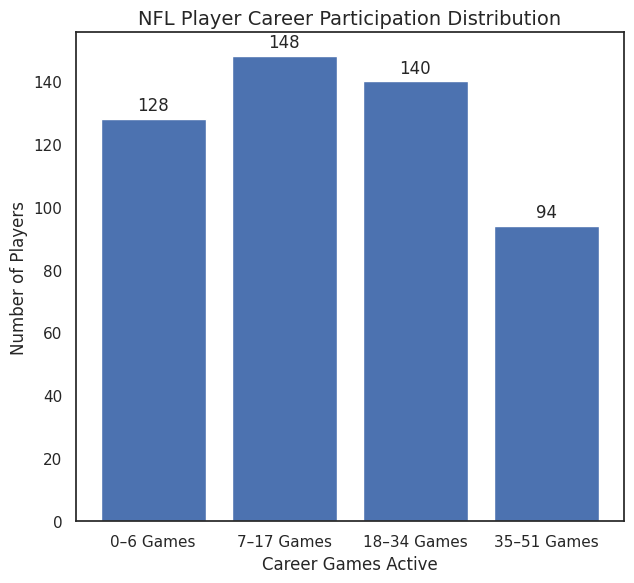

In [840]:
plt.figure(figsize=(6.5,6)),
bars = plt.bar(
    participation_summary.index.astype(str),
    participation_summary["player_count"]
)

plt.title("NFL Player Career Participation Distribution", fontsize=14)
plt.xlabel("Career Games Active")
plt.ylabel("Number of Players")

plt.bar_label(bars, padding=3)

plt.tight_layout()
plt.show()

### Career Participation Distribution

- The largest group (29.02%) recorded 7–17 active games.
- 25.10% of players recorded 0–6 active games.
- Only 18.43% reached the highest participation range (35–51 games).
- Overall, 54.12% of players recorded 17 or fewer active games.

**Insight:** Career participation varies considerably across the player sample. These groups describe observed participation, not definitive career success or failure.

In [841]:
draft_year_summary = (
    combine_career_df
    .groupby("draft_year")["career_games_active"]
    .agg(
        player_count="count",
        mean_games="mean",
        median_games="median",
        max_games="max"
    )
    .round(2)
)

display(draft_year_summary)

,player_count,mean_games,median_games,max_games
draft_year,,,,
2023,160,33.06,40.5,51
2024,177,21.94,26.0,35
2025,173,11.01,17.0,17


In [842]:
position_career_summary = (
    combine_career_df
    .groupby("combine_position")["career_games_active"]
    .agg(
        player_count="count",
        mean_games="mean",
        median_games="median",
        max_games="max"
    )
    .round(2)
    .sort_values("mean_games", ascending=False)
)

display(position_career_summary)

,player_count,mean_games,median_games,max_games
combine_position,,,,
WR,107,22.50,17.0,51
DL,118,22.00,17.0,51
TE,42,21.67,17.0,51
DB,122,21.45,17.0,51
OL,121,21.06,17.0,51


In [843]:
combine_metrics = [
    "ten_yd_split",
    "forty",
    "vertical",
    "broad_jump",
    "three_cone"
]

# Compare career participation within each draft class
combine_career_df["career_participation_percentile"] = (
    combine_career_df
    .groupby("draft_year")["career_games_active"]
    .rank(pct=True) * 100
)

# Evaluate Combine metrics against adjusted career participation
results = []

for metric in combine_metrics:
    subset = combine_career_df[
        [metric, "career_participation_percentile"]
    ].dropna()

    results.append({
        "Combine Metric": metric,
        "Sample Size": len(subset),
        "Spearman Correlation": subset[metric].corr(
            subset["career_participation_percentile"],
            method="spearman"
        )
    })

adjusted_correlation_df = (
    pd.DataFrame(results)
    .sort_values(
        "Spearman Correlation",
        key=lambda x: x.abs(),
        ascending=False
    )
    .round(3)
)

display(adjusted_correlation_df)

,Combine Metric,Sample Size,Spearman Correlation
2,vertical,438,0.156
1,forty,424,-0.128
3,broad_jump,423,0.104
0,ten_yd_split,425,-0.099
4,three_cone,180,-0.088


### **Draft-Year Adjusted Combine Performance Analysis**

- Vertical jump showed the strongest positive association with relative career participation (0.156).
- The 40-yard dash showed a weak negative association (-0.128).
- All five Combine metrics demonstrated weak correlations.
- Three-cone analysis had a smaller sample size of 180 players.

**Insight:** Individual Combine test results showed limited standalone associations with career participation after comparing players within their draft classes. Multiple features and movement-based measurements require further evaluation.

In [844]:
sensor_features = combine_player_summary.rename(
    columns={
        "s": "combine_tracking_speed",
        "a": "combine_tracking_acceleration",
        "dis": "combine_tracking_distance"
    }
)

prediction_df = combine_career_df.merge(
    sensor_features,
    on="nfl_id",
    how="inner"
)

prediction_columns = [
    "ten_yd_split",
    "forty",
    "vertical",
    "broad_jump",
    "combine_tracking_speed",
    "combine_tracking_acceleration",
    "combine_tracking_distance"
]

print("Prediction Dataset:", prediction_df.shape)

print("\nDraft Year Distribution:")
display(prediction_df["draft_year"].value_counts().sort_index().to_frame("Players"))

print("\nFeature Missing Values:")
display(prediction_df[prediction_columns].isna().sum().to_frame("Missing Values"))

Prediction Dataset: (497, 31)

Draft Year Distribution:


,Players
draft_year,
2023,158
2024,175
2025,164



Feature Missing Values:


,Missing Values
ten_yd_split,83
forty,84
vertical,68
broad_jump,83
combine_tracking_speed,0
combine_tracking_acceleration,0
combine_tracking_distance,0


In [845]:
terms = [
    "pressure", "hurry", "sack",
    "rush", "pass", "block", "tackle"
]

relevant_play_cols = [
    col for col in player_play_df.columns
    if any(term in col.lower() for term in terms)
]

print("Relevant NFL Play Features:")
print(relevant_play_cols)

print("\nDefensive Line Combine Drills:")

dl_drills = (
    combine_tracking_matched.loc[
        combine_tracking_matched["drill_type"].str.contains(
            "DL", case=False, na=False
        ),
        ["drill_type", "drill_name"]
    ]
    .drop_duplicates()
    .sort_values(["drill_type", "drill_name"])
)

display(dl_drills)

Relevant NFL Play Features:
['pass_result', 'pass_length', 'rush_yards', 'separation_at_pass_forward', 'extended_sack_allowed', 'pass_rushers_encountered', 'peak_pressure_probability_allowed', 'pressure_allowed', 'sack_allowed', 'time_to_pressure_allowed', 'quick_pressure', 'unblocked_pressure', 'sack', 'tackle', 'tackle_for_loss', 'time_to_pressure', 'time_to_qb_hurry']

Defensive Line Combine Drills:


,drill_type,drill_name
38634,SKILL_DRILLS_DL,BACK_PEDAL_AND_REACT
25827,SKILL_DRILLS_DL,BODY_CONTROL_DRILL
25526,SKILL_DRILLS_DL,FOUR_BAG_AGILITY_DRILL
25619,SKILL_DRILLS_DL,FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION
25363,SKILL_DRILLS_DL,PASS_RUSH_DRILL
25452,SKILL_DRILLS_DL,RUN_AND_CLUB_DRILL
25285,SKILL_DRILLS_DL,RUN_THE_HOOP_DRILL
190670,SKILL_DRILLS_DL,SHORT_ZONE_BREAKS
38140,SKILL_DRILLS_DL,SHORT_ZONE_BREAK_FLAT_WHEEL
37933,SKILL_DRILLS_DL,SHORT_ZONE_BREAK_FORWARD


In [846]:
dl_players = combine_results_df[
    combine_results_df["combine_position"] == "DL"
]["nfl_id"].unique()

dl_combine = combine_tracking_matched[
    (combine_tracking_matched["nfl_id"].isin(dl_players)) &
    (combine_tracking_matched["drill_type"] == "SKILL_DRILLS_DL")
]

dl_nfl = nfl_tracking_matched[
    nfl_tracking_matched["nfl_id"].isin(dl_players)
]

print("DEFENSIVE LINE DATA OVERVIEW")
print("=" * 45)

print("DL Players:", len(dl_players))
print("Combine Drill Records:", len(dl_combine))
print("NFL Tracking Records:", len(dl_nfl))

print("Combine Players:", dl_combine["nfl_id"].nunique())
print("NFL Tracked Players:", dl_nfl["nfl_id"].nunique())

DEFENSIVE LINE DATA OVERVIEW
DL Players: 118
Combine Drill Records: 74925
NFL Tracking Records: 4814418
Combine Players: 111
NFL Tracked Players: 115


In [847]:
combine_dl_ids = set(dl_combine["nfl_id"].unique())
nfl_dl_ids = set(dl_dl["nfl_id"].unique()) if "dl_dl" in globals() else set(dl_nfl["nfl_id"].unique())

matched_dl_ids = combine_dl_ids & nfl_dl_ids

dl_play = player_play_df[
    player_play_df["nfl_id"].isin(matched_dl_ids)
]

print("DEFENSIVE LINE PLAYER MATCHING")
print("=" * 45)

print("Combine DL Players:", len(combine_dl_ids))
print("NFL Tracked DL Players:", len(nfl_dl_ids))
print("Matched DL Players:", len(matched_dl_ids))
print("Matched Player-Play Records:", len(dl_play))
print("Players with Player-Play Data:", dl_play["nfl_id"].nunique())

DEFENSIVE LINE PLAYER MATCHING
Combine DL Players: 111
NFL Tracked DL Players: 115
Matched DL Players: 111
Matched Player-Play Records: 65005
Players with Player-Play Data: 111


In [848]:
dl_outcome_cols = [
    "sack",
    "tackle",
    "tackle_for_loss",
    "quick_pressure",
    "unblocked_pressure",
    "pressure_allowed",
    "sack_allowed"
]

available_outcomes = [
    col for col in dl_outcome_cols
    if col in dl_play.columns
]

print("DEFENSIVE PERFORMANCE COLUMN CHECK")
print("=" * 45)

display(
    dl_play[available_outcomes]
    .agg(["count", "nunique"])
    .T
    .rename(columns={
        "count": "Available Values",
        "nunique": "Unique Values"
    })
)

DEFENSIVE PERFORMANCE COLUMN CHECK


,Available Values,Unique Values
sack,35525,3
tackle,4125,3
tackle_for_loss,4125,2
quick_pressure,3148,2
unblocked_pressure,35527,2
pressure_allowed,0,0
sack_allowed,0,0


In [849]:
check_cols = [
    "sack",
    "tackle",
    "tackle_for_loss",
    "quick_pressure",
    "unblocked_pressure"
]

for col in check_cols:
    print(f"\n{col.upper()}")
    print("-" * 30)
    display(dl_play[col].value_counts(dropna=False))

print("\nPLAYER ROLE / POSITION COLUMNS")
print("-" * 30)

role_cols = [
    col for col in dl_play.columns
    if any(term in col.lower()
           for term in ["position", "role", "defense", "offense"])
]

print(role_cols)


SACK
------------------------------


sack
0.0    35065
NaN    29480
1.0      356
0.5      104
Name: count, dtype: int64


TACKLE
------------------------------


tackle
NaN    60880
1.0     2121
0.0     2003
2.0        1
Name: count, dtype: int64


TACKLE_FOR_LOSS
------------------------------


tackle_for_loss
NaN      60880
False     3485
True       640
Name: count, dtype: int64


QUICK_PRESSURE
------------------------------


quick_pressure
NaN      61857
False     2243
True       905
Name: count, dtype: int64


UNBLOCKED_PRESSURE
------------------------------


unblocked_pressure
False    35243
NaN      29478
True       284
Name: count, dtype: int64


PLAYER ROLE / POSITION COLUMNS
------------------------------
['lined_up_position', 'offense_formation']


In [850]:
print("LINED-UP POSITION DISTRIBUTION")
print("=" * 40)

display(
    dl_play["lined_up_position"]
    .value_counts(dropna=False)
)

print("\nSACK RECORDS WITH POSITION")
print("=" * 40)

display(
    dl_play.loc[
        dl_play["sack"].notna(),
        ["nfl_id", "lined_up_position", "sack"]
    ].head(15)
)

print("\nQUICK PRESSURE RECORDS WITH POSITION")
print("=" * 40)

display(
    dl_play.loc[
        dl_play["quick_pressure"].notna(),
        ["nfl_id", "lined_up_position", "quick_pressure"]
    ].head(15)
)

LINED-UP POSITION DISTRIBUTION


lined_up_position
EDGE             33884
INTERIOR_LINE    30009
SLOT_CB            583
NaN                357
MLB                 81
OLB                 54
CB                  36
TE                   1
Name: count, dtype: int64


SACK RECORDS WITH POSITION


,nfl_id,lined_up_position,sack
2,57140,EDGE,0.0
9,57434,INTERIOR_LINE,0.0
12,57156,INTERIOR_LINE,0.0
25,58248,INTERIOR_LINE,0.0
27,57148,INTERIOR_LINE,0.0
37,55919,INTERIOR_LINE,0.0
52,56497,INTERIOR_LINE,0.0
55,58348,INTERIOR_LINE,0.0
56,55914,INTERIOR_LINE,0.0
82,57364,INTERIOR_LINE,0.0



QUICK PRESSURE RECORDS WITH POSITION


,nfl_id,lined_up_position,quick_pressure
177,57215,EDGE,True
285,57160,INTERIOR_LINE,False
365,55995,INTERIOR_LINE,False
397,55879,EDGE,False
486,55914,INTERIOR_LINE,True
584,55914,INTERIOR_LINE,False
628,55911,INTERIOR_LINE,False
630,55911,INTERIOR_LINE,False
651,57142,EDGE,False
842,57156,INTERIOR_LINE,False


In [851]:
dl_positions = dl_play[
    dl_play["lined_up_position"].isin(
        ["EDGE", "INTERIOR_LINE"]
    )
].copy()

print("DL POSITION OUTCOME SUMMARY")
print("=" * 45)

outcome_summary = []

for position, group in dl_positions.groupby("lined_up_position"):

    outcome_summary.append({
        "Position": position,
        "Records": len(group),
        "Sack Recorded": group["sack"].notna().sum(),
        "Sack Positive": (group["sack"] > 0).sum(),
        "Quick Pressure Recorded": group["quick_pressure"].notna().sum(),
        "Quick Pressure Positive": (group["quick_pressure"] == True).sum(),
        "TFL Positive": (group["tackle_for_loss"] == True).sum(),
        "Unblocked Pressure Positive": (group["unblocked_pressure"] == True).sum()
    })

display(pd.DataFrame(outcome_summary))

DL POSITION OUTCOME SUMMARY


,Position,Records,Sack Recorded,Sack Positive,Quick Pressure Recorded,Quick Pressure Positive,TFL Positive,Unblocked Pressure Positive
0,EDGE,33884,18909,290,1991,614,401,252
1,INTERIOR_LINE,30009,16209,170,1144,290,235,29


In [852]:
dl_player_outcomes = (
    dl_positions.groupby("nfl_id")
    .agg(
        sack_records=("sack", "count"),
        sack_total=("sack", "sum"),
        quick_pressure_records=("quick_pressure", "count"),
        quick_pressure_rate=("quick_pressure", "mean"),
        tackle_for_loss_records=("tackle_for_loss", "count"),
        tackle_for_loss_total=("tackle_for_loss", "sum")
    )
    .reset_index()
)

dl_player_outcomes["sack_rate"] = (
    dl_player_outcomes["sack_total"] /
    dl_player_outcomes["sack_records"]
)

print("PLAYER-LEVEL OUTCOME COVERAGE")
print("=" * 40)

display(
    dl_player_outcomes[
        [
            "sack_records",
            "quick_pressure_records",
            "tackle_for_loss_records"
        ]
    ].describe()
)

print("\nPlayers with recorded outcomes:")
print("Sack:", dl_player_outcomes["sack_records"].gt(0).sum())
print("Quick Pressure:", dl_player_outcomes["quick_pressure_records"].gt(0).sum())
print("Tackle for Loss:", dl_player_outcomes["tackle_for_loss_records"].gt(0).sum())

PLAYER-LEVEL OUTCOME COVERAGE


,sack_records,quick_pressure_records,tackle_for_loss_records
count,111.000000,111.000000,111.000000
mean,316.378378,28.243243,36.630631
std,333.979587,38.439141,39.436930
min,15.000000,0.000000,1.000000
25%,88.500000,5.000000,8.500000
50%,210.000000,13.000000,25.000000
75%,382.500000,31.500000,47.500000
max,1607.000000,189.000000,201.000000



Players with recorded outcomes:
Sack: 111
Quick Pressure: 110
Tackle for Loss: 111


In [853]:
dl_pass_rush = combine_tracking_matched[
    (combine_tracking_matched["nfl_id"].isin(matched_dl_ids)) &
    (combine_tracking_matched["drill_type"] == "SKILL_DRILLS_DL") &
    (combine_tracking_matched["drill_name"].str.contains(
        "PASS_RUSH", case=False, na=False
    ))
].copy()

print("PASS RUSH DRILL COVERAGE")
print("=" * 40)

print("Tracking Records:", len(dl_pass_rush))
print("Players:", dl_pass_rush["nfl_id"].nunique())

display(
    dl_pass_rush.groupby("drill_name")
    .agg(
        players=("nfl_id", "nunique"),
        records=("nfl_id", "size"),
        attempts=("attempt", "nunique")
    )
    .reset_index()
)

PASS RUSH DRILL COVERAGE
Tracking Records: 9583
Players: 111


,drill_name,players,records,attempts
0,PASS_RUSH_DRILL,111,9583,5


In [854]:
attempt_coverage = (
    dl_pass_rush.groupby(["nfl_id", "attempt"])
    .size()
    .reset_index(name="frames")
)

player_attempts = (
    attempt_coverage.groupby("nfl_id")
    .agg(
        attempts_completed=("attempt", "nunique"),
        mean_frames_per_attempt=("frames", "mean")
    )
    .reset_index()
)

print("PASS RUSH ATTEMPT COVERAGE")
print("=" * 40)

display(
    player_attempts["attempts_completed"]
    .value_counts()
    .sort_index()
    .rename_axis("Attempts per Player")
    .reset_index(name="Players")
)

print("\nPlayer attempt summary:")
display(player_attempts.describe().round(2))

PASS RUSH ATTEMPT COVERAGE


,Attempts per Player,Players
0,1,12
1,2,98
2,3,1



Player attempt summary:


,nfl_id,attempts_completed,mean_frames_per_attempt
count,111.00,111.00,111.00
mean,57393.72,1.90,45.55
std,976.44,0.33,5.75
min,55877.00,1.00,39.00
25%,56503.50,2.00,43.00
50%,57342.00,2.00,44.50
75%,58329.50,2.00,47.00
max,58963.00,3.00,92.00


In [855]:
# Attempt-level movement summary
pass_rush_attempt_summary = (
    dl_pass_rush.groupby(["nfl_id", "attempt"])
    .agg(
        mean_speed=("s", "mean"),
        peak_speed=("s", "max"),
        mean_acceleration=("a", "mean"),
        total_distance=("dis", "sum")
    )
    .reset_index()
)

# Player-level summary across attempts
pass_rush_player_summary = (
    pass_rush_attempt_summary.groupby("nfl_id")
    .agg(
        mean_speed=("mean_speed", "mean"),
        peak_speed=("peak_speed", "mean"),
        mean_acceleration=("mean_acceleration", "mean"),
        mean_total_distance=("total_distance", "mean"),
        attempts=("attempt", "nunique")
    )
    .reset_index()
)

print("PASS RUSH PLAYER MOVEMENT SUMMARY")
print("=" * 45)

print("Players:", pass_rush_player_summary["nfl_id"].nunique())

display(
    pass_rush_player_summary.describe().round(3)
)

PASS RUSH PLAYER MOVEMENT SUMMARY
Players: 111


,nfl_id,mean_speed,peak_speed,mean_acceleration,mean_total_distance,attempts
count,111.000,111.000,111.000,111.000,111.000,111.000
mean,57393.721,4.953,7.611,2.941,12.678,1.901
std,976.443,0.344,0.427,0.288,0.808,0.329
min,55877.000,3.732,6.510,2.395,11.043,1.000
25%,56503.500,4.694,7.299,2.719,12.148,2.000
50%,57342.000,4.935,7.643,2.930,12.584,2.000
75%,58329.500,5.159,7.845,3.110,13.041,2.000
max,58963.000,5.679,8.672,3.759,16.418,3.000


In [856]:
# Create player-level TFL rate from recorded values
dl_player_outcomes["tfl_rate"] = (
    dl_player_outcomes["tackle_for_loss_total"] /
    dl_player_outcomes["tackle_for_loss_records"]
)

# Merge Combine movement with NFL outcomes
dl_research_df = pass_rush_player_summary.merge(
    dl_player_outcomes[
        [
            "nfl_id",
            "sack_rate",
            "quick_pressure_rate",
            "tfl_rate"
        ]
    ],
    on="nfl_id",
    how="inner"
)

movement_features = [
    "mean_speed",
    "peak_speed",
    "mean_acceleration",
    "mean_total_distance"
]

performance_outcomes = [
    "sack_rate",
    "quick_pressure_rate",
    "tfl_rate"
]

print("DL PASS RUSH RESEARCH DATA")
print("=" * 40)
print("Matched players:", dl_research_df["nfl_id"].nunique())

# Spearman correlations and valid player counts
corr_results = []

for movement in movement_features:
    for outcome in performance_outcomes:
        valid = dl_research_df[[movement, outcome]].dropna()

        corr_results.append({
            "Movement Feature": movement,
            "NFL Outcome": outcome,
            "Players": len(valid),
            "Spearman Correlation": valid[movement].corr(
                valid[outcome],
                method="spearman"
            )
        })

dl_corr_results = pd.DataFrame(corr_results)

display(
    dl_corr_results.sort_values(
        "Spearman Correlation",
        key=lambda x: x.abs(),
        ascending=False
    ).round(3)
)

DL PASS RUSH RESEARCH DATA
Matched players: 111


,Movement Feature,NFL Outcome,Players,Spearman Correlation
6,mean_acceleration,sack_rate,111,0.295
7,mean_acceleration,quick_pressure_rate,110,0.280
9,mean_total_distance,sack_rate,111,0.279
0,mean_speed,sack_rate,111,0.263
3,peak_speed,sack_rate,111,0.212
1,mean_speed,quick_pressure_rate,110,0.159
5,peak_speed,tfl_rate,111,0.157
11,mean_total_distance,tfl_rate,111,0.152
2,mean_speed,tfl_rate,111,0.122
8,mean_acceleration,tfl_rate,111,0.098


In [857]:
# Assign each player their most frequent DL lineup position
dominant_role = (
    dl_positions.groupby(["nfl_id", "lined_up_position"])
    .size()
    .reset_index(name="role_records")
    .sort_values("role_records")
    .drop_duplicates("nfl_id", keep="last")
    .rename(columns={"lined_up_position": "dominant_role"})
)

# Keep records matching each player's dominant role
dominant_dl_play = dl_positions.merge(
    dominant_role[["nfl_id", "dominant_role"]],
    on="nfl_id",
    how="inner"
)

dominant_dl_play = dominant_dl_play[
    dominant_dl_play["lined_up_position"]
    == dominant_dl_play["dominant_role"]
]

# Calculate position-specific player outcomes
role_outcomes = (
    dominant_dl_play.groupby(["nfl_id", "dominant_role"])
    .agg(
        sack_rate=("sack", "mean"),
        quick_pressure_rate=("quick_pressure", "mean"),
        tfl_rate=("tackle_for_loss", "mean")
    )
    .reset_index()
)

role_research = pass_rush_player_summary.merge(
    role_outcomes,
    on="nfl_id",
    how="inner"
)

role_corr_results = []

for role, group in role_research.groupby("dominant_role"):
    for feature in movement_features:
        for outcome in performance_outcomes:
            valid = group[[feature, outcome]].dropna()

            role_corr_results.append({
                "Role": role,
                "Movement Feature": feature,
                "NFL Outcome": outcome,
                "Players": len(valid),
                "Spearman Correlation": valid[feature].corr(
                    valid[outcome],
                    method="spearman"
                )
            })

role_corr_df = pd.DataFrame(role_corr_results)

display(
    role_corr_df[
        role_corr_df["Movement Feature"].isin(
            ["mean_acceleration", "mean_speed"]
        )
    ].round(3)
)

,Role,Movement Feature,NFL Outcome,Players,Spearman Correlation
0,EDGE,mean_speed,sack_rate,53,0.183
1,EDGE,mean_speed,quick_pressure_rate,53,-0.011
2,EDGE,mean_speed,tfl_rate,53,0.106
6,EDGE,mean_acceleration,sack_rate,53,0.114
7,EDGE,mean_acceleration,quick_pressure_rate,53,0.085
8,EDGE,mean_acceleration,tfl_rate,53,-0.067
12,INTERIOR_LINE,mean_speed,sack_rate,58,0.150
13,INTERIOR_LINE,mean_speed,quick_pressure_rate,57,0.173
14,INTERIOR_LINE,mean_speed,tfl_rate,58,-0.008
18,INTERIOR_LINE,mean_acceleration,sack_rate,58,0.214


In [858]:
# 1. Combine pass-rush acceleration per player
dl_acceleration = (
    dl_pass_rush[dl_pass_rush["entity_type"] == "PLAYER"]
    .groupby("nfl_id", as_index=False)
    .agg(combine_pass_rush_acceleration=("a", "mean"))
)

# 2. Player role map
dl_role_map = (
    dl_positions.groupby("nfl_id")["lined_up_position"]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index()
)

# 3. Merge acceleration, role, and NFL quick pressure rate
dl_scatter_df = (
    dl_acceleration
    .merge(dl_role_map, on="nfl_id", how="inner")
    .merge(
        dl_player_outcomes[["nfl_id", "quick_pressure_rate"]],
        on="nfl_id",
        how="inner"
    )
    .dropna(subset=[
        "combine_pass_rush_acceleration",
        "quick_pressure_rate",
        "lined_up_position"
    ])
)

# Keep only EDGE and Interior Line
dl_scatter_df = dl_scatter_df[
    dl_scatter_df["lined_up_position"].isin(["EDGE", "INTERIOR_LINE"])
]

print("Players:", dl_scatter_df["nfl_id"].nunique())
print(dl_scatter_df["lined_up_position"].value_counts())

Players: 110
lined_up_position
INTERIOR_LINE    57
EDGE             53
Name: count, dtype: int64


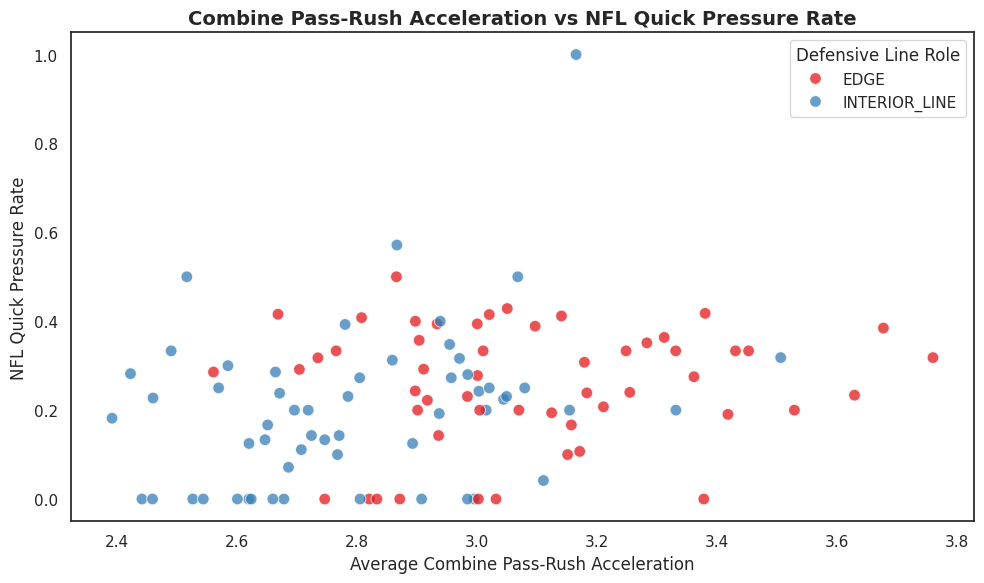

In [859]:
# 1. Keep player records from Combine pass-rush drill
pass_rush_players = dl_pass_rush[
    dl_pass_rush["entity_type"] == "PLAYER"
].copy()

# 2. Calculate average pass-rush acceleration per player
combine_acceleration = (
    pass_rush_players
    .groupby("nfl_id", as_index=False)
    .agg(mean_acceleration=("a", "mean"))
)

# 3. Get each player's defensive line role
player_roles = (
    dl_positions
    .groupby("nfl_id")["lined_up_position"]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index()
)

# 4. Merge acceleration with role
combine_acceleration = combine_acceleration.merge(
    player_roles,
    on="nfl_id",
    how="left"
)

# 5. Merge with NFL quick pressure rate
dl_scatter = combine_acceleration.merge(
    dl_player_outcomes[["nfl_id", "quick_pressure_rate"]],
    on="nfl_id",
    how="inner"
)

# 6. Keep EDGE and Interior Line
dl_scatter = dl_scatter[
    dl_scatter["lined_up_position"].isin(
        ["EDGE", "INTERIOR_LINE"]
    )
]

# 7. Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=dl_scatter,
    x="mean_acceleration",
    y="quick_pressure_rate",
    hue="lined_up_position",
    palette="Set1",
    alpha=0.75,
    s=70
)

plt.title(
    "Combine Pass-Rush Acceleration vs NFL Quick Pressure Rate",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average Combine Pass-Rush Acceleration")
plt.ylabel("NFL Quick Pressure Rate")
plt.legend(title="Defensive Line Role")

plt.tight_layout()
plt.show()

### **Position-wise Visualization and Interpretation**

Players with similar Combine acceleration showed different quick-pressure rates in the NFL. Higher acceleration did not always lead to more pressure.

The relationship was stronger for Interior Line (+0.281) than EDGE (+0.085), but the overall pattern was still weak.

In football, the Combine measures movement in a controlled drill, while NFL pass rushing requires beating offensive linemen during real plays. Acceleration may help, but it is not enough on its own to explain pass-rush success.

Overall, Combine acceleration showed a limited connection with NFL quick pressure, especially for Interior Line players. These results are exploratory and should not be used alone to predict performance.

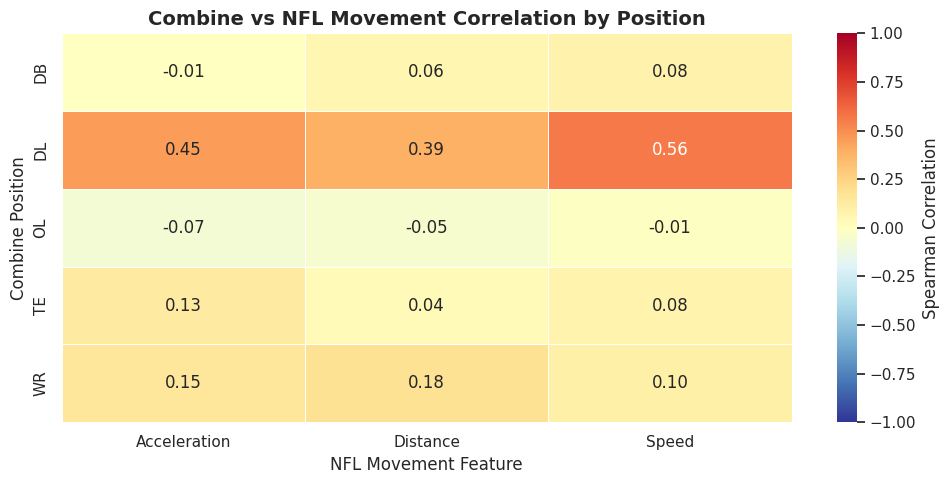

In [860]:
# Prepare correlation data
position_corr_pivot = position_corr_df.pivot(
    index="Position",
    columns="Feature",
    values="Correlation"
)

# Rename features for readability
position_corr_pivot = position_corr_pivot.rename(
    columns={
        "a": "Acceleration",
        "dis": "Distance",
        "s": "Speed"
    }
)

# Create final heatmap
plt.figure(figsize=(10, 5))

sns.heatmap(
    position_corr_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Spearman Correlation"}
)

plt.title(
    "Combine vs NFL Movement Correlation by Position",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("NFL Movement Feature")
plt.ylabel("Combine Position")

plt.tight_layout()
plt.show()

### **Key Finding: Combine Movement Metrics Vary in Predictive Value by Position**

This heatmap shows how closely Combine movement metrics are related to movement in the NFL across different positions. Defensive Linemen show stronger correlations than most other positions, suggesting that Combine results may provide more useful movement insights for certain positions. However, the relationships are not equally strong across all positions, so Combine performance should not be treated as a reliable indicator for every player.

### **Predictive Modeling Evaluation – Baseline vs Random Forest**

In [861]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

import pandas as pd

# Target: career participation percentile
TARGET = "career_participation_percentile"

# Combine features only
features = prediction_columns.copy()

# Prepare data
data = prediction_df[features + [TARGET]].copy()
data = data.dropna(subset=[TARGET])

X = data[features]
y = data[TARGET]

# Same cross-validation splits for both models
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Baseline: predicts average target value
baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    DummyRegressor(strategy="mean")
)

# ML model
model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42
    )
)

# Evaluate using MAE (lower is better)
baseline_mae = -cross_val_score(
    baseline, X, y,
    cv=cv,
    scoring="neg_mean_absolute_error"
).mean()

model_mae = -cross_val_score(
    model, X, y,
    cv=cv,
    scoring="neg_mean_absolute_error"
).mean()

# Evaluate using R² (higher is better)
baseline_r2 = cross_val_score(
    baseline, X, y,
    cv=cv,
    scoring="r2"
).mean()

model_r2 = cross_val_score(
    model, X, y,
    cv=cv,
    scoring="r2"
).mean()

improvement = (
    (baseline_mae - model_mae) / baseline_mae * 100
    if baseline_mae != 0 else 0
)

print("Target:", TARGET)
print("Players evaluated:", len(data))
print("Features used:", features)
print("--------------------------------")
print(f"Baseline MAE: {baseline_mae:.3f}")
print(f"ML Model MAE: {model_mae:.3f}")
print(f"Baseline R²:  {baseline_r2:.3f}")
print(f"ML Model R²:  {model_r2:.3f}")
print(f"MAE improvement: {improvement:.2f}%")


Target: career_participation_percentile
Players evaluated: 497
Features used: ['ten_yd_split', 'forty', 'vertical', 'broad_jump', 'combine_tracking_speed', 'combine_tracking_acceleration', 'combine_tracking_distance']
--------------------------------
Baseline MAE: 24.541
ML Model MAE: 24.342
Baseline R²:  -0.005
ML Model R²:  -0.035
MAE improvement: 0.81%


### **Interpretation & Conclusion**

The Random Forest model achieved an MAE of 24.342 compared to 24.541 for the baseline, showing only a 0.81% improvement. Its R² score (-0.035) was also lower than the baseline (-0.005).

These results indicate that the selected seven Combine features have limited predictive value for career participation percentile in this experiment.

Therefore, the Random Forest model is not considered a reliable predictive model for this research. However, the experiment is retained to document the evaluation and support an evidence-based decision.

### **Final Conclusion — From Combine Testing to NFL Reality**

### What Does Athletic Potential Really Tell Us?

This research connected nine datasets and 497 matched players to investigate one central question: **Which Combine movement traits show the strongest relationship with actual NFL performance?**

**1. Football Finding — Does Combine movement translate to the NFL?**

Speed and distance showed the strongest Combine-to-NFL movement relationships, with correlations of **0.911** and **0.901**, respectively. Acceleration showed a weaker relationship (**0.332**), suggesting that not every athletic trait transfers equally into game situations.

**2. Position-Specific Finding — Does the same athletic trait matter for every player?**

No. Among 111 Defensive Line players, average acceleration showed positive associations with sack rate (**0.295**) and quick pressure rate (**0.280**). Its relationship with quick pressure was stronger for Interior Linemen (**0.281**) than EDGE players (**0.085**). This highlights why scouting should consider positional responsibilities rather than rely on universal athletic rankings.

**3. Data Science Finding — Can Combine metrics predict career participation?**

A Random Forest model using seven Combine features improved MAE by only **0.81%** over the baseline, while its R² was negative (**-0.035**). The selected features therefore did not provide reliable career participation predictions. This limitation was retained as an important research result rather than overstating model performance.

### The Final Scouting Takeaway

**The Combine measures potential; NFL tracking reveals how movement appears in real competition.** The strongest insight from this research is that athletic traits become more meaningful when evaluated alongside actual game movement, positional demands, and career context.

A Combine result should not be treated as a verdict on a player's future. It should be the beginning of a more informed scouting evaluation.